# Labo 8 : introduction à PyTorch

IFT3395 / IFT6390A · mardi 17 novembre 2026, 14 h 30 à 16 h 30

### Le code est visible, en petites cellules : lisez-le, exécutez-le dans l'ordre, modifiez-le. 🔮 annonce une prédiction à faire avant d'exécuter, ✏️ une modification à essayer. Dans Colab, allumez le GPU (Exécution, Modifier le type d'exécution, GPU T4), puis exécutez la boîte à outils ci-dessous : elle importe `torch`, `plt` (matplotlib) et `time`, et charge les données.

In [1]:
#@title Boîte à outils du labo (exécutez cette cellule une fois). Cliquez sur « Afficher le code » pour la lire. { display-mode: "form" }
# ============================================================================================
#  Labo PyTorch. Tout le code des démos est ici, commenté ligne par ligne.
#  Rien à compléter : le labo se lit, et les curseurs se bougent.
# ============================================================================================
import sys, time  # savoir si on est dans Colab ; chronométrer
import numpy as np  # calcul sur des tableaux (ce qu'on utilisait jusqu'ici)
import matplotlib.pyplot as plt  # figures
import ipywidgets as widgets  # curseurs et menus des démos
from IPython.display import display  # affichage des panneaux
from matplotlib.colors import ListedColormap  # couleurs des régions de décision
%matplotlib inline

import torch  # la bibliothèque du jour
import torch.nn as nn  # les briques de réseaux de neurones (couches, pertes)
from sklearn import datasets  # iris et digits, comme au labo 6
from sklearn.model_selection import train_test_split  # découpage entraînement / test
from sklearn.preprocessing import OneHotEncoder  # étiquette 2 -> [0, 0, 1]

np.set_printoptions(precision=3, suppress=True)  # tableaux lisibles
torch.set_printoptions(precision=3, sci_mode=False)  # tenseurs lisibles
IN_COLAB = 'google.colab' in sys.modules  # vrai dans Colab
GPU_DISPONIBLE = torch.cuda.is_available()  # vrai si Colab a une carte graphique allumée
plt.rcParams.update({'font.size': 13, 'axes.titlesize': 14, 'axes.labelsize': 13, 'figure.dpi': 100})  # polices lisibles

# ---- couleurs fixes, les mêmes dans toutes les figures ----
BLEU, ORANGE, VERT, ROUGE, GRIS, VIOLET = '#2563eb', '#ea580c', '#16a34a', '#dc2626', '#6b7280', '#7c3aed'
CMAP2 = ListedColormap(['#bfdbfe', '#fed7aa'])  # régions de décision à deux classes, versions pâles
NOMS = ['setosa', 'versicolor', 'virginica']  # les trois espèces d'iris


def panneau(fonction, **controles):
    """Affiche des curseurs (ou des menus) au-dessus d'une figure qui se redessine à chaque changement."""
    for controle in controles.values():
        controle.style = {'description_width': '280px'}  # place pour l'étiquette entière
        controle.layout = widgets.Layout(width='680px')  # curseur long, donc précis
        if hasattr(controle, 'continuous_update'):
            controle.continuous_update = False  # on redessine au relâchement
    sortie = widgets.interactive_output(fonction, controles)  # la figure
    display(widgets.VBox(list(controles.values()) + [sortie]))  # contrôles empilés, puis la figure


# ============================ les données ============================
iris = datasets.load_iris()  # 150 fleurs, 4 mesures, 3 espèces
# même découpage que la démo officielle (75 % / 25 %), avec une graine fixe pour que tout le monde ait les mêmes chiffres
_xa, _xt, _ca, _ct = train_test_split(iris.data, iris.target, random_state=0)
_un_chaud = OneHotEncoder(sparse_output=False)  # 0 -> [1,0,0], 1 -> [0,1,0], 2 -> [0,0,1]
iris_x_train = torch.from_numpy(_xa).float()  # 112 fleurs x 4 mesures, en tenseur de nombres à virgule
iris_x_test = torch.from_numpy(_xt).float()  # 38 fleurs x 4 mesures
iris_y_train = torch.from_numpy(_un_chaud.fit_transform(_ca.reshape(-1, 1))).float()  # 112 x 3, une colonne par espèce
iris_y_test = torch.from_numpy(_un_chaud.transform(_ct.reshape(-1, 1))).float()  # 38 x 3
iris_c_train, iris_c_test = torch.from_numpy(_ca), torch.from_numpy(_ct)  # les numéros d'espèce (0, 1, 2)

digits = datasets.load_digits()  # 1797 chiffres manuscrits 8 x 8, 10 classes
_xa, _xt, _ca, _ct = train_test_split(digits.data, digits.target, random_state=0)
digits_x_train, digits_x_test = torch.from_numpy(_xa).float(), torch.from_numpy(_xt).float()  # 1347 x 64 et 450 x 64
digits_c_train, digits_c_test = torch.from_numpy(_ca).long(), torch.from_numpy(_ct).long()  # le chiffre écrit, 0 à 9


def exactitude(scores, classes):
    """Pourcentage de lignes dont le plus grand score tombe sur la bonne classe."""
    return 100 * (scores.argmax(dim=1) == classes).float().mean().item()


# ============================ démo A : le temps d'une multiplication de matrices ============================
def demo_gpu():
    tailles = [250, 500, 1000, 2000, 3000]  # matrices carrées de plus en plus grandes
    appareils = ['cpu'] + (['cuda'] if GPU_DISPONIBLE else [])
    temps = {a: [] for a in appareils}
    for a in appareils:
        for n in tailles:
            A, B = torch.randn(n, n, device=a), torch.randn(n, n, device=a)  # deux matrices n x n sur l'appareil
            if a == 'cuda':
                (A @ B); torch.cuda.synchronize()  # premier appel « à blanc » : le GPU s'échauffe
            debut = time.perf_counter()
            for _ in range(3):
                C = A @ B  # la multiplication matricielle
            if a == 'cuda':
                torch.cuda.synchronize()  # attendre que le GPU ait vraiment fini
            temps[a].append(1000 * (time.perf_counter() - debut) / 3)  # millisecondes par multiplication
    fig, ax = plt.subplots(figsize=(10, 4.5))
    largeur = 0.38
    for i, a in enumerate(appareils):
        ax.bar(np.arange(len(tailles)) + (i - (len(appareils) - 1) / 2) * largeur, temps[a], largeur,
               color=GRIS if a == 'cpu' else VERT, label='processeur (CPU)' if a == 'cpu' else 'carte graphique (GPU)')
        for j, t in enumerate(temps[a]):
            ax.text(j + (i - (len(appareils) - 1) / 2) * largeur, t, f'{t:.1f}' if t < 100 else f'{t:.0f}', ha='center', va='bottom', fontsize=10)
    ax.set_xticks(range(len(tailles))); ax.set_xticklabels([f'{n} x {n}' for n in tailles])
    ax.set_ylabel('millisecondes'); ax.set_xlabel('taille des deux matrices multipliées'); ax.legend()
    ax.set_title('temps d\'une multiplication de matrices' + ('' if GPU_DISPONIBLE else ' (pas de GPU allumé dans cette session)'))
    plt.show()
    if not GPU_DISPONIBLE:
        print('Pas de GPU ici. Dans Colab : Exécution > Modifier le type d\'exécution > GPU T4, puis tout réexécuter.')
    else:
        print(f'Pour 3000 x 3000 : le GPU est environ {temps["cpu"][-1] / temps["cuda"][-1]:.0f} fois plus rapide.')


# ============================ démo B : la pente, calculée par autograd ============================
def _demo_autograd(w):
    x, y = 2.0, 3.0  # une seule donnée : entrée 2, cible 3
    w_t = torch.tensor(float(w), requires_grad=True)  # le paramètre ; requires_grad=True : « suis-moi à la trace »
    perte = (w_t * x - y) ** 2  # prédiction w·x, erreur w·x − y, perte = erreur au carré
    perte.backward()  # autograd remonte le calcul et dépose la pente dans w_t.grad
    pente = w_t.grad.item()
    a_la_main = 2 * (w * x - y) * x  # la même dérivée, par la règle de la chaîne
    ws = np.linspace(-1, 4, 200)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(ws, (ws * x - y) ** 2, color=VIOLET, lw=2.5, label='perte L(w) = (2w − 3)²')
    t = np.linspace(w - 0.9, w + 0.9, 2)
    ax.plot(t, perte.item() + pente * (t - w), color=ORANGE, lw=2.5, label=f'tangente : pente {pente:+.2f}'.replace('.', ','))
    ax.scatter([w], [perte.item()], color=ORANGE, s=90, zorder=5)
    ax.scatter([1.5], [0], color=VERT, s=90, zorder=5, label='le creux : w = 1,5')
    ax.set_ylim(-3, 30); ax.set_xlabel('w'); ax.set_ylabel('perte'); ax.legend(loc='upper center')
    ax.set_title(f'w = {w:.2f} : autograd dit {pente:+.2f} ; à la main, 2·(2w − 3)·2 = {a_la_main:+.2f}'.replace('.', ','))
    plt.show()


def demo_autograd():
    panneau(_demo_autograd, w=widgets.FloatSlider(value=3.0, min=-0.5, max=3.5, step=0.25, description='w (le paramètre)'))


# ============================ démo C : la descente de gradient écrite à la main, selon le pas ============================
def entrainer_iris(taux, epoques=500):
    """La boucle de la démo officielle : 12 poids, perte quadratique, mise à jour à la main. Renvoie les pertes et les poids."""
    torch.manual_seed(0)  # mêmes poids de départ pour tout le monde
    poids = torch.randn(4, 3, requires_grad=True)  # 4 mesures x 3 espèces = 12 nombres tirés au hasard
    pertes = []
    for _ in range(epoques):
        preds = torch.mm(iris_x_train, poids)  # 112 x 3 : un score par fleur et par espèce
        perte = (preds - iris_y_train).pow(2).mean()  # moyenne des erreurs au carré
        pertes.append(perte.item())
        if not np.isfinite(pertes[-1]):
            break  # la perte a explosé : inutile de continuer
        perte.backward()  # gradients dans poids.grad
        with torch.no_grad():  # la mise à jour elle-même ne doit pas être suivie à la trace
            poids -= taux * poids.grad  # un pas dans le sens de la descente
            poids.grad.zero_()  # remise à zéro, sinon les gradients s'additionnent
    return pertes, poids.detach()


def _demo_taux(log_taux):
    taux = 10 ** log_taux
    pertes, poids = entrainer_iris(taux)
    explose = (not np.isfinite(pertes[-1])) or pertes[-1] > pertes[0]
    fig, ax = plt.subplots(figsize=(9.5, 5))
    ax.plot(range(len(pertes)), np.clip(pertes, None, 1e6), color=ROUGE if explose else VIOLET, lw=2.5)
    ax.set_yscale('log'); ax.set_ylim(0.03, 1e3); ax.set_xlim(0, 500)
    ax.set_xlabel('époque (un passage sur les 112 fleurs)'); ax.set_ylabel('perte (échelle logarithmique)')
    ax.axhline(0.222, color=GRIS, ls=':', lw=1); ax.text(498, 0.235, 'répondre 1/3 partout : 0,222', ha='right', color=GRIS, fontsize=10)
    if explose:
        ax.set_title(f'pas = {taux:.5f} : la perte explose, les pas sont trop grands'.replace('.', ','))
    else:
        ex = exactitude(torch.mm(iris_x_test, poids), iris_c_test)
        ax.set_title(f'pas = {taux:.5f} : perte {pertes[0]:.2f} → {pertes[-1]:.3f} en 500 époques ; exactitude de test {ex:.0f} %'.replace('.', ','))
    plt.show()


def demo_taux():
    panneau(_demo_taux, log_taux=widgets.FloatSlider(value=np.log10(2e-4), min=-5, max=-1, step=0.25, readout_format='.2f',
                                                    description='log10(pas) : pas = 0,00001 à 0,1'))


# ============================ démo D : un réseau, sa frontière, et le rôle de la non-linéarité ============================
def _donnees_2d(nom):
    """Trois petits jeux de données à deux mesures et deux classes."""
    rng = np.random.RandomState(0)
    if nom.startswith('XOR'):
        centres = np.array([[0, 0], [1, 1], [0, 1], [1, 0]])  # les quatre coins du XOR vu en cours
        X = np.vstack([c + 0.13 * rng.randn(60, 2) for c in centres]); y = np.repeat([0, 0, 1, 1], 60)
    elif nom.startswith('deux lunes'):
        X, y = datasets.make_moons(240, noise=0.18, random_state=0)
    else:
        X, y = datasets.make_circles(240, noise=0.08, factor=0.45, random_state=0)
    return train_test_split(X.astype(np.float32), y, test_size=60, random_state=0)


def charger_xor():
    """Les 240 points du XOR, en tenseurs : les mesures (240 x 2) et les classes 0 ou 1 (240 x 1)."""
    Xa, Xt, ya, yt = _donnees_2d('XOR')
    X, y = np.vstack([Xa, Xt]), np.concatenate([ya, yt])
    return torch.from_numpy(X), torch.from_numpy(y).float().view(-1, 1)


_ACTIVATIONS = {'aucune': None, 'ReLU': nn.ReLU, 'tanh': nn.Tanh, 'sigmoïde': nn.Sigmoid}


def construire_reseau(entrees, couches, largeur, activation, sorties):
    """Empile `couches` couches cachées de `largeur` neurones, avec l'activation choisie entre elles."""
    etages, taille = [], entrees
    for _ in range(couches):
        etages.append(nn.Linear(taille, largeur))  # une couche linéaire : W x + b
        if _ACTIVATIONS[activation] is not None:
            etages.append(_ACTIVATIONS[activation]())  # la non-linéarité, appliquée à chaque neurone
        taille = largeur
    etages.append(nn.Linear(taille, sorties))  # la couche de sortie
    return nn.Sequential(*etages)


def _demo_frontiere(donnees, activation, largeur, couches, epoques):
    Xa, Xt, ya, yt = _donnees_2d(donnees)
    xa, xt = torch.from_numpy(Xa), torch.from_numpy(Xt)
    ca, ct = torch.from_numpy(ya).float().view(-1, 1), torch.from_numpy(yt).float().view(-1, 1)  # cibles 0 ou 1
    torch.manual_seed(0)
    modele = construire_reseau(2, couches, largeur, activation, 1)  # 2 mesures en entrée, 1 score en sortie
    perte_fn = nn.MSELoss()  # erreur quadratique moyenne
    optimiseur = torch.optim.Adam(modele.parameters(), lr=0.02)  # Adam : une descente de gradient qui règle son pas
    pertes = []
    for _ in range(epoques):
        perte = perte_fn(modele(xa), ca)
        pertes.append(perte.item())
        optimiseur.zero_grad(); perte.backward(); optimiseur.step()  # les trois lignes de toujours
    with torch.no_grad():
        m = 0.35
        xx, yy = np.meshgrid(np.arange(Xa[:, 0].min() - m, Xa[:, 0].max() + m, 0.02), np.arange(Xa[:, 1].min() - m, Xa[:, 1].max() + m, 0.02))
        Z = modele(torch.from_numpy(np.c_[xx.ravel(), yy.ravel()].astype(np.float32))).numpy().reshape(xx.shape)
        ex_a = 100 * ((modele(xa) > 0.5).float() == ca).float().mean().item()
        ex_t = 100 * ((modele(xt) > 0.5).float() == ct).float().mean().item()
    n_param = sum(p.numel() for p in modele.parameters())
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={'width_ratios': [1.25, 1]})
    ax.contourf(xx, yy, (Z > 0.5).astype(int), levels=[-0.5, 0.5, 1.5], cmap=CMAP2)
    ax.contour(xx, yy, Z, levels=[0.5], colors='k', linewidths=1.5)
    for c, coul in enumerate([BLEU, ORANGE]):
        ax.scatter(Xa[ya == c, 0], Xa[ya == c, 1], color=coul, s=22, label=f'classe {c} (entraînement)')
        ax.scatter(Xt[yt == c, 0], Xt[yt == c, 1], color=coul, s=45, marker='x', label=f'classe {c} (test)')
    ax.legend(fontsize=9, loc='upper right'); ax.set_xlabel('mesure 1'); ax.set_ylabel('mesure 2')
    ax.set_title(f'activation : {activation} ; {n_param} paramètres\nexactitude : entraînement {ex_a:.0f} %, test {ex_t:.0f} %')
    if pertes:
        ax2.plot(pertes, color=VIOLET, lw=2.5)
    ax2.set_xlim(0, max(epoques, 1)); ax2.set_ylim(0, 0.6); ax2.set_xlabel('époque'); ax2.set_ylabel('perte quadratique (entraînement)')
    ax2.set_title('la perte pendant l\'entraînement' + (f' : {pertes[0]:.2f} → {pertes[-1]:.3f}'.replace('.', ',') if pertes else ''))
    plt.tight_layout(); plt.show()


def demo_frontiere():
    panneau(_demo_frontiere,
            donnees=widgets.Dropdown(options=['XOR (vu en cours)', 'deux lunes', 'cercles'], description='jeu de données'),
            activation=widgets.Dropdown(options=['aucune', 'ReLU', 'tanh', 'sigmoïde'], description='activation entre les couches'),
            largeur=widgets.IntSlider(value=8, min=1, max=32, description='neurones par couche cachée'),
            couches=widgets.IntSlider(value=1, min=1, max=3, description='nombre de couches cachées'),
            epoques=widgets.IntSlider(value=300, min=0, max=1000, step=50, description='époques d\'entraînement'))


# ============================ démo E : des scores aux probabilités, et l'entropie croisée ============================
def _demo_softmax(score):
    scores = torch.tensor([float(score), 1.0, 0.0])  # trois scores ; la bonne classe est la première
    probas = torch.softmax(scores, dim=0)  # exponentielle de chaque score, divisée par la somme
    perte = -torch.log(probas[0]).item()  # entropie croisée : moins le logarithme de la probabilité de la bonne classe
    fig, (ax, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.4))
    noms = ['classe A\n(la bonne)', 'classe B', 'classe C']; coul = [VERT, GRIS, GRIS]
    ax.bar(noms, scores.numpy(), color=coul); ax.axhline(0, color='k', lw=0.8); ax.set_ylim(-3.5, 6.5); ax.set_title('1. les scores du réseau')
    for i, s in enumerate(scores): ax.text(i, s + (0.15 if s >= 0 else -0.6), f'{s:.1f}'.replace('.', ','), ha='center')
    ax2.bar(noms, probas.numpy(), color=coul); ax2.set_ylim(0, 1.12); ax2.set_title('2. softmax : des probabilités (somme 1)')
    for i, p in enumerate(probas): ax2.text(i, p + 0.02, f'{p:.2f}'.replace('.', ','), ha='center')
    ps = np.linspace(0.005, 1, 300)
    ax3.plot(ps, -np.log(ps), color=VIOLET, lw=2.5); ax3.scatter([probas[0].item()], [perte], color=VERT, s=110, zorder=5)
    ax3.set_ylim(0, 5.5); ax3.set_xlabel('probabilité donnée à la bonne classe'); ax3.set_ylabel('perte')
    ax3.set_title(f'3. perte = −log({probas[0]:.2f}) = {perte:.2f}'.replace('.', ','))
    plt.tight_layout(); plt.show()


def demo_softmax():
    panneau(_demo_softmax, score=widgets.FloatSlider(value=1.0, min=-3, max=6, step=0.5, description='score de la bonne classe'))


# ============================ démo F : reconnaître des chiffres, architecture au choix ============================
def entrainer_digits(couches, largeur, activation, taux, epoques, appareil='cpu'):
    """La boucle complète de la démo officielle sur les chiffres. Renvoie le modèle et les courbes."""
    torch.manual_seed(0)
    modele = construire_reseau(64, couches, largeur, activation, 10).to(appareil)  # 64 pixels en entrée, 10 scores en sortie
    xa, ca, xt, ct = (t.to(appareil) for t in (digits_x_train, digits_c_train, digits_x_test, digits_c_test))
    perte_fn = nn.CrossEntropyLoss()  # softmax puis entropie croisée, en une seule brique
    optimiseur = torch.optim.SGD(modele.parameters(), lr=taux)  # descente de gradient simple, comme la démo officielle
    pertes, pertes_test, quand = [], [], []
    for epoque in range(epoques):
        modele.train()  # mode entraînement
        perte = perte_fn(modele(xa), ca)
        optimiseur.zero_grad(); perte.backward(); optimiseur.step()
        if epoque % 10 == 0 or epoque == epoques - 1:
            modele.eval()  # mode évaluation
            with torch.no_grad():  # pas besoin de gradients pour mesurer
                pertes.append(perte.item()); pertes_test.append(perte_fn(modele(xt), ct).item()); quand.append(epoque)
    modele.eval()
    with torch.no_grad():
        sa, st = modele(xa).cpu(), modele(xt).cpu()
    return modele, quand, pertes, pertes_test, sa, st


def _demo_digits(couches, largeur, activation, log_taux, epoques):
    taux = 10 ** log_taux
    debut = time.perf_counter()
    modele, quand, pertes, pertes_test, sa, st = entrainer_digits(couches, largeur, activation, taux, epoques)
    duree = time.perf_counter() - debut
    n_param = sum(p.numel() for p in modele.parameters())
    fig = plt.figure(figsize=(15, 5.4)); gs = fig.add_gridspec(2, 9, width_ratios=[1] * 5 + [0.25] + [1] * 3)
    ax = fig.add_subplot(gs[:, :5])
    if not np.all(np.isfinite(pertes)):
        ax.text(0.5, 0.5, 'la perte a explosé (pas trop grand)', transform=ax.transAxes, ha='center', color=ROUGE, fontsize=15)
    else:
        ax.plot(quand, pertes, color=BLEU, lw=2.5, label='entraînement (1347 images)')
        ax.plot(quand, pertes_test, color=ORANGE, lw=2.5, label='test (450 images)')
        ax.axhline(2.303, color=GRIS, ls=':', lw=1); ax.text(epoques, 2.34, 'répondre au hasard : 2,30', ha='right', color=GRIS, fontsize=10)
        ax.set_ylim(0, 2.7); ax.legend(loc='center right')
    ax.set_xlabel('époque'); ax.set_ylabel('perte (entropie croisée)')
    etages = ' → '.join(['64'] + [str(largeur)] * couches + ['10'])
    ax.set_title(f'{etages}, activation {activation} : {n_param} paramètres, {duree:.1f} s\n'.replace('.', ',')
                 + f'exactitude : entraînement {exactitude(sa, digits_c_train):.1f} %, test {exactitude(st, digits_c_test):.1f} %'.replace('.', ','))
    erreurs = (st.argmax(1) != digits_c_test).nonzero().flatten()[:6]  # jusqu'à six images de test mal classées
    for i in range(6):
        a = fig.add_subplot(gs[i // 3, 6 + i % 3]); a.axis('off')
        if i < len(erreurs):
            j = erreurs[i].item()
            a.imshow(digits_x_test[j].view(8, 8), cmap='Greys')
            a.set_title(f'lu {st[j].argmax().item()}, vrai {digits_c_test[j].item()}', fontsize=11, color=ROUGE)
    fig.text(0.80, 0.97, f'erreurs sur le test : {int((st.argmax(1) != digits_c_test).sum())} sur 450', ha='center', fontsize=12)
    plt.show()


def demo_digits():
    panneau(_demo_digits,
            couches=widgets.IntSlider(value=1, min=1, max=3, description='nombre de couches cachées'),
            largeur=widgets.IntSlider(value=32, min=2, max=256, step=2, description='neurones par couche cachée'),
            activation=widgets.Dropdown(options=['ReLU', 'aucune', 'tanh', 'sigmoïde'], description='activation entre les couches'),
            log_taux=widgets.FloatSlider(value=-2.0, min=-4, max=0, step=0.25, readout_format='.2f', description='log10(pas) : pas = 0,0001 à 1'),
            epoques=widgets.IntSlider(value=300, min=50, max=1000, step=50, description='époques d\'entraînement'))


print(f'Boîte à outils chargée. PyTorch {torch.__version__} | GPU allumé : {GPU_DISPONIBLE} | Colab : {IN_COLAB}')

Boîte à outils chargée. PyTorch 2.14.1+cu130 | GPU allumé : True | Colab : True


# 1. Rappel à la main : un réseau calcule, puis apprend

### Avant PyTorch, un rappel sans aucune bibliothèque : comment un réseau calcule sa sortie (l'aller) et comment il apprend (le retour, ou rétropropagation). Le plus petit réseau possible : 1 entrée, 2 neurones cachés, 1 sortie, 4 poids (w₁, w₂, v₁, v₂).

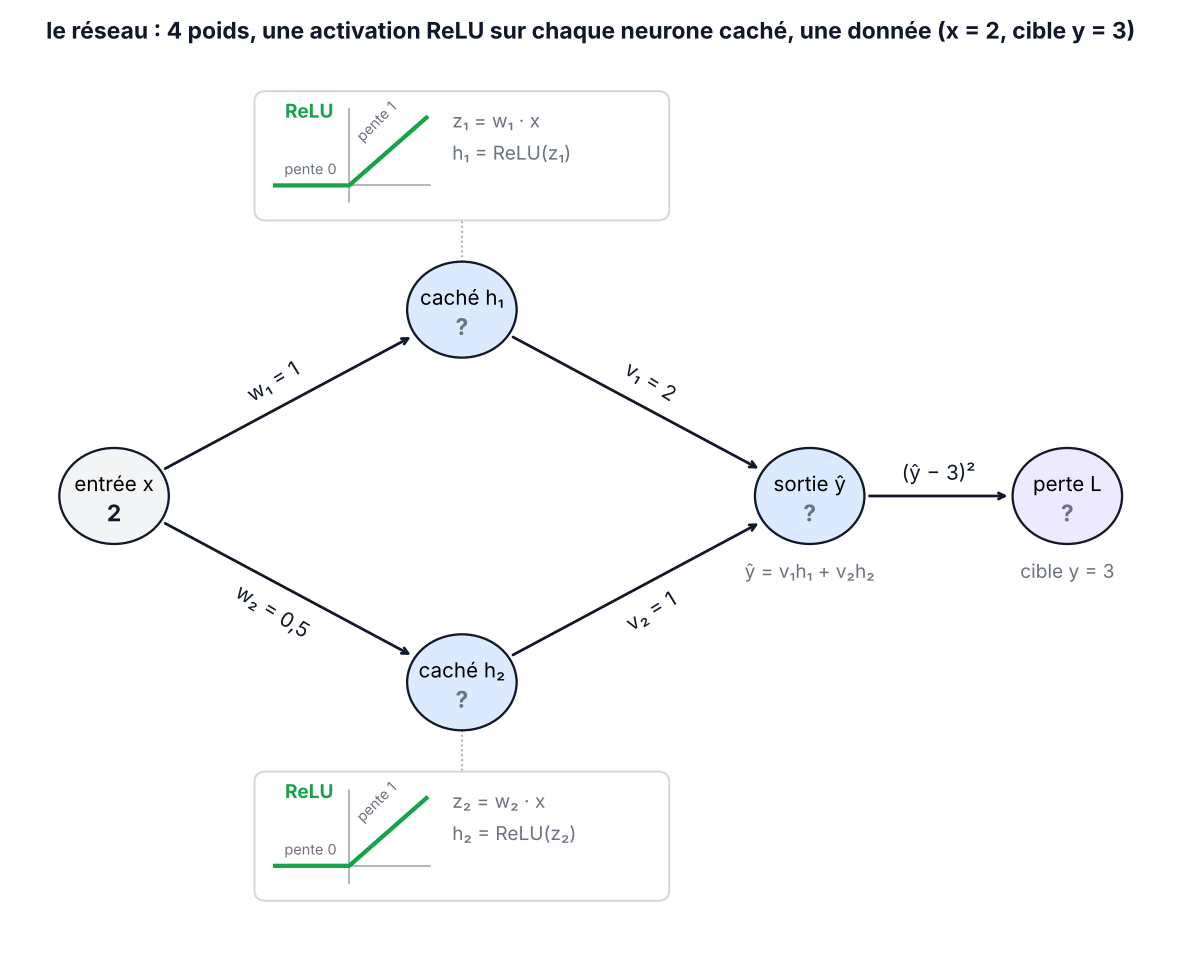

<br>

## L'aller : calculer la sortie et la perte

### On range les nombres de la figure dans des variables Python ordinaires.

In [2]:
x, y = 2.0, 3.0                  # la donnée : entrée 2, cible 3
w1, w2 = 1.0, 0.5                # les 2 poids de la couche cachée
v1, v2 = 2.0, 1.0                # les 2 poids de la sortie

### L'aller, premier calcul : les neurones cachés, en deux temps. D'abord la pré-activation z, le produit de l'entrée par le poids. Puis la fonction d'activation ReLU, qui garde z s'il est positif et le remplace par 0 sinon. En Python : `max(0, z)`, le plus grand des deux nombres.

$$\Large \boxed{\;z_1 = w_1\,x = 1 \times 2 = 2 \qquad z_2 = w_2\,x = 0{,}5 \times 2 = 1\;}$$

$$\Large \boxed{\;h_1 = \text{ReLU}(z_1) = \max(0,\,2) = 2 \qquad h_2 = \text{ReLU}(z_2) = \max(0,\,1) = 1\;}$$

In [3]:
z1 = w1 * x                      # pré-activation du neurone 1
z2 = w2 * x
h1 = max(0, z1)                  # ReLU : le plus grand entre 0 et z1
h2 = max(0, z2)
print('pré-activations (avant ReLU) : z1 =', z1, ' z2 =', z2)
print('neurones cachés (après ReLU) : h1 =', h1, ' h2 =', h2)

pré-activations (avant ReLU) : z1 = 2.0  z2 = 1.0
neurones cachés (après ReLU) : h1 = 2.0  h2 = 1.0


### Deuxième calcul : la sortie. Chaque neurone caché est multiplié par son poids de sortie, et on additionne.

$$\Large \boxed{\;\hat y = v_1 h_1 + v_2 h_2 = 2 \times 2 + 1 \times 1 = 5\;}$$

In [4]:
y_chapeau = v1 * h1 + v2 * h2
print('sortie : y_chapeau =', y_chapeau)

sortie : y_chapeau = 5.0


### Troisième calcul : la perte, le carré de l'écart entre la sortie et la cible. En Python, `** 2` élève au carré.

$$\Large \boxed{\;L = (\hat y - y)^2 = (5 - 3)^2 = 4\;}$$

In [5]:
L = (y_chapeau - y) ** 2
print('perte : L =', L)

perte : L = 4.0


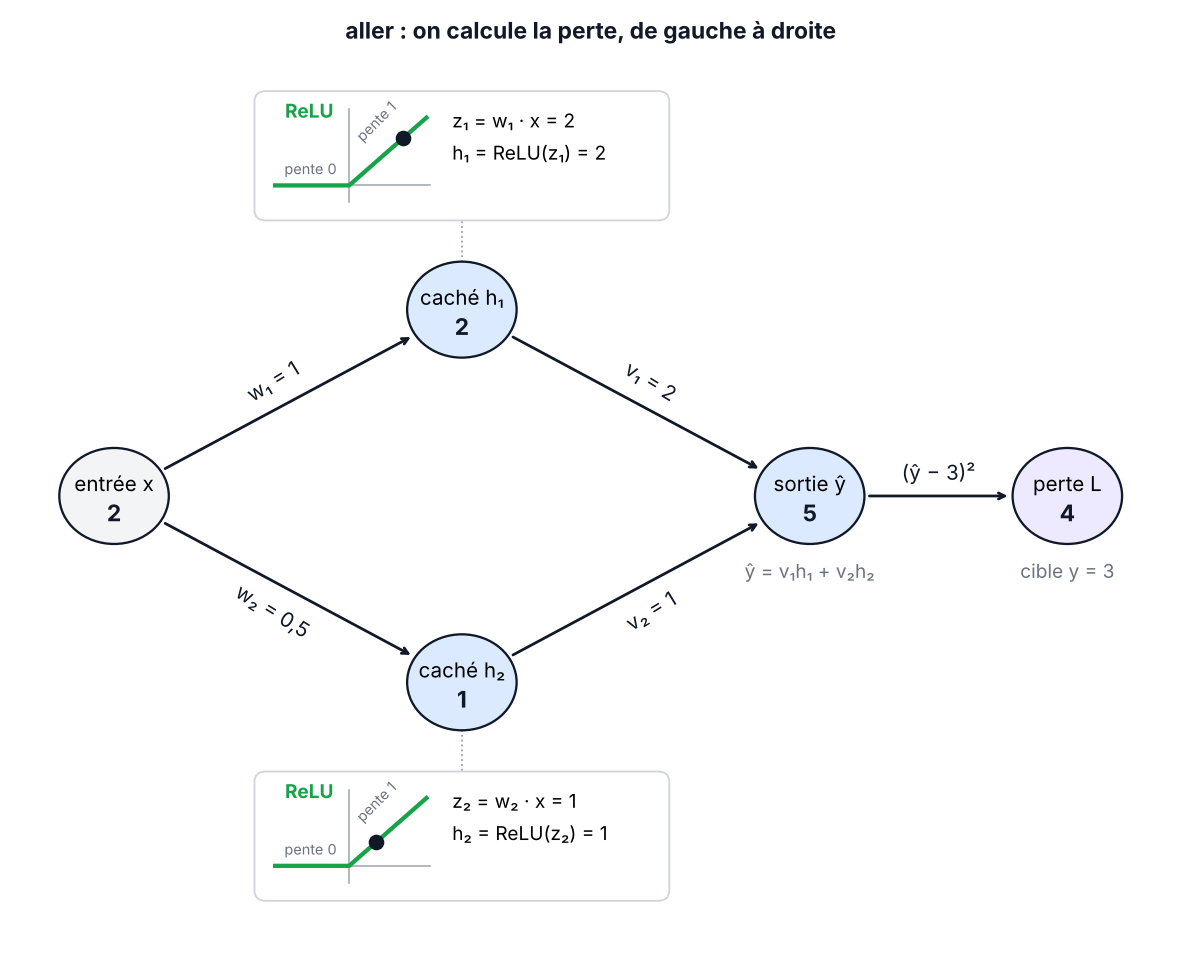

<br>

## Qu'est-ce qu'un gradient ?

### L'aller est fini : la perte vaut 4. Apprendre, c'est changer les poids pour la faire baisser. Si on augmente un poids d'un tout petit peu, de combien change la perte ? Essayons avec w₁, augmenté de 0,001, en refaisant tout l'aller (`round` arrondit l'affichage).

In [6]:
h1_apres = max(0, (w1 + 0.001) * x)              # on refait l'aller avec w1 un peu plus grand
L_apres = (v1 * h1_apres + v2 * h2 - y) ** 2
print('quand w1 augmente de 0.001, la perte augmente de', round(L_apres - L, 4))
print('rapport des deux :', round((L_apres - L) / 0.001, 2), '(la perte change environ 16 fois plus que w1)')

quand w1 augmente de 0.001, la perte augmente de 0.016
rapport des deux : 16.02 (la perte change environ 16 fois plus que w1)


### La perte change environ 16 fois plus que w₁ : ce 16 est le gradient. D'où vient-il ? w₁ n'agit pas directement sur la perte : il change z₁, puis h₁ à travers ReLU, puis ŷ, puis L. À chaque maillon, le changement est multiplié.

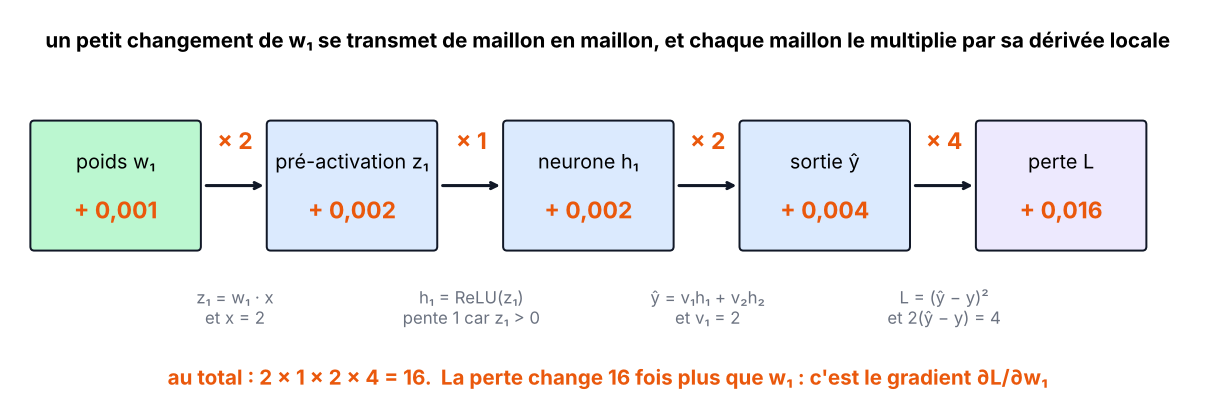

<br>

## La règle de la chaîne

### C'est la règle de la chaîne : le gradient est le produit des multiplicateurs de chaque maillon. Chaque multiplicateur est une dérivée locale : celle d'un seul calcul par rapport à son entrée.

$$\Large \boxed{\;\frac{\partial L}{\partial w_1} = \frac{\partial L}{\partial \hat y} \times \frac{\partial \hat y}{\partial h_1} \times \frac{\partial h_1}{\partial z_1} \times \frac{\partial z_1}{\partial w_1}\;}$$

### Pour trouver chaque dérivée locale, quatre règles de dérivation suffisent ; la dernière est celle de la fonction d'activation.

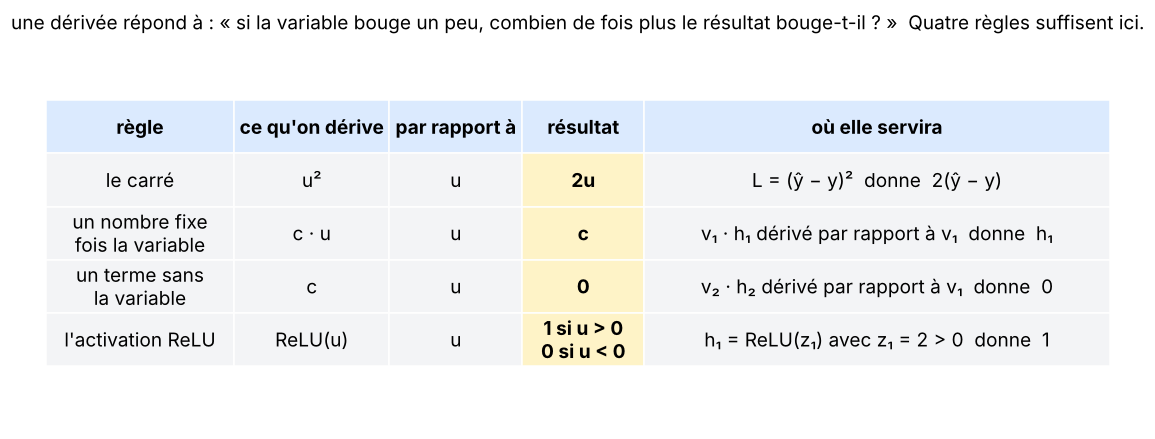

<br>

## Retour, étape 1 : de la perte à la sortie

### La rétropropagation calcule chaque dérivée locale une seule fois, en partant de la fin. Le dernier calcul de l'aller : L = (ŷ − y)². Règle du carré avec u = ŷ − y : la dérivée est 2u. Le code applique la formule puis, comme à chaque étape, la vérifie par un essai de 0,001.

$$\Large \boxed{\;L = (\hat y - y)^2 \;\;\Longrightarrow\;\; \frac{\partial L}{\partial \hat y} = 2\,(\hat y - y) = 2 \times (5 - 3) = 4\;}$$

In [7]:
dL_dy = 2 * (y_chapeau - y)
essai = ((y_chapeau + 0.001 - y) ** 2 - L) / 0.001       # vérification : on bouge la sortie de 0.001
print('par la formule : dL_dy =', dL_dy)
print('par un petit changement de la sortie :', round(essai, 2))

par la formule : dL_dy = 4.0
par un petit changement de la sortie : 4.0


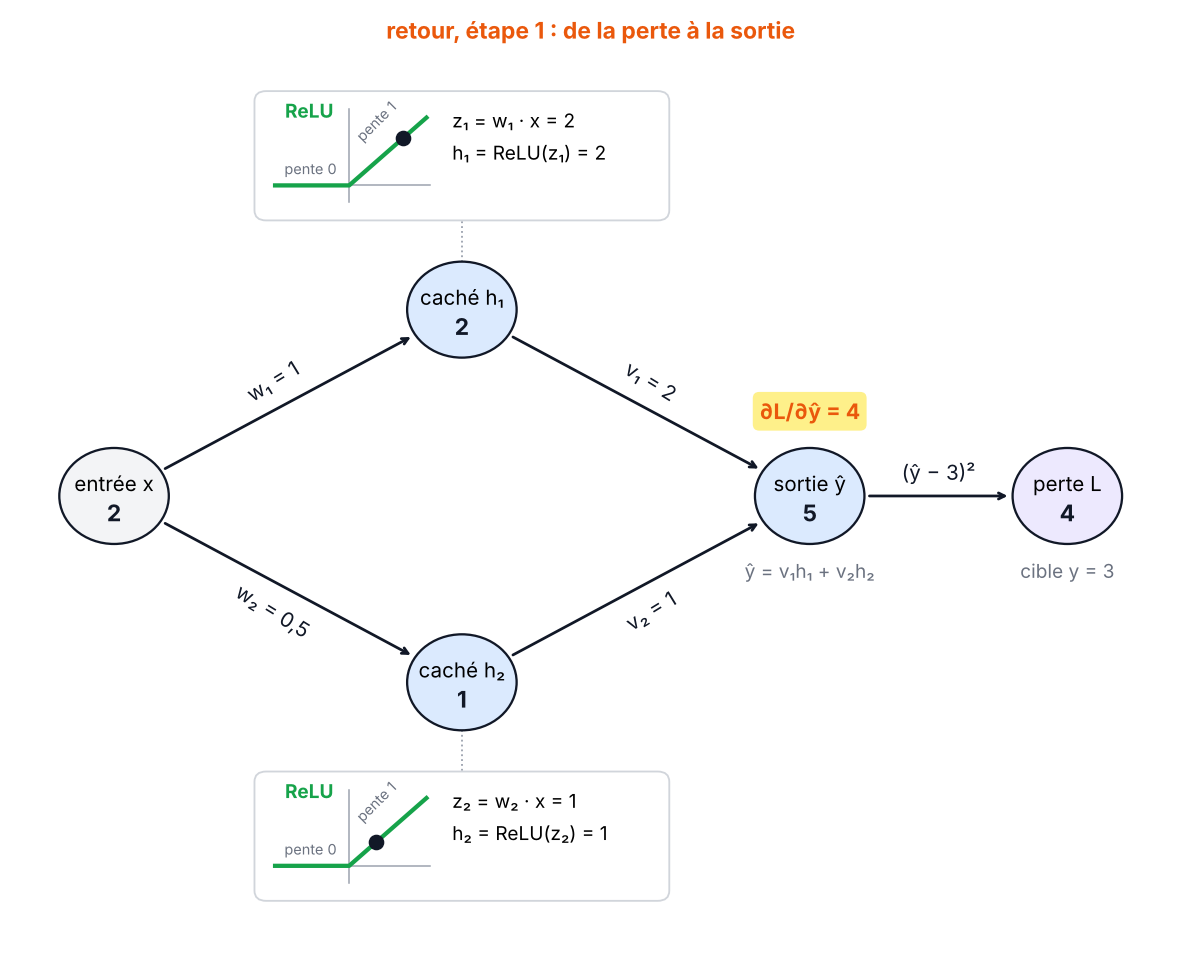

<br>

## Retour, étape 2 : les poids de sortie

### D'abord la dérivée locale : de combien bouge ŷ quand v₁ bouge ? Dans ŷ = v₁h₁ + v₂h₂, le terme v₂h₂ ne contient pas v₁ : sa dérivée est 0. Dans v₁h₁, h₁ est un nombre fixe qui multiplie v₁ : la dérivée est h₁.

$$\Large \boxed{\;\hat y = v_1 h_1 + v_2 h_2 \;\;\Longrightarrow\;\; \frac{\partial \hat y}{\partial v_1} = h_1 + 0 = 2\;}$$

In [8]:
dy_dv1 = h1
essai = ((v1 + 0.001) * h1 + v2 * h2 - y_chapeau) / 0.001     # vérification : on bouge v1 de 0.001
print('par la formule : dy_dv1 =', dy_dv1)
print('par un petit changement de v1 :', round(essai, 2))

par la formule : dy_dv1 = 2.0
par un petit changement de v1 : 2.0


### Puis la règle de la chaîne. v₁ change ŷ (dérivée locale : h₁ = 2), et ŷ change L (étape 1 : 4). Les deux effets se multiplient. Même raisonnement pour v₂, dont la dérivée locale est h₂ = 1.

$$\Large \boxed{\;\frac{\partial L}{\partial v_1} = \underbrace{\frac{\partial L}{\partial \hat y}}_{\text{étape 1 : } 4} \times \underbrace{\frac{\partial \hat y}{\partial v_1}}_{h_1 = 2} = 8 \qquad \frac{\partial L}{\partial v_2} = \underbrace{\frac{\partial L}{\partial \hat y}}_{4} \times \underbrace{\frac{\partial \hat y}{\partial v_2}}_{h_2 = 1} = 4\;}$$

In [9]:
dL_dv1 = dL_dy * h1              # gradient déjà connu (étape 1) fois dérivée locale
dL_dv2 = dL_dy * h2
print('gradients des poids de sortie : dL_dv1 =', dL_dv1, ' dL_dv2 =', dL_dv2)

gradients des poids de sortie : dL_dv1 = 8.0  dL_dv2 = 4.0


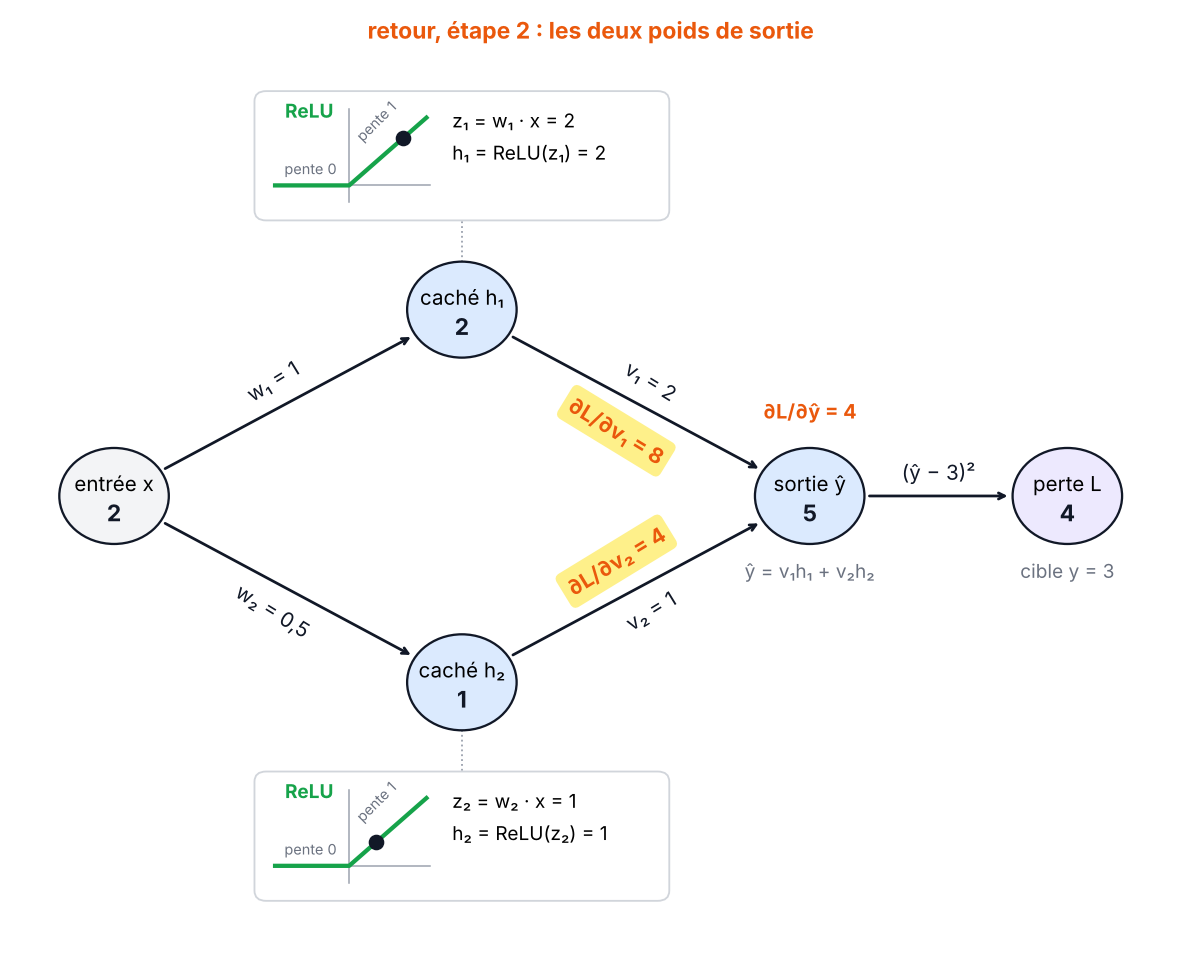

<br>

## Retour, étape 3 : les neurones cachés

### Dérivée locale : de combien bouge ŷ quand h₁ bouge ? Même formule, ŷ = v₁h₁ + v₂h₂, mais cette fois c'est h₁ qui varie et v₁ qui est le nombre fixe : la dérivée est v₁.

$$\Large \boxed{\;\hat y = v_1 h_1 + v_2 h_2 \;\;\Longrightarrow\;\; \frac{\partial \hat y}{\partial h_1} = v_1 + 0 = 2\;}$$

In [10]:
dy_dh1 = v1
essai = (v1 * (h1 + 0.001) + v2 * h2 - y_chapeau) / 0.001     # vérification : on bouge h1 de 0.001
print('par la formule : dy_dh1 =', dy_dh1)
print('par un petit changement de h1 :', round(essai, 2))

par la formule : dy_dh1 = 2.0
par un petit changement de h1 : 2.0


### Règle de la chaîne : h₁ change ŷ (dérivée locale : v₁ = 2), et ŷ change L (étape 1 : 4). Pour h₂, la dérivée locale est v₂ = 1.

$$\Large \boxed{\;\frac{\partial L}{\partial h_1} = \underbrace{\frac{\partial L}{\partial \hat y}}_{\text{étape 1 : } 4} \times \underbrace{\frac{\partial \hat y}{\partial h_1}}_{v_1 = 2} = 8 \qquad \frac{\partial L}{\partial h_2} = \underbrace{\frac{\partial L}{\partial \hat y}}_{4} \times \underbrace{\frac{\partial \hat y}{\partial h_2}}_{v_2 = 1} = 4\;}$$

In [11]:
dL_dh1 = dL_dy * v1              # gradient déjà connu (étape 1) fois dérivée locale
dL_dh2 = dL_dy * v2
print('gradients des neurones cachés : dL_dh1 =', dL_dh1, ' dL_dh2 =', dL_dh2)

gradients des neurones cachés : dL_dh1 = 8.0  dL_dh2 = 4.0


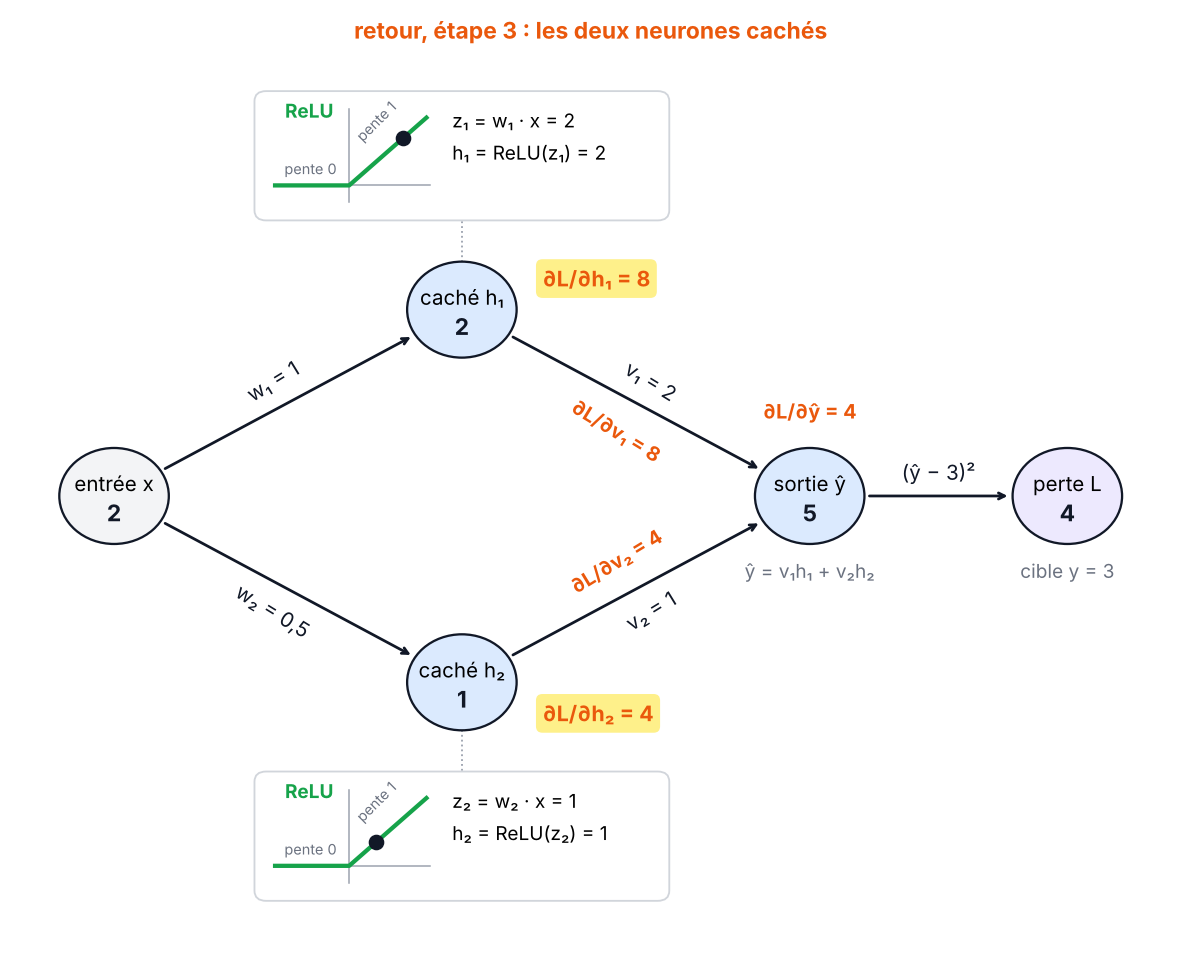

<br>

## Retour, étape 4 : la traversée de ReLU

### Le neurone caché applique h₁ = ReLU(z₁). La dérivée locale est la pente de ReLU au point z₁. Pour z positif, ReLU(z) = z : pente 1, le gradient passe inchangé. Pour z négatif, ReLU(z) = 0 : pente 0, le gradient est annulé. Ici z₁ = 2 et z₂ = 1 : pente 1.

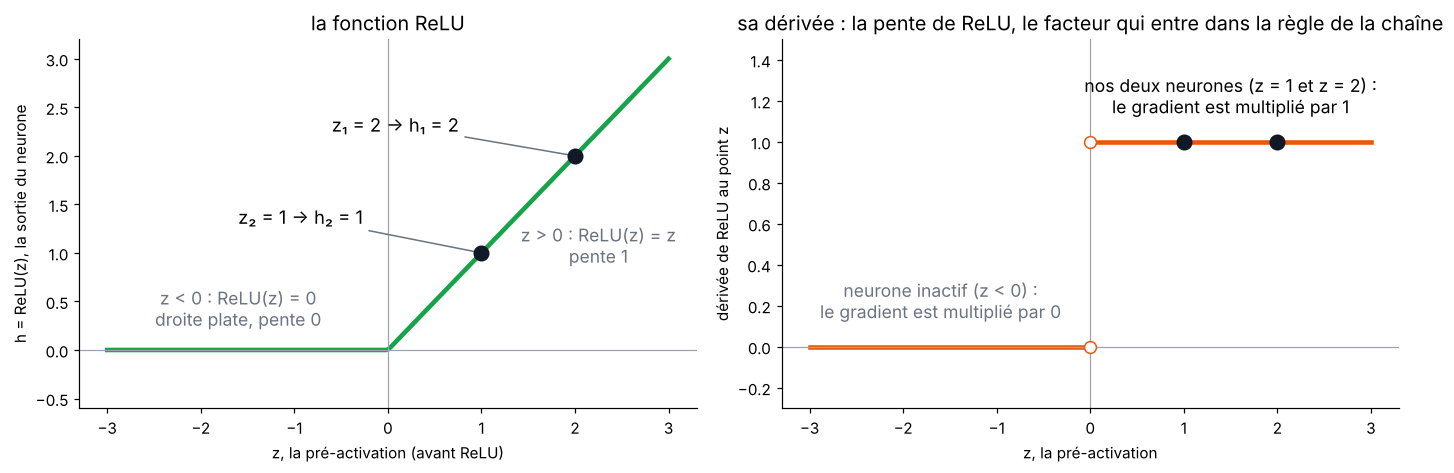

### En Python, la pente de ReLU au point z₁ s'écrit `1.0 if z1 > 0 else 0.0`. Règle de la chaîne : le gradient déjà connu (étape 3) est multiplié par cette pente.

$$\Large \boxed{\;\frac{\partial L}{\partial z_1} = \underbrace{\frac{\partial L}{\partial h_1}}_{\text{étape 3 : } 8} \times \underbrace{\frac{\partial h_1}{\partial z_1}}_{\text{pente de ReLU : } 1} = 8 \qquad \frac{\partial L}{\partial z_2} = \underbrace{\frac{\partial L}{\partial h_2}}_{4} \times \underbrace{\frac{\partial h_2}{\partial z_2}}_{1} = 4\;}$$

In [12]:
dh1_dz1 = 1.0 if z1 > 0 else 0.0                 # pente de ReLU au point z1 : 1 si z1 > 0, sinon 0
dh2_dz2 = 1.0 if z2 > 0 else 0.0
essai = (max(0, z1 + 0.001) - h1) / 0.001        # vérification : on bouge z1 de 0.001
dL_dz1 = dL_dh1 * dh1_dz1                        # gradient déjà connu (étape 3) fois pente de ReLU
dL_dz2 = dL_dh2 * dh2_dz2
print('pente de ReLU en z1, par la règle :', dh1_dz1, ' ; par un petit changement de z1 :', round(essai, 2))
print('gradients des pré-activations : dL_dz1 =', dL_dz1, ' dL_dz2 =', dL_dz2)

pente de ReLU en z1, par la règle : 1.0  ; par un petit changement de z1 : 1.0
gradients des pré-activations : dL_dz1 = 8.0  dL_dz2 = 4.0


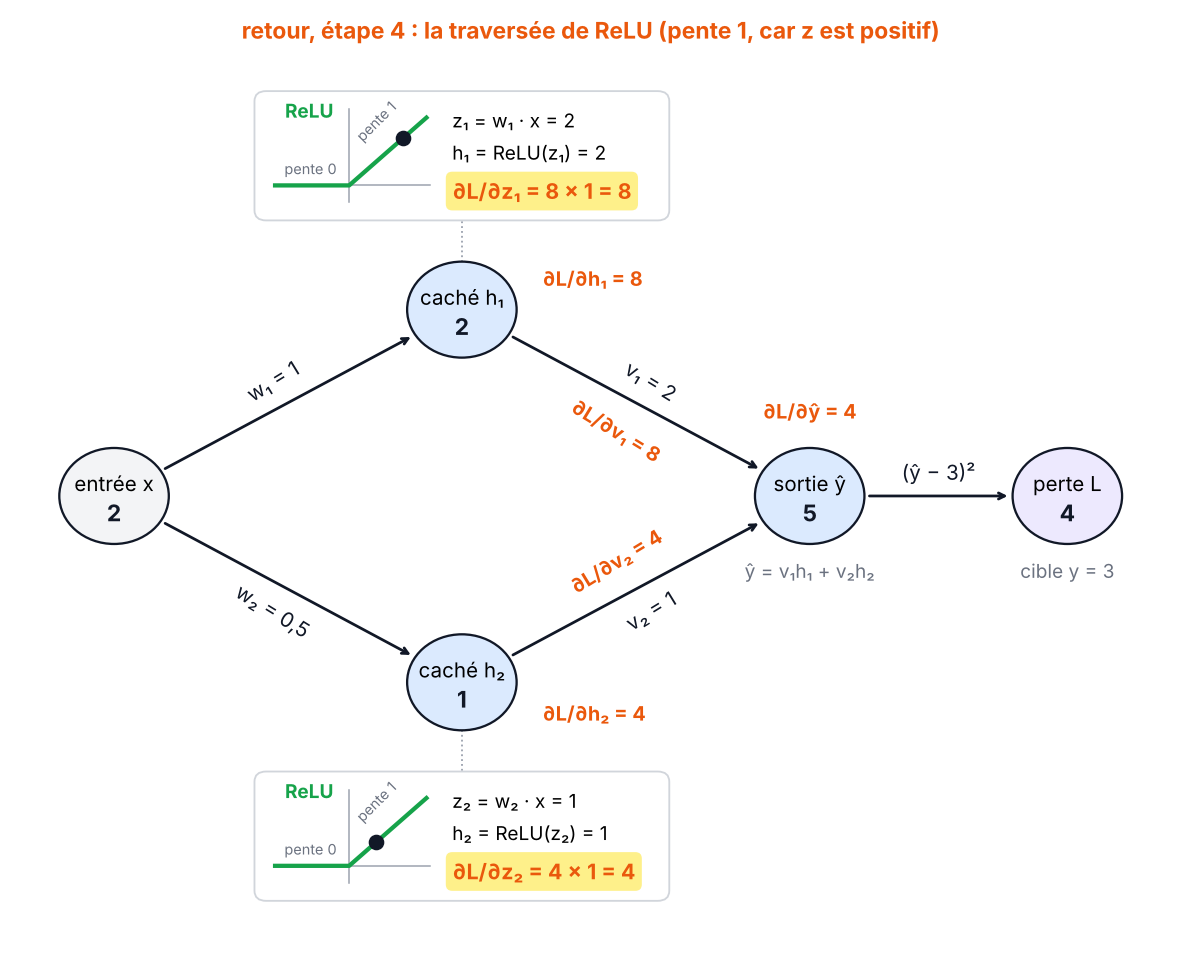

<br>

## Retour, étape 5 : les poids cachés

### Dérivée locale : de combien bouge z₁ quand w₁ bouge ? z₁ = w₁x : le nombre fixe x multiplie w₁, donc la dérivée est x.

$$\Large \boxed{\;z_1 = w_1\,x \;\;\Longrightarrow\;\; \frac{\partial z_1}{\partial w_1} = x = 2\;}$$

In [13]:
dz1_dw1 = x
essai = ((w1 + 0.001) * x - z1) / 0.001                       # vérification : on bouge w1 de 0.001
print('par la formule : dz1_dw1 =', dz1_dw1)
print('par un petit changement de w1 :', round(essai, 2))

par la formule : dz1_dw1 = 2.0
par un petit changement de w1 : 2.0


### Règle de la chaîne : w₁ change z₁ (dérivée locale : x = 2), et z₁ change L (étape 4 : 8). Pour w₂ : dérivée locale x = 2, et z₂ change L de 4.

$$\Large \boxed{\;\frac{\partial L}{\partial w_1} = \underbrace{\frac{\partial L}{\partial z_1}}_{\text{étape 4 : } 8} \times \underbrace{\frac{\partial z_1}{\partial w_1}}_{x = 2} = 16 \qquad \frac{\partial L}{\partial w_2} = \underbrace{\frac{\partial L}{\partial z_2}}_{4} \times \underbrace{\frac{\partial z_2}{\partial w_2}}_{x = 2} = 8\;}$$

In [14]:
dL_dw1 = dL_dz1 * x              # gradient déjà connu (étape 4) fois dérivée locale
dL_dw2 = dL_dz2 * x
print('gradients des poids cachés : dL_dw1 =', dL_dw1, ' dL_dw2 =', dL_dw2)

gradients des poids cachés : dL_dw1 = 16.0  dL_dw2 = 8.0


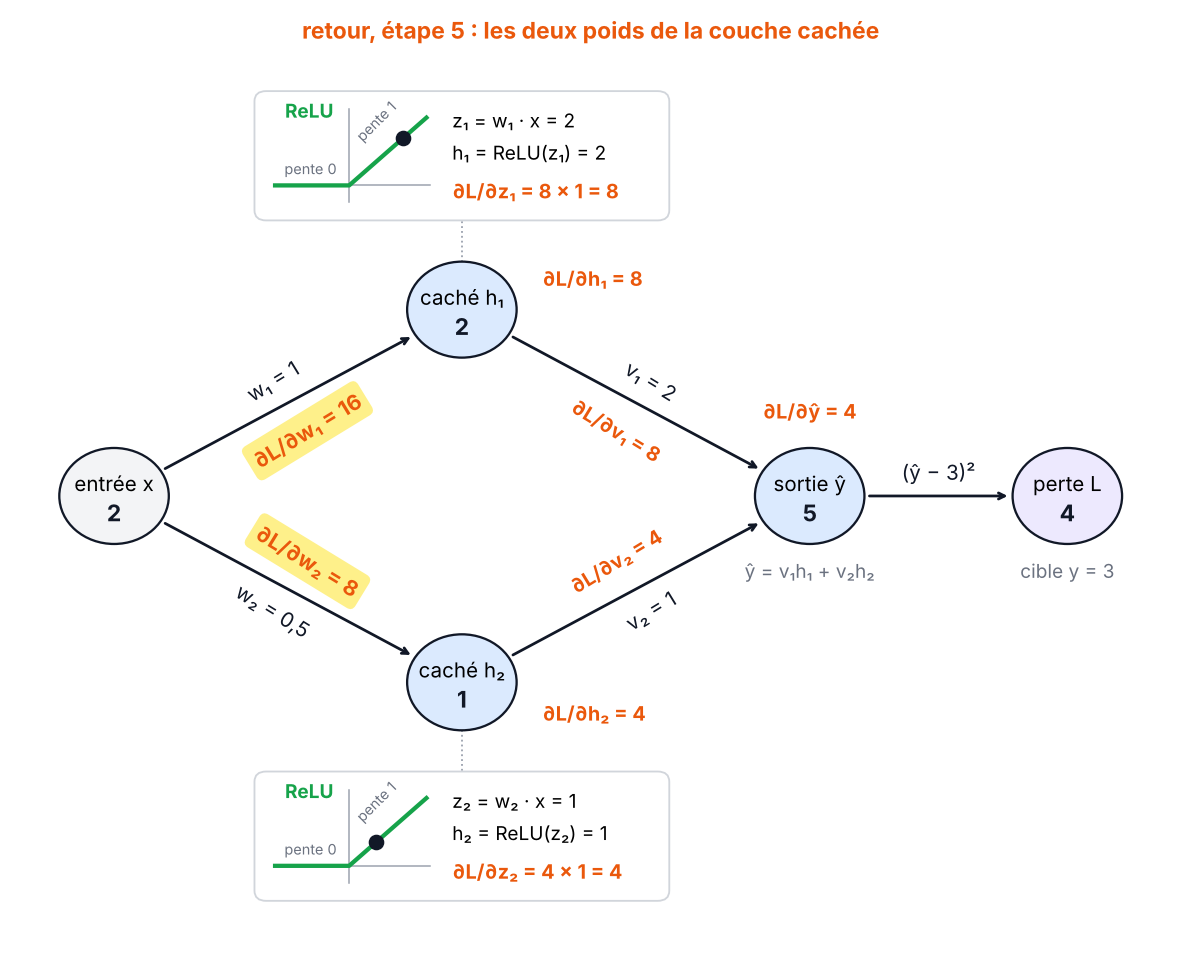

<br>

## La chaîne complète

### On assemble les cinq étapes. Première ligne, en symboles : le gradient de w₁ est le produit de quatre dérivées partielles, une par calcul entre w₁ et L. Deuxième ligne : l'expression de chacune, trouvée à l'étape indiquée. Troisième ligne : les valeurs. On retrouve le 16 de l'essai.

$$\Large \boxed{\;\begin{array}{rcccccccl}
 \rule{0pt}{20pt} & & \text{étape 1} & & \text{étape 3} & & \text{étape 4} & & \text{étape 5} \\[6pt]
\dfrac{\partial L}{\partial w_1} & = & \dfrac{\partial L}{\partial \hat y} & \times & \dfrac{\partial \hat y}{\partial h_1} & \times & \dfrac{\partial h_1}{\partial z_1} & \times & \dfrac{\partial z_1}{\partial w_1} \\[16pt]
 & = & 2\,(\hat y - y) & \times & v_1 & \times & \text{pente de ReLU en } z_1 & \times & x \\[12pt]
 & = & 4 & \times & 2 & \times & 1 & \times & 2 \\[12pt]
 & = & 16 \rule[-12pt]{0pt}{0pt} & & & & & &
\end{array}\;}$$

In [15]:
print('chaîne complète pour w1 : 4 x 2 x 1 x 2 =', dL_dy * dy_dh1 * dh1_dz1 * dz1_dw1)
print('premier facteur, commun aux quatre gradients et calculé une seule fois : dL_dy =', dL_dy)

chaîne complète pour w1 : 4 x 2 x 1 x 2 = 16.0
premier facteur, commun aux quatre gradients et calculé une seule fois : dL_dy = 4.0


<br>

## La descente de gradient : un pas

### Dernière opération, la descente de gradient : on soustrait à chaque poids son gradient multiplié par le pas (le taux d'apprentissage). Les quatre gradients sont positifs, donc les quatre poids diminuent. Avec un pas de 0,01 :

$$\Large \boxed{\;w_1 \leftarrow w_1 - \text{pas} \times \frac{\partial L}{\partial w_1} = 1 - 0{,}01 \times 16 = 0{,}84\;}$$

In [16]:
pas = 0.01
w1 = w1 - pas * dL_dw1
w2 = w2 - pas * dL_dw2
v1 = v1 - pas * dL_dv1
v2 = v2 - pas * dL_dv2
print('nouveaux poids : w1 =', round(w1, 2), ' w2 =', round(w2, 2), ' v1 =', round(v1, 2), ' v2 =', round(v2, 2))

nouveaux poids : w1 = 0.84  w2 = 0.42  v1 = 1.92  v2 = 0.96


### Le réseau a-t-il appris ? On refait l'aller avec les nouveaux poids.

In [17]:
h1 = max(0, w1 * x)
h2 = max(0, w2 * x)
y_chapeau = v1 * h1 + v2 * h2
L = (y_chapeau - y) ** 2
print('nouvelle sortie :', round(y_chapeau, 2), '(avant le pas : 5.0 ; cible : 3.0)')
print('nouvelle perte  :', round(L, 2), '(avant le pas : 4.0)')

nouvelle sortie : 4.03 (avant le pas : 5.0 ; cible : 3.0)
nouvelle perte  : 1.07 (avant le pas : 4.0)


# 2. Pourquoi PyTorch ?

### Un seul pas, et la sortie passe de 5 à 4,03, la perte de 4 à 1,07. Aller, perte, retour, pas : c'est tout l'apprentissage. Mais à la main, il a fallu cinq étapes de retour pour 4 poids. Voici combien de gradients il faut à chaque pas, selon le réseau.

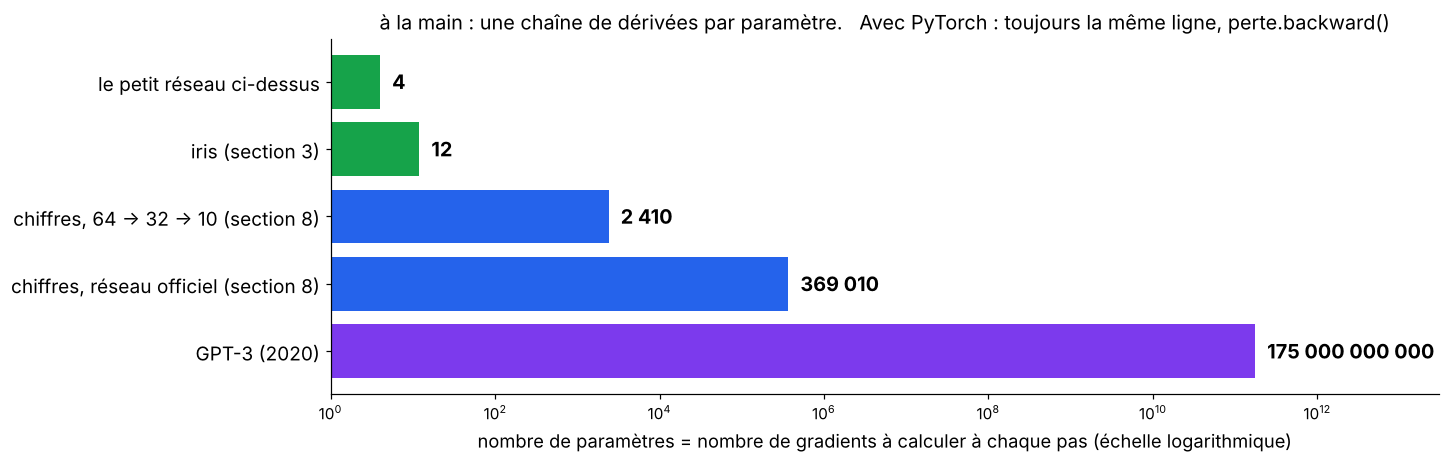

### PyTorch fournit ces opérations : les tenseurs calculent l'aller sur des tableaux entiers, `backward()` calcule tous les gradients par rétropropagation, et `optim` applique la mise à jour. Tout entraînement tiendra dans cette boucle de cinq lignes, construite ligne par ligne dans la suite.

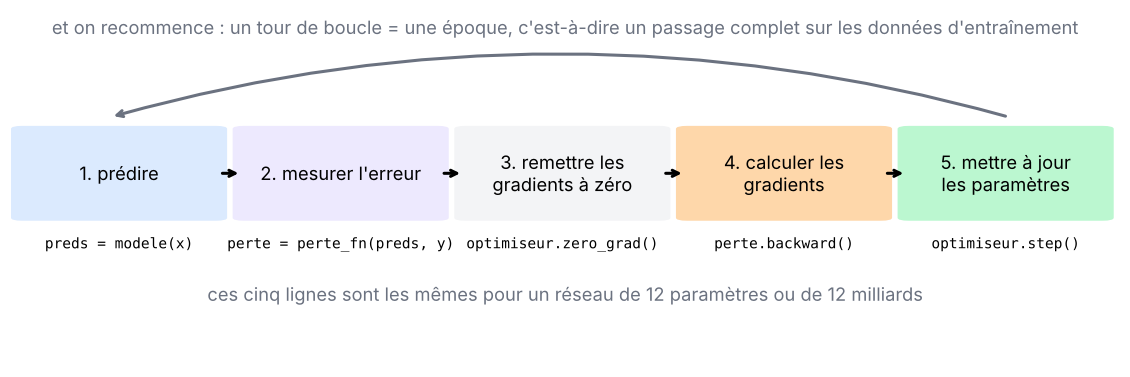

# 3. Les tenseurs

### Un tenseur est un tableau de nombres à plusieurs dimensions, l'équivalent du `np.array` de NumPy. `torch.tensor(liste)` en crée un à partir d'une liste Python. Sa forme, lue dans l'attribut `.shape`, donne la taille de chaque dimension : c'est la première chose à vérifier dans tout calcul.

In [18]:
a = torch.tensor([1.0, 2.0, 3.0])        # un vecteur de 3 nombres
print('a =', a)
print('forme de a :', a.shape, '(3 nombres en ligne)')

a = tensor([1., 2., 3.])
forme de a : torch.Size([3]) (3 nombres en ligne)


### `.view(3, 1)` change la forme sans changer les nombres : les 3 nombres deviennent une matrice de 3 lignes et 1 colonne. C'est le `reshape` de NumPy.

In [19]:
b = torch.tensor([4.0, 5.0, 6.0]).view(3, 1)   # 3 lignes, 1 colonne
print(f'b, les mêmes nombres en colonne :\n{b}')
print('forme de b :', b.shape, '(3 lignes, 1 colonne)')

b, les mêmes nombres en colonne :
tensor([[4.],
        [5.],
        [6.]])
forme de b : torch.Size([3, 1]) (3 lignes, 1 colonne)


### `torch.randn(3, 3)` crée une matrice 3 × 3 de nombres aléatoires (loi normale). `torch.manual_seed(0)` fixe la graine du générateur aléatoire : tout le monde obtient les mêmes nombres.

In [20]:
torch.manual_seed(0)
W = torch.randn(3, 3)
print(f'W, une matrice 3 x 3 :\n{W}')

W, une matrice 3 x 3 :
tensor([[ 1.541, -0.293, -2.179],
        [ 0.568, -1.085, -1.399],
        [ 0.403,  0.838, -0.719]])


### Le produit d'une matrice par un vecteur : `torch.matmul(W, a)`, qui s'écrit aussi `W @ a`. W a la forme (3, 3) et `a` la forme (3,) : le résultat a la forme (3,).

In [21]:
Wa = torch.matmul(W, a)          # même chose que W @ a
print('W fois a =', Wa)
print('forme du résultat :', Wa.shape, '(un vecteur de 3 nombres)')

W fois a = tensor([-5.582, -5.796, -0.078])
forme du résultat : torch.Size([3]) (un vecteur de 3 nombres)


### Chaque élément du résultat est le produit d'une ligne de W par a : on multiplie terme à terme, puis on additionne.

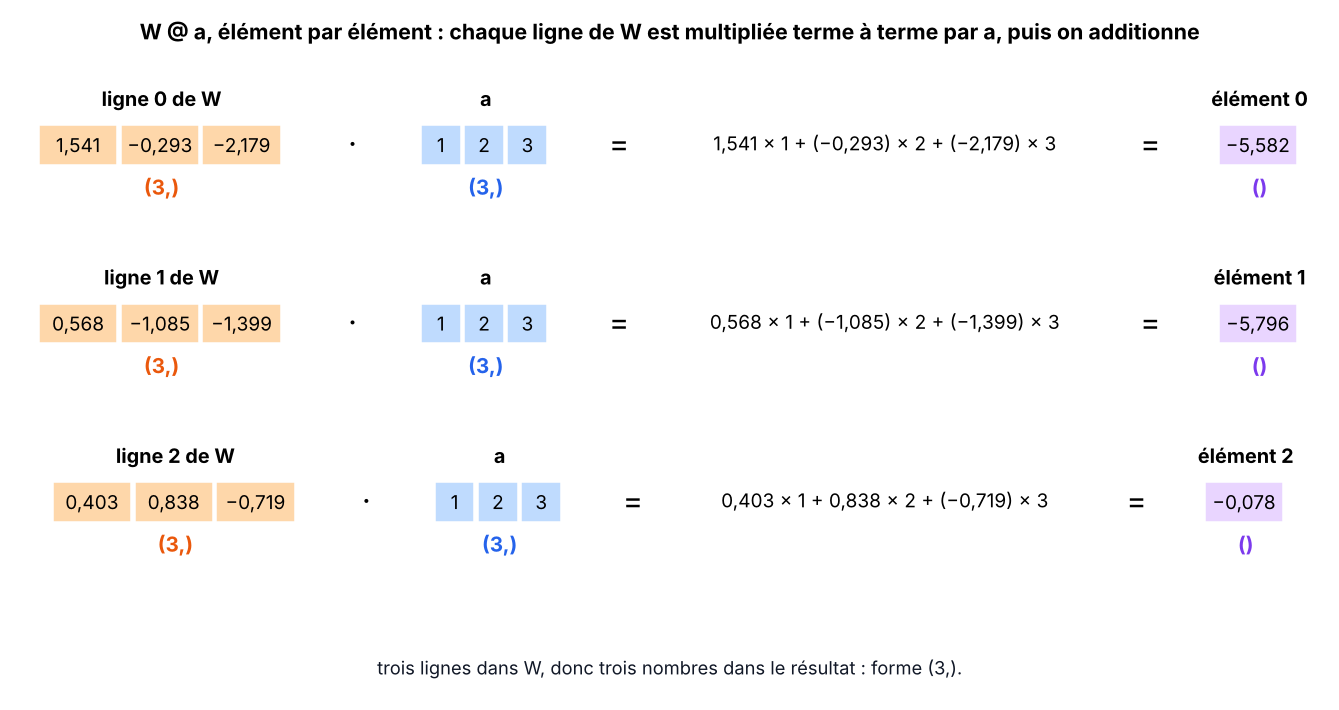

### `torch.mm(W, b)` (mm : « matrix multiplication ») calcule le produit de deux matrices. Contrairement à `torch.matmul`, il n'accepte que des tenseurs à 2 dimensions. W a la forme (3, 3) et `b` la forme (3, 1) : le résultat a la forme (3, 1).

In [22]:
Wb = torch.mm(W, b)
print(f'W fois b :\n{Wb}')
print('forme du résultat :', Wb.shape, '(une colonne de 3 nombres)')

W fois b :
tensor([[ -8.376],
        [-11.540],
        [  1.488]])
forme du résultat : torch.Size([3, 1]) (une colonne de 3 nombres)


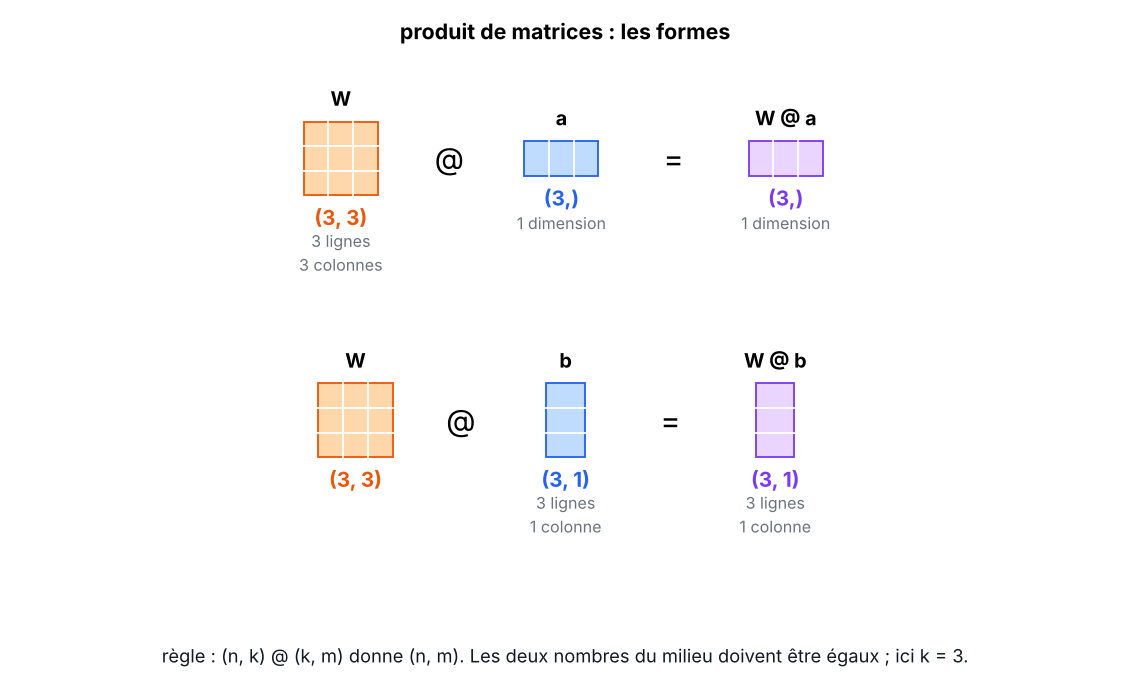

### ✏️ Remplacez `b` par `a` dans la cellule ci-dessus : `torch.mm` refuse un tenseur à 1 dimension. Remettez `b`.

### 🔮 `a` vaut [1, 2, 3] et `b` est la colonne [4, 5, 6]. Que vaut `a + b` : [5, 7, 9], une erreur, ou autre chose ?

In [23]:
print(f'a + b :\n{a + b}')
print('forme de a + b :', (a + b).shape)

a + b :
tensor([[5., 6., 7.],
        [6., 7., 8.],
        [7., 8., 9.]])
forme de a + b : torch.Size([3, 3])


### Aucune erreur : c'est la diffusion (broadcasting). Quand deux formes diffèrent, toute dimension absente ou de taille 1 est répétée jusqu'à la taille de l'autre tenseur : (3,) et (3, 1) deviennent tous deux (3, 3). Devant un résultat inattendu, affichez d'abord les formes.

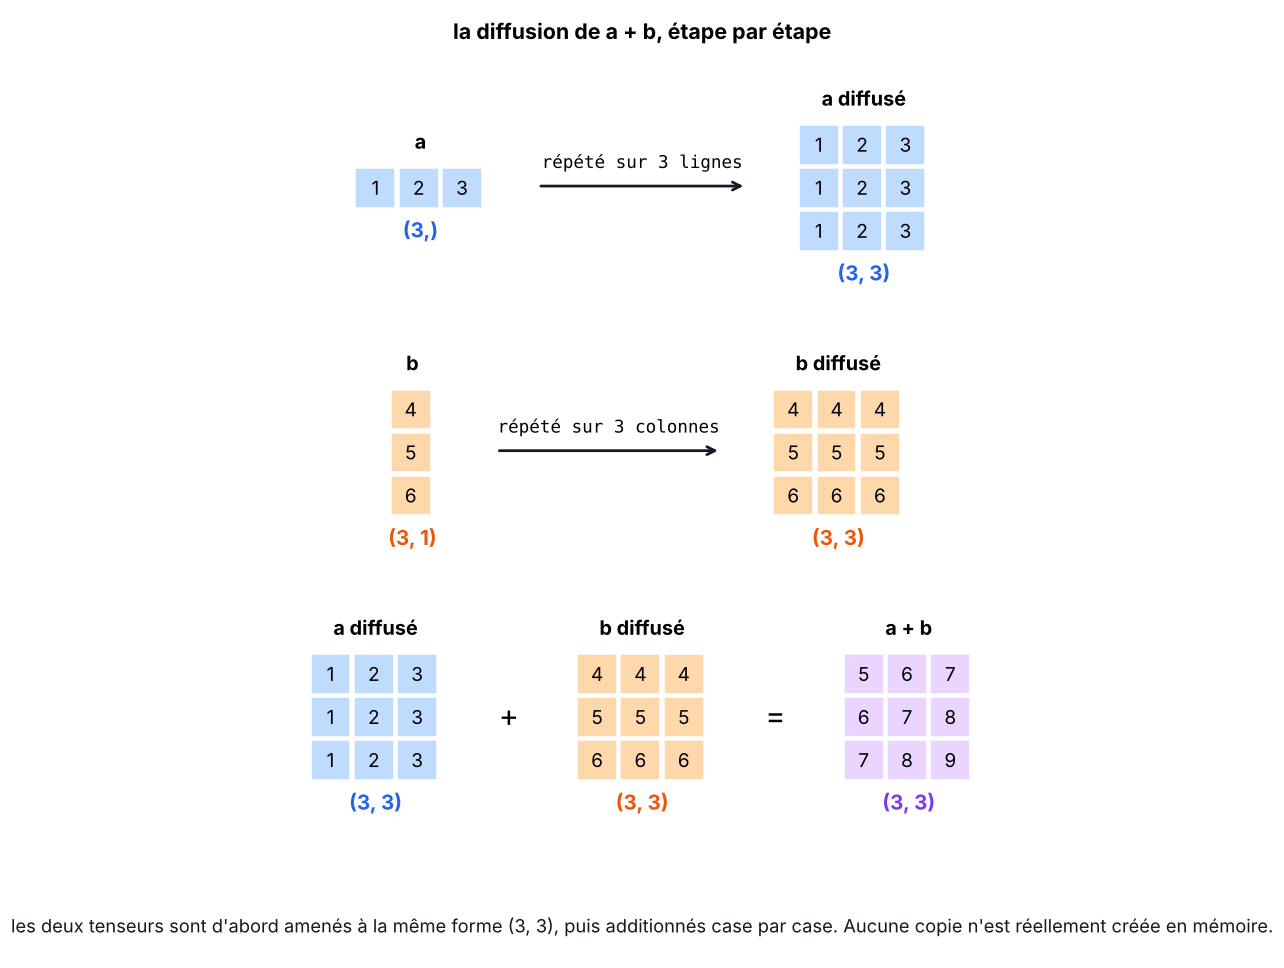

### Pourquoi pas trois nombres, 1 + 4, 2 + 5 et 3 + 6 ? L'addition se fait case par case, entre tenseurs de même forme. `a`, de forme (3,), est lu comme une ligne (1, 3) ; `b` est une colonne (3, 1). Seuls 1 et 4 occupent la même case : PyTorch répète donc chaque tenseur le long de sa dimension de taille 1.

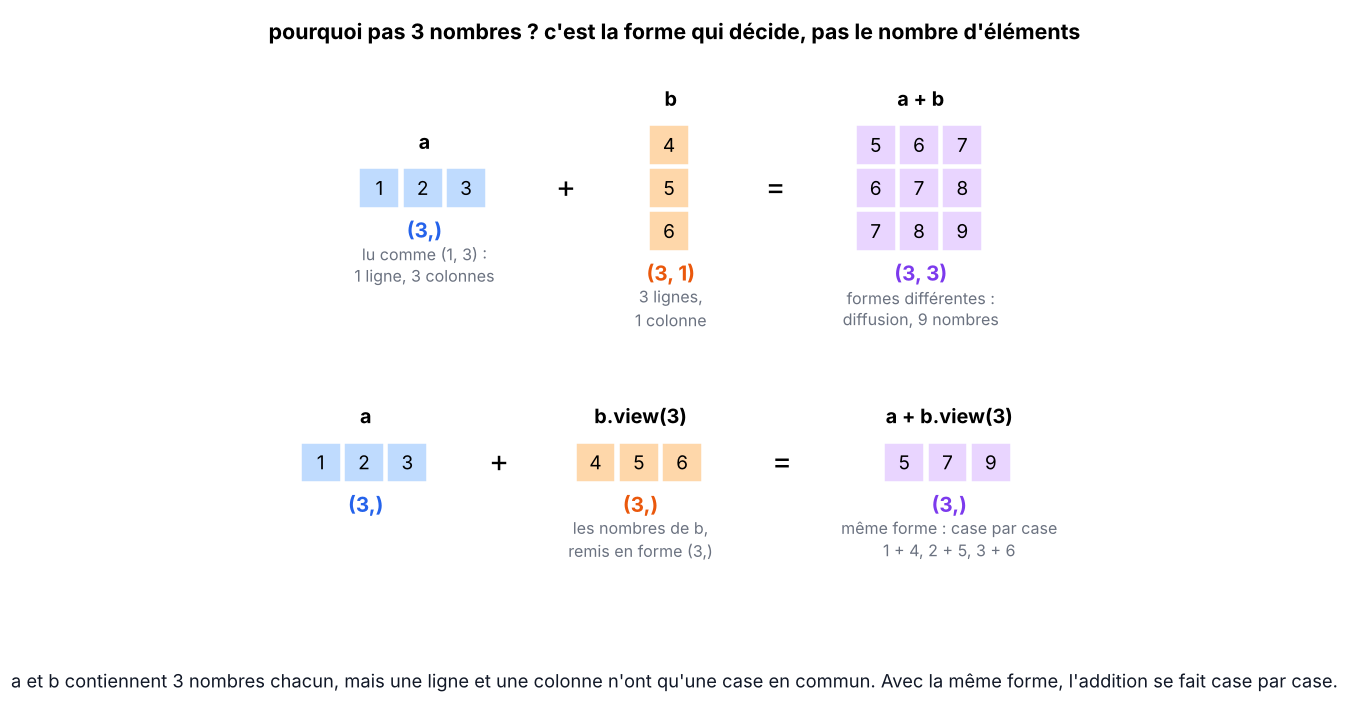

### Pour obtenir trois nombres, il faut donner la même forme aux deux tenseurs : `b.view(3)` remet les nombres de `b` en forme (3,). Alors (3,) + (3,) donne (3,), case par case, sans diffusion.

In [24]:
b_plat = b.view(3)               # les mêmes nombres que b, en forme (3,)
print('forme de a :', a.shape, ' forme de b_plat :', b_plat.shape)
print('a + b_plat, case par case (1 + 4, 2 + 5, 3 + 6) :', a + b_plat)

forme de a : torch.Size([3])  forme de b_plat : torch.Size([3])
a + b_plat, case par case (1 + 4, 2 + 5, 3 + 6) : tensor([5., 7., 9.])


### Ce que NumPy ne fait pas : exécuter les calculs sur une carte graphique (GPU), dont les milliers de cœurs travaillent en parallèle. `torch.cuda.is_available()` répond `True` si un GPU est utilisable. `torch.device` désigne alors l'appareil de calcul : `'cuda'` (le GPU) ou, sinon, `'cpu'` (le processeur).

In [25]:
appareil = torch.device('cuda' if torch.cuda.is_available() else 'cpu')   # 'cuda' : le nom du GPU pour PyTorch
print('appareil choisi :', appareil, '(cuda = carte graphique, cpu = processeur)')

appareil choisi : cuda (cuda = carte graphique, cpu = processeur)


### `.to(appareil)` copie un tenseur dans la mémoire de cet appareil. Règle : tous les tenseurs d'un même calcul doivent être sur le même appareil, sinon PyTorch lève une erreur. L'attribut `.device` indique où se trouve un tenseur.

In [26]:
a_gpu = a.to(appareil)           # une copie de a sur l'appareil choisi
print('a_gpu se trouve sur :', a_gpu.device)

a_gpu se trouve sur : cuda:0


### 🔮 Pour multiplier deux matrices 3000 × 3000, le GPU sera-t-il 2, 10 ou 100 fois plus rapide que le processeur ? Et pour deux matrices 250 × 250 ?

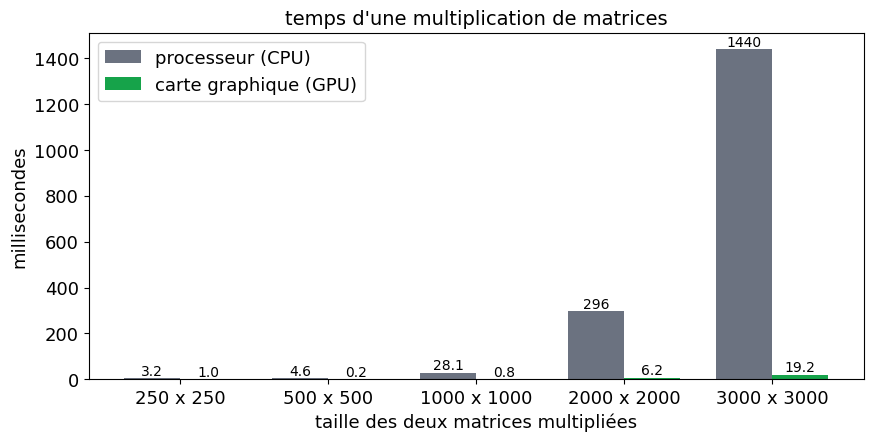

Pour 3000 x 3000 : le GPU est environ 75 fois plus rapide.


In [27]:
#@title Démo A : le temps d'une multiplication de matrices, processeur contre GPU { display-mode: "form" }
demo_gpu()

### Le GPU ne sert que pour les gros calculs : ce labo s'exécute sur le processeur.

# 4. Autograd : le retour, calculé pour vous

### On reprend le réseau de la section 1 : une entrée x = 2, deux neurones cachés avec ReLU, une sortie ŷ, la cible y = 3, quatre poids. But : refaire avec PyTorch les mêmes calculs, aller puis retour, et retrouver les nombres obtenus à la main.

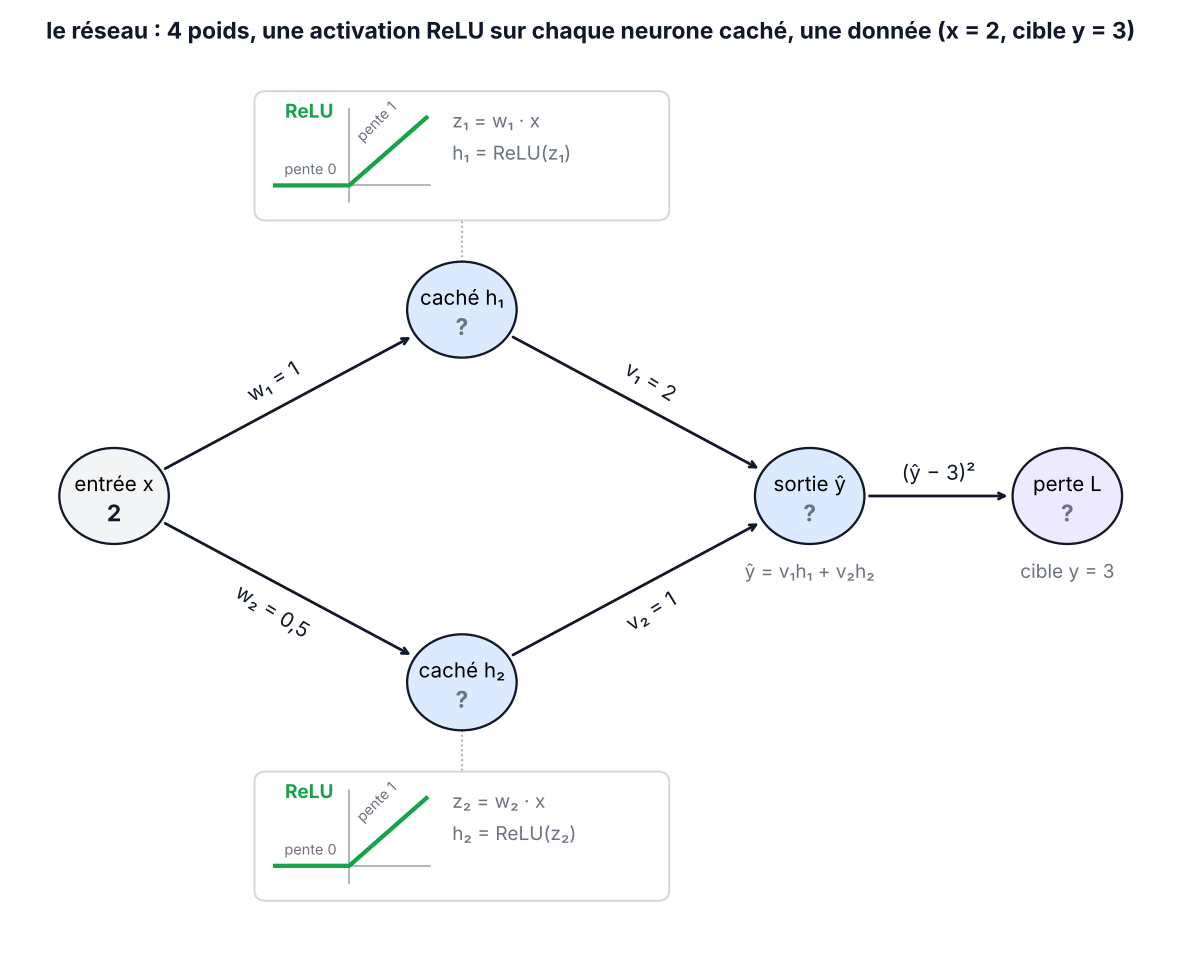

### Seul changement dans les données de départ : les quatre poids ne sont plus quatre variables Python. Ils sont rangés dans deux tenseurs de forme (2,). `w` contient les poids de la couche cachée, w₁ et w₂ ; `v` contient les poids de sortie, v₁ et v₂. L'entrée `x` et la cible `y` restent deux nombres.

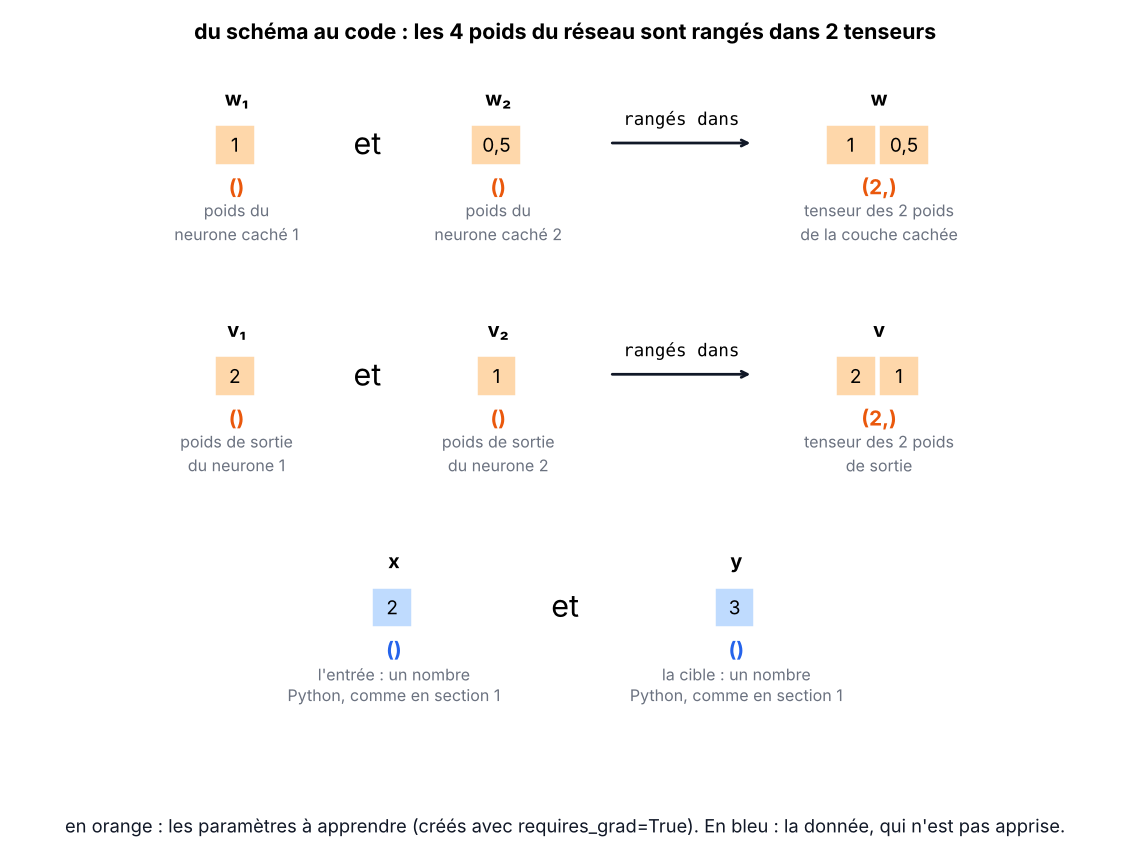

### `torch.tensor(liste, requires_grad=True)` crée le tenseur et le déclare comme paramètre à apprendre. Conséquence : PyTorch enregistrera chaque opération qui utilise `w` ou `v`, pour pouvoir calculer leurs gradients plus tard, quand on appellera `backward()`. `x` et `y` sont des données : pas de `requires_grad`.

In [28]:
x, y = 2.0, 3.0                                    # la donnée de la section 1 : entrée 2, cible 3
w = torch.tensor([1.0, 0.5], requires_grad=True)   # [w1, w2] : les poids de la couche cachée
v = torch.tensor([2.0, 1.0], requires_grad=True)   # [v1, v2] : les poids de sortie
print('w, poids de la couche cachée (w1, w2) :', w, ' forme', w.shape)
print('v, poids de sortie (v1, v2)           :', v, ' forme', v.shape)

w, poids de la couche cachée (w1, w2) : tensor([1.000, 0.500], requires_grad=True)  forme torch.Size([2])
v, poids de sortie (v1, v2)           : tensor([2., 1.], requires_grad=True)  forme torch.Size([2])


### Deux attributs à connaître. `w.requires_grad` vaut `True` : `w` est bien un paramètre à apprendre. `w.grad` est l'emplacement où PyTorch rangera le gradient de `w`, c'est-à-dire ∂L/∂w₁ et ∂L/∂w₂. Il vaut `None` pour l'instant : aucun gradient n'a encore été calculé.

In [29]:
print('w est-il un paramètre à apprendre (requires_grad) ?', w.requires_grad)
print('gradient stocké dans w.grad avant tout calcul :', w.grad)

w est-il un paramètre à apprendre (requires_grad) ? True
gradient stocké dans w.grad avant tout calcul : None


<br>

## L'aller, en tenseurs

### L'aller suit le schéma de gauche à droite, comme en section 1. Premier calcul : les pré-activations z₁ = w₁x et z₂ = w₂x. Avec les tenseurs, les deux neurones cachés sont calculés en une seule opération, `w * x`. `x` est un seul nombre : par diffusion, il multiplie chaque élément de `w`.

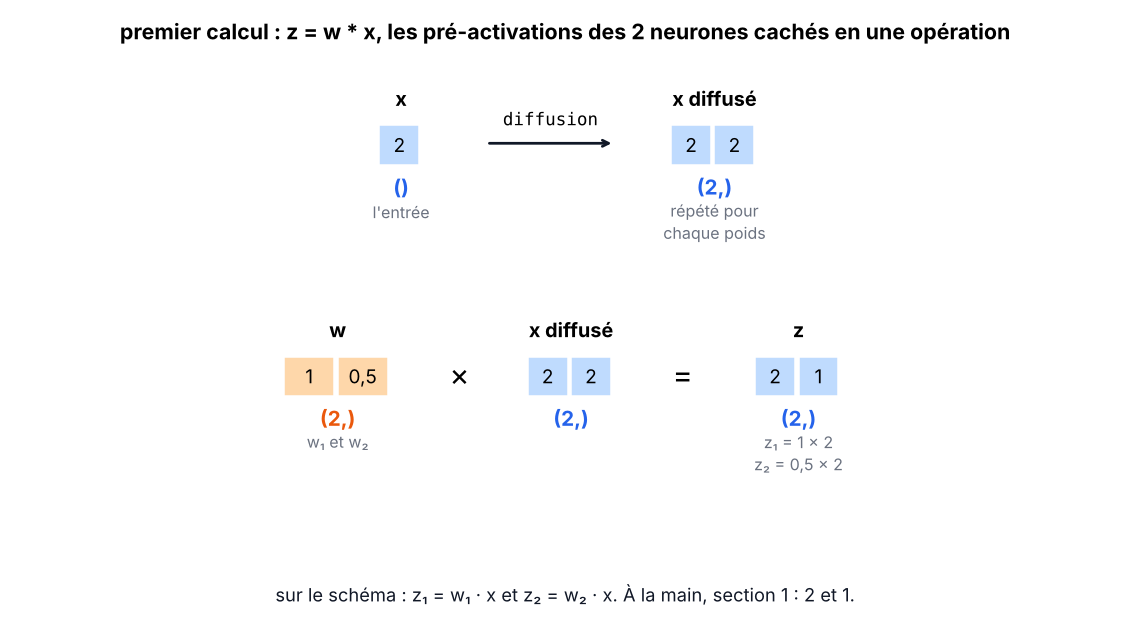

### À l'exécution, l'affichage de `z` contiendra `grad_fn=<MulBackward0>` : c'est la trace de l'enregistrement. PyTorch a noté que `z` est le résultat d'une multiplication (Mul) à laquelle participe un paramètre à apprendre.

In [30]:
z = w * x                        # z1 = w1 * x et z2 = w2 * x, en une opération
print('pré-activations z1 et z2 (à la main : 2 et 1) :', z, ' forme', z.shape)

pré-activations z1 et z2 (à la main : 2 et 1) : tensor([2., 1.], grad_fn=<MulBackward0>)  forme torch.Size([2])


### Deuxième calcul : la fonction d'activation des deux neurones cachés, h₁ = ReLU(z₁) et h₂ = ReLU(z₂).

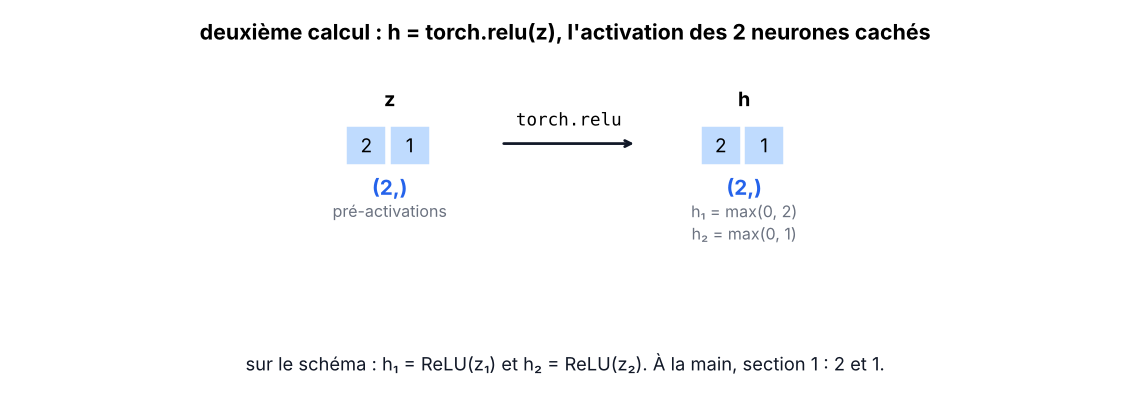

### `torch.relu(z)` applique ReLU à chaque élément de `z` : c'est le `max(0, z)` de la section 1, pour un tenseur entier. L'affichage portera un autre `grad_fn` : chaque opération enregistrée laisse sa trace.

In [31]:
h = torch.relu(z)                # h1 = max(0, z1) et h2 = max(0, z2)
print('neurones cachés h1 et h2 (à la main : 2 et 1) :', h, ' forme', h.shape)

neurones cachés h1 et h2 (à la main : 2 et 1) : tensor([2., 1.], grad_fn=<ReluBackward0>)  forme torch.Size([2])


### Troisième calcul, la sortie : ŷ = v₁h₁ + v₂h₂. Quatrième calcul, la perte : L = (ŷ − y)².

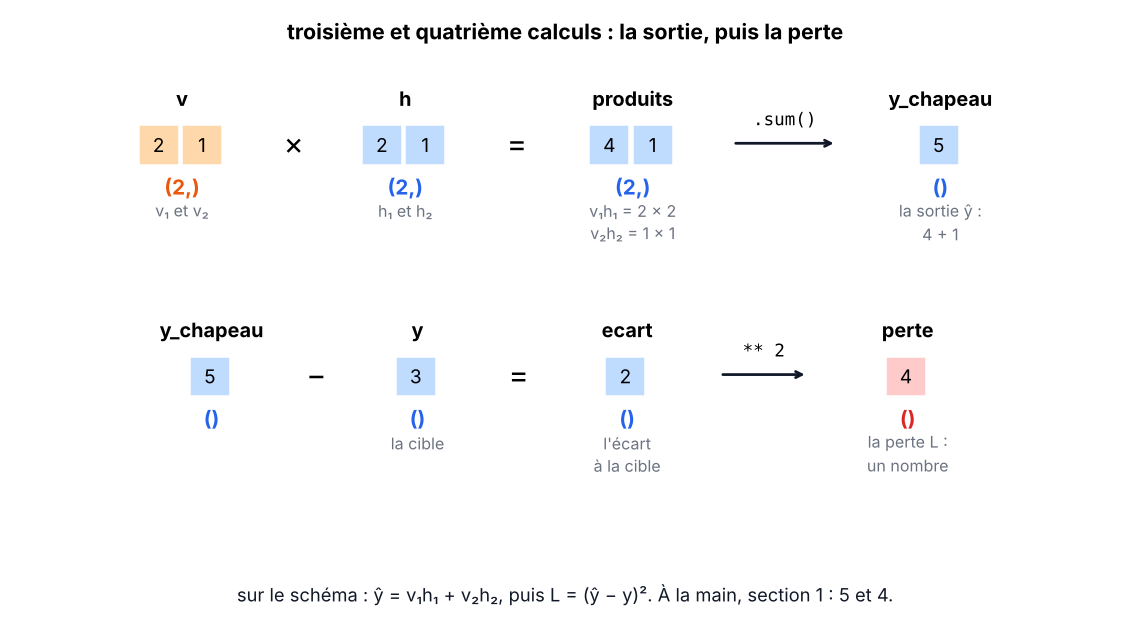

### `v * h` multiplie élément par élément, puis `.sum()` additionne les deux produits : c'est la sortie. On en soustrait la cible, et `** 2` met cet écart au carré : c'est la perte.

In [32]:
produits = v * h                 # v1 * h1 et v2 * h2
y_chapeau = produits.sum()       # la sortie : la somme des deux produits
ecart = y_chapeau - y            # l'écart entre la sortie et la cible
perte = ecart ** 2               # la perte : le carré de l'écart
print('produits v1*h1 et v2*h2            :', produits, ' forme', produits.shape)
print('sortie y_chapeau (à la main : 5)   :', y_chapeau, ' forme', y_chapeau.shape)
print('écart à la cible (à la main : 2)   :', ecart, ' forme', ecart.shape)
print('perte (à la main : 4)              :', perte, ' forme', perte.shape)

produits v1*h1 et v2*h2            : tensor([4., 1.], grad_fn=<MulBackward0>)  forme torch.Size([2])
sortie y_chapeau (à la main : 5)   : tensor(5., grad_fn=<SumBackward0>)  forme torch.Size([])
écart à la cible (à la main : 2)   : tensor(2., grad_fn=<SubBackward0>)  forme torch.Size([])
perte (à la main : 4)              : tensor(4., grad_fn=<PowBackward0>)  forme torch.Size([])


### L'aller est terminé. Les résultats sont ceux de la section 1, rappelés sur son schéma : pré-activations z₁ = 2 et z₂ = 1, neurones cachés h₁ = 2 et h₂ = 1, sortie ŷ = 5, perte L = 4. La sortie et la perte ont la forme `torch.Size([])` : un seul nombre chacune.

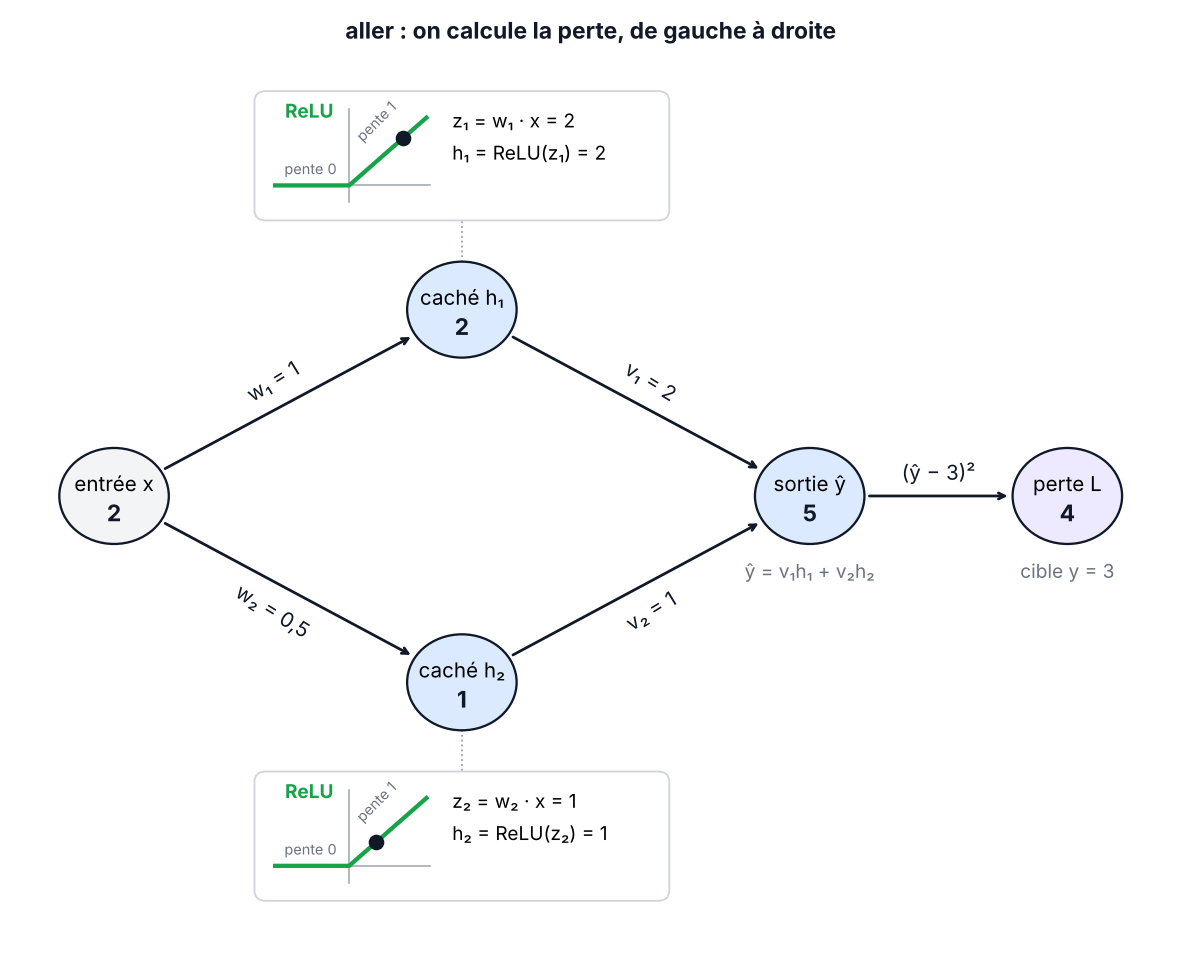

<br>

## Le graphe de calcul : ce que PyTorch a enregistré

### Pendant l'aller, PyTorch a enregistré chaque opération qui utilise un paramètre à apprendre. Ces opérations, reliées dans l'ordre où elles ont été faites, forment le graphe de calcul : le chemin qui mène des paramètres `w` et `v` jusqu'à `perte`. Le voici pour notre réseau, une rangée par calcul de l'aller.

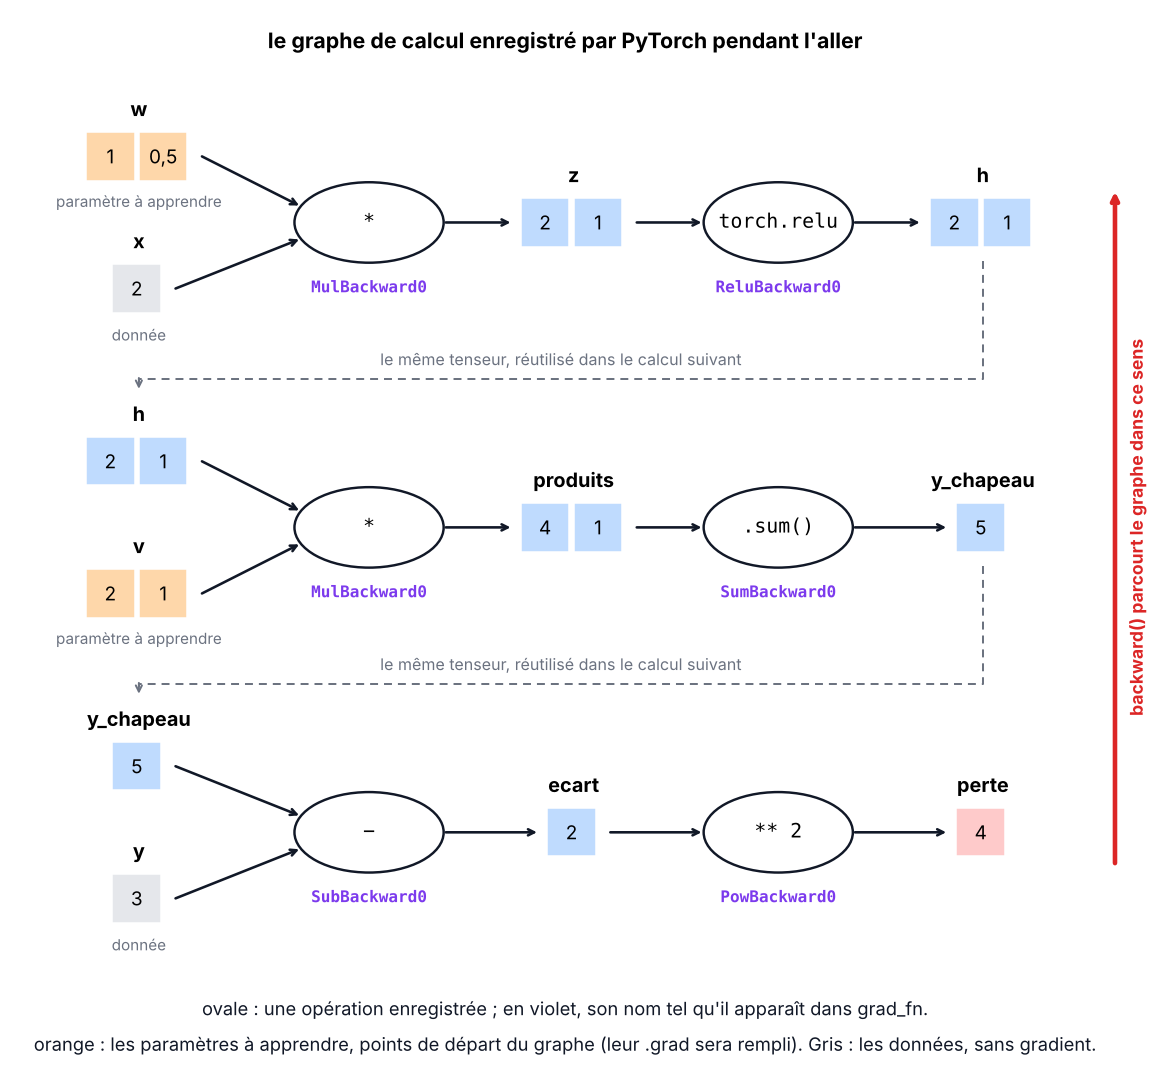

### Chaque tenseur garde dans son attribut `.grad_fn` l'opération qui l'a produit ; `.name()` en donne le nom : Mul (multiplication), Relu, Sum (somme), Sub (soustraction), Pow (puissance). `w` n'est le résultat d'aucune opération : son `.grad_fn` vaut `None`. C'est un point de départ du graphe.

In [33]:
print('z         est produit par :', z.grad_fn.name())
print('h         est produit par :', h.grad_fn.name())
print('produits  est produit par :', produits.grad_fn.name())
print('y_chapeau est produit par :', y_chapeau.grad_fn.name())
print('ecart     est produit par :', ecart.grad_fn.name())
print('perte     est produit par :', perte.grad_fn.name())
print("w, un paramètre, n'est produit par aucune opération :", w.grad_fn)

z         est produit par : MulBackward0
h         est produit par : ReluBackward0
produits  est produit par : MulBackward0
y_chapeau est produit par : SumBackward0
ecart     est produit par : SubBackward0
perte     est produit par : PowBackward0
w, un paramètre, n'est produit par aucune opération : None


### Les opérations sont reliées entre elles : `.next_functions` donne, pour une opération, celles qui la précèdent dans l'aller (`[0][0]` prend la première). En partant de `perte.grad_fn` et en remontant ainsi d'opération en opération, on arrive à `w` et `v` : c'est le chemin que suivra le retour.

In [34]:
derniere = perte.grad_fn                         # l'opération qui a produit perte : ** 2
precedente = derniere.next_functions[0][0]       # celle qui la précède : la soustraction
encore_avant = precedente.next_functions[0][0]   # celle d'avant : la somme
print("dernière opération de l'aller :", derniere.name())
print('celle qui la précède          :', precedente.name())
print("et celle d'encore avant       :", encore_avant.name())

dernière opération de l'aller : PowBackward0
celle qui la précède          : SubBackward0
et celle d'encore avant       : SumBackward0


<br>

## Le retour : `backward()`

### Le retour. `perte.backward()` parcourt le graphe en sens inverse, de `perte` vers `w` et `v`. À chaque opération, il applique la règle de la chaîne, comme dans les cinq étapes de la section 1. À l'arrivée, il range le gradient de chaque paramètre dans son attribut `.grad`, qui valait `None`.

In [35]:
perte.backward()
print('gradients de w1 et w2 (à la main : 16 et 8) :', w.grad, ' forme', w.grad.shape)
print('gradients de v1 et v2 (à la main : 8 et 4)  :', v.grad, ' forme', v.grad.shape)

gradients de w1 et w2 (à la main : 16 et 8) : tensor([16.,  8.])  forme torch.Size([2])
gradients de v1 et v2 (à la main : 8 et 4)  : tensor([8., 4.])  forme torch.Size([2])


### Les quatre gradients sont ceux de la section 1, rappelés sur son schéma : ∂L/∂w₁ = 16, ∂L/∂w₂ = 8, ∂L/∂v₁ = 8, ∂L/∂v₂ = 4. ✏️ Dans la cellule qui crée `w`, changez `0.5` pour `-0.5` et réexécutez jusqu'ici : que devient le gradient de ce poids, et pourquoi ? Remettez ensuite `0.5` et réexécutez.

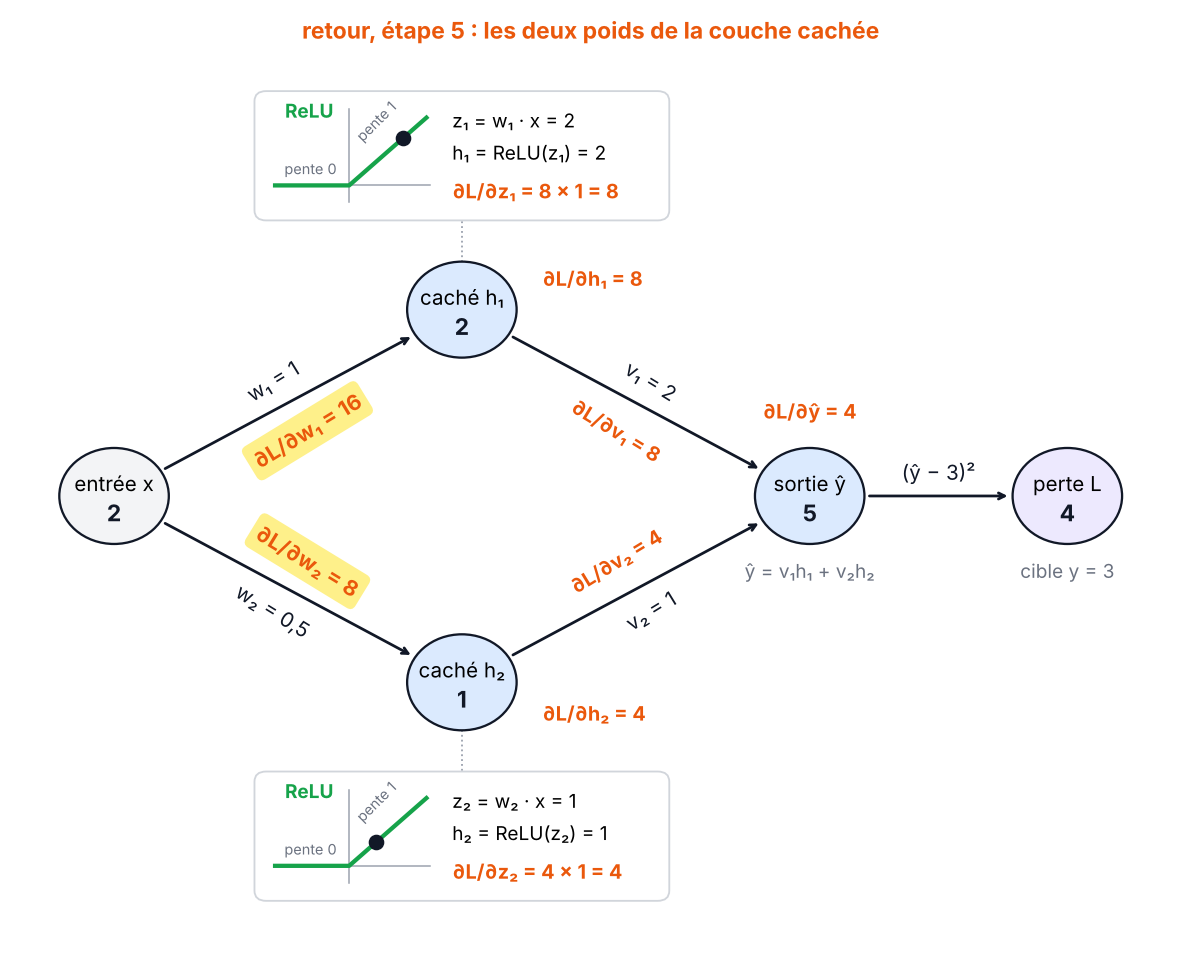

<br>

## Un lot de données : les gradients s'additionnent dans `.grad`

### Jusqu'ici, une seule donnée : entrée 2, cible 3. En pratique on apprend sur un lot (batch) : plusieurs données ensemble. Pour refaire l'aller sur une autre donnée, on range ses lignes dans une fonction : `def` la définit, elle reçoit une entrée et une cible, et `return` renvoie la perte.

In [36]:
def calculer_perte(x, y):
    h = torch.relu(w * x)            # les 2 neurones cachés
    y_chapeau = (v * h).sum()        # la sortie
    return (y_chapeau - y) ** 2      # la perte
print('perte de la donnée 1 (entrée 2, cible 3), comme plus haut :', calculer_perte(2.0, 3.0))

perte de la donnée 1 (entrée 2, cible 3), comme plus haut : tensor(4., grad_fn=<PowBackward0>)


### Deuxième donnée : entrée x = 1, cible y = 2. Sa sortie, puis son gradient par rapport à w₁ et w₂, par la chaîne complète de la section 1 :

$$\Large \boxed{\;\begin{aligned}
\rule{0pt}{20pt}\hat y &= v_1 h_1 + v_2 h_2 = 2 \times 1 + 1 \times 0{,}5 = 2{,}5 \\[14pt]
\frac{\partial L_2}{\partial w_1} &= \underbrace{2\,(\hat y - y)}_{2\,(2{,}5 - 2)\,=\,1} \times \underbrace{v_1}_{2} \times \underbrace{\text{pente de ReLU}}_{1} \times \underbrace{x}_{1} = 2 \\[14pt]
\frac{\partial L_2}{\partial w_2} &= \underbrace{2\,(\hat y - y)}_{1} \times \underbrace{v_2}_{1} \times \underbrace{\text{pente de ReLU}}_{1} \times \underbrace{x}_{1} = 1 \rule[-22pt]{0pt}{0pt}
\end{aligned}\;}$$

### `w.grad` contient déjà le gradient de la donnée 1 : 16 et 8. On calcule la perte de la donnée 2 avec la fonction, puis on appelle `backward()` une deuxième fois.

In [37]:
print('w.grad avant : le gradient de la donnée 1         :', w.grad)
perte_2 = calculer_perte(1.0, 2.0)               # la donnée 2 : entrée 1, cible 2
perte_2.backward()
print('w.grad après le backward() de la donnée 2         :', w.grad)

w.grad avant : le gradient de la donnée 1         : tensor([16.,  8.])
w.grad après le backward() de la donnée 2         : tensor([18.,  9.])


### `w.grad` vaut maintenant 18 et 9, soit 16 + 2 et 8 + 1 : `backward()` n'a pas remplacé le contenu de `.grad`, il y a ajouté le nouveau gradient. C'est voulu. La perte d'un lot est la somme des pertes de ses données, et le gradient d'une somme est la somme des gradients : `.grad` contient maintenant le gradient du lot.

$$\Large \boxed{\;L_{\text{lot}} = L_1 + L_2 \;\;\Longrightarrow\;\; \frac{\partial L_{\text{lot}}}{\partial w} = \frac{\partial L_1}{\partial w} + \frac{\partial L_2}{\partial w}\;}$$

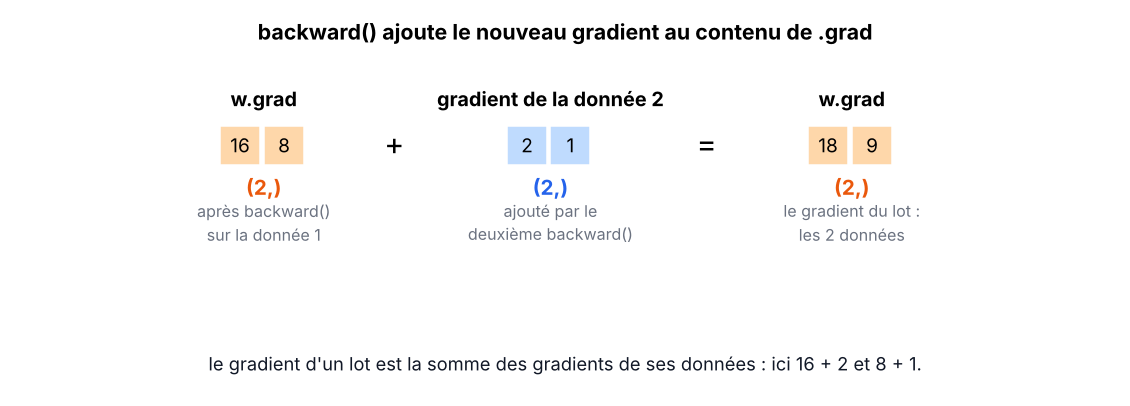

<br>

## Les époques : remettre `.grad` à zéro avant chaque nouveau calcul

### Une époque est un passage complet sur les données d'entraînement. Dans la descente de gradient par lot (batch gradient descent), chaque époque fait un aller sur tout le lot, un retour, puis une mise à jour des poids. L'époque 1 en est à la mise à jour : voici ses gradients.

In [38]:
pas = 0.01                       # le pas (taux d'apprentissage), comme en section 1
print("fin du retour de l'époque 1, gradient du lot pour w :", w.grad)
print("fin du retour de l'époque 1, gradient du lot pour v :", v.grad)

fin du retour de l'époque 1, gradient du lot pour w : tensor([18.,  9.])
fin du retour de l'époque 1, gradient du lot pour v : tensor([9.000, 4.500])


### La mise à jour : `w -= pas * w.grad` soustrait à chaque poids son gradient multiplié par le pas (`-=` modifie `w` sur place). Elle est écrite dans un bloc `with torch.no_grad():`, qui suspend l'enregistrement des opérations : la mise à jour ne fait pas partie de l'aller et ne doit pas entrer dans le graphe de calcul.

In [39]:
with torch.no_grad():            # pas d'enregistrement dans le graphe pendant la mise à jour
    w -= pas * w.grad
    v -= pas * v.grad
print("poids w après la mise à jour de l'époque 1 :", w)
print("poids v après la mise à jour de l'époque 1 :", v)

poids w après la mise à jour de l'époque 1 : tensor([0.820, 0.410], requires_grad=True)
poids v après la mise à jour de l'époque 1 : tensor([1.910, 0.955], requires_grad=True)


### Époque 2 : les poids ont changé, il faut le gradient du lot calculé avec les nouveaux poids. 🔮 On refait l'aller sur les deux données (`+` additionne leurs pertes) et `backward()`, sans toucher à `w.grad`, qui contient encore 18 et 9. Que contiendra `w.grad` ?

In [40]:
perte_lot = calculer_perte(2.0, 3.0) + calculer_perte(1.0, 2.0)   # la perte du lot : la somme des 2 pertes
perte_lot.backward()
print('époque 2, sans remise à zéro : w.grad =', w.grad)

époque 2, sans remise à zéro : w.grad = tensor([24.833, 12.417])


### `w.grad` vaut 24,83 et 12,42 : ce sont 18 et 9, le gradient de l'époque 1 calculé avec les anciens poids, plus le gradient de l'époque 2. Cette somme n'est le gradient d'aucune perte : une mise à jour faite avec elle serait fausse, sans aucun message d'erreur.

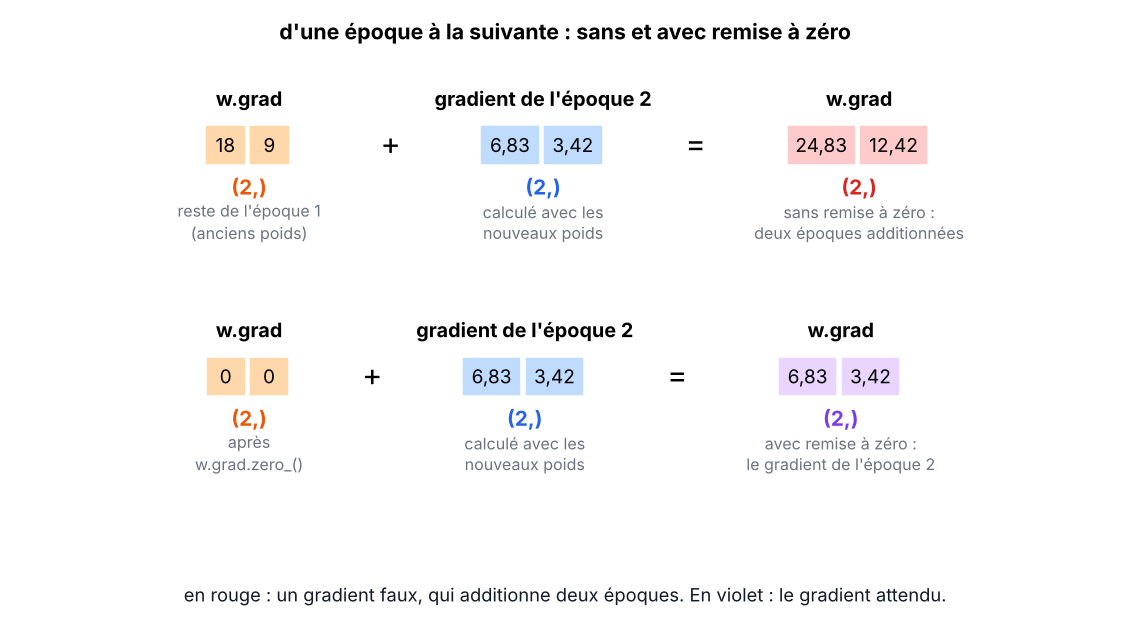

### La solution : `w.grad.zero_()` remet à zéro le contenu de `w.grad` (le `_` final signale une opération qui modifie le tenseur sur place). On le fait pour chaque paramètre, puis on refait l'aller et le retour de l'époque 2.

In [41]:
w.grad.zero_()                   # remise à zéro du gradient stocké pour w
v.grad.zero_()                   # et pour v
perte_lot = calculer_perte(2.0, 3.0) + calculer_perte(1.0, 2.0)
perte_lot.backward()
print('époque 2, après remise à zéro : w.grad =', w.grad)

époque 2, après remise à zéro : w.grad = tensor([6.833, 3.417])


### `w.grad` vaut 6,83 et 3,42 : le gradient de l'époque 2 seule. La règle : remettre les gradients à zéro avant chaque nouveau calcul, donc une fois par époque ici. Avec des mini-lots (descente de gradient stochastique, SGD), une mise à jour par mini-lot : la remise à zéro se fait avant chacune. C'est l'étape 3 de la boucle.

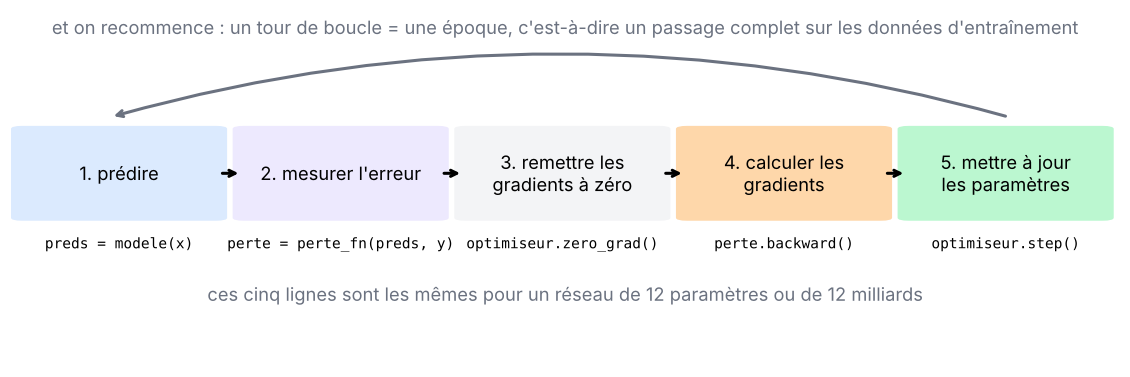

<br>

## Avec des matrices : iris

### Même chose avec des matrices, sur un vrai jeu de données : iris, 112 fleurs, 4 mesures par fleur, 3 espèces. Chaque espèce est codée « un chaud » (one-hot) : un 1 dans la colonne de la bonne espèce, 0 ailleurs.

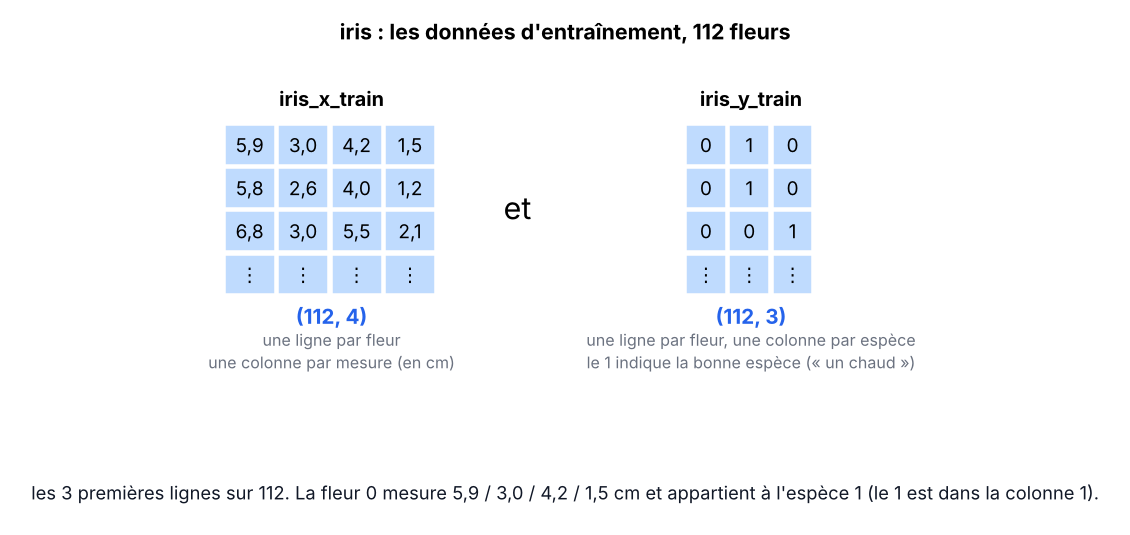

### Les tenseurs `iris_x_train` et `iris_y_train` viennent de la boîte à outils. On affiche leur forme, puis leurs 2 premières lignes : `[:2]` sélectionne les lignes 0 et 1.

In [42]:
print('forme de iris_x_train :', iris_x_train.shape, '(112 fleurs, 4 mesures)')
print('forme de iris_y_train :', iris_y_train.shape, '(112 fleurs, 3 cases, une par espèce)')
print(f'mesures des 2 premières fleurs :\n{iris_x_train[:2]}')
print(f'leurs espèces, en « un chaud » :\n{iris_y_train[:2]}')

forme de iris_x_train : torch.Size([112, 4]) (112 fleurs, 4 mesures)
forme de iris_y_train : torch.Size([112, 3]) (112 fleurs, 3 cases, une par espèce)
mesures des 2 premières fleurs :
tensor([[5.900, 3.000, 4.200, 1.500],
        [5.800, 2.600, 4.000, 1.200]])
leurs espèces, en « un chaud » :
tensor([[0., 1., 0.],
        [0., 1., 0.]])


### Le modèle est un réseau sans couche cachée : 4 neurones d'entrée (les 4 mesures d'une fleur) et 3 neurones de sortie (un score par espèce). Chaque entrée est reliée à chaque sortie : 4 × 3 = 12 connexions, donc 12 poids, rangés dans une matrice de forme (4, 3). Leurs valeurs de départ sont tirées au hasard.

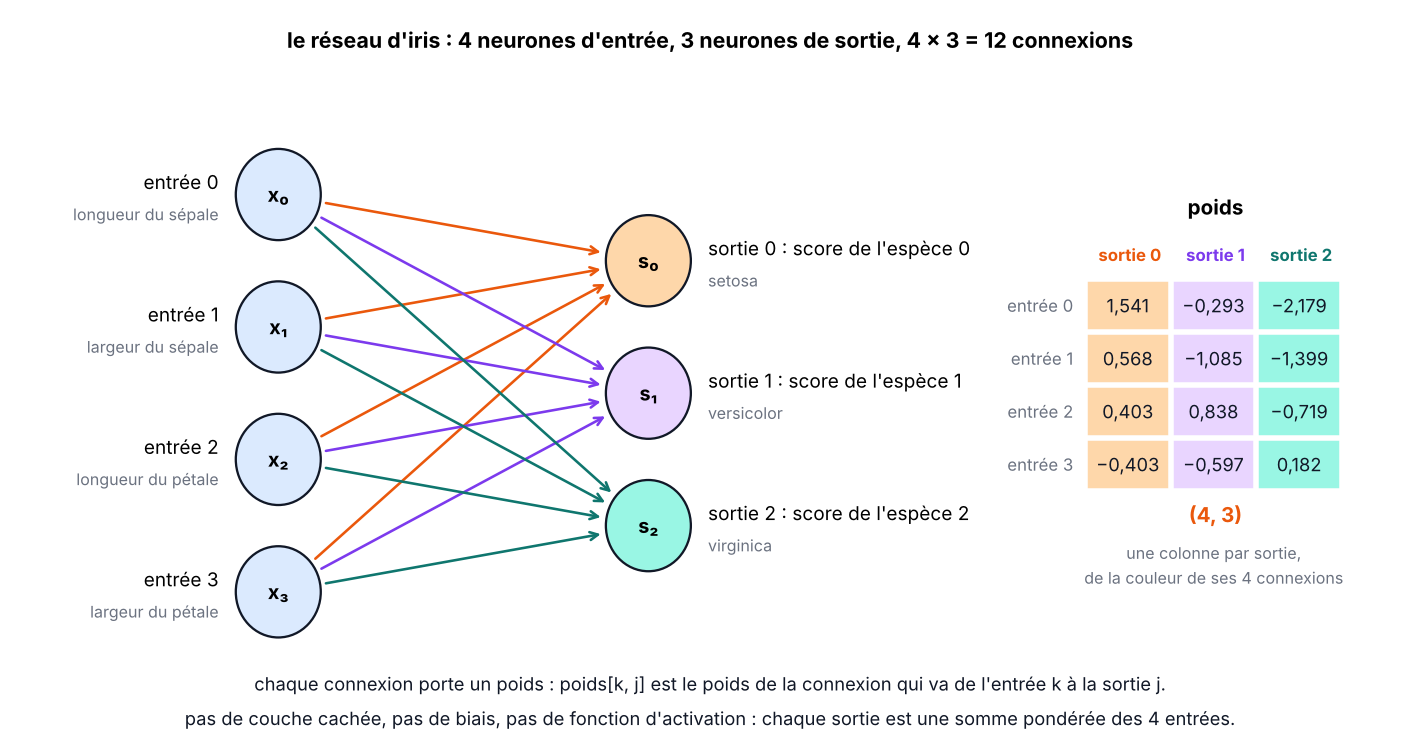

### `torch.randn(4, 3, requires_grad=True)` crée cette matrice : des valeurs aléatoires, déclarées comme paramètres à apprendre. `torch.manual_seed(0)` fixe le tirage : tout le monde obtient les mêmes nombres.

In [43]:
torch.manual_seed(0)
poids = torch.randn(4, 3, requires_grad=True)
print(f'les 12 poids de départ (4 mesures x 3 espèces) :\n{poids}')

les 12 poids de départ (4 mesures x 3 espèces) :
tensor([[ 1.541, -0.293, -2.179],
        [ 0.568, -1.085, -1.399],
        [ 0.403,  0.838, -0.719],
        [-0.403, -0.597,  0.182]], requires_grad=True)


<br>

## L'aller : les prédictions, puis la perte

### Les prédictions : le produit de la matrice des données par celle des poids fait passer les 112 fleurs dans le réseau en une opération. Chaque fleur (une ligne) est multipliée par chaque colonne de poids, ce qui donne ses 3 scores, un par sortie.

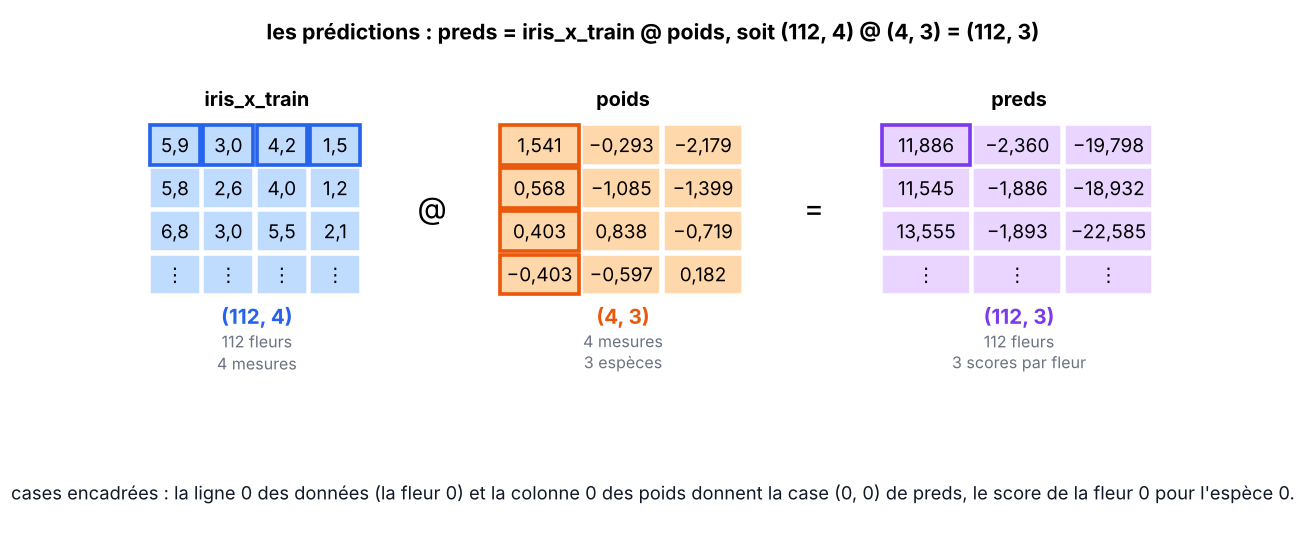

### `torch.mm` fait ce produit de matrices : (112, 4) par (4, 3) donne (112, 3). `.detach()` renvoie le tenseur détaché du graphe de calcul : son affichage n'a plus de `grad_fn`. `[:3]` sélectionne les 3 premières lignes.

$$\Large \boxed{\;\text{preds} = X\,W\;}$$

In [44]:
preds = torch.mm(iris_x_train, poids)
print('forme de preds :', preds.shape, '(112 fleurs, 3 scores chacune)')
print(f'les 3 premières lignes de preds :\n{preds[:3].detach()}')

forme de preds : torch.Size([112, 3]) (112 fleurs, 3 scores chacune)
les 3 premières lignes de preds :
tensor([[ 11.886,  -2.360, -19.798],
        [ 11.545,  -1.886, -18.932],
        [ 13.555,  -1.893, -22.585]])


### Le détail d'une case : le score de la fleur 0 pour l'espèce 0. Ses 4 mesures entrent dans le réseau ; chacune est multipliée par le poids de sa connexion vers la sortie 0, puis les 4 produits sont additionnés.

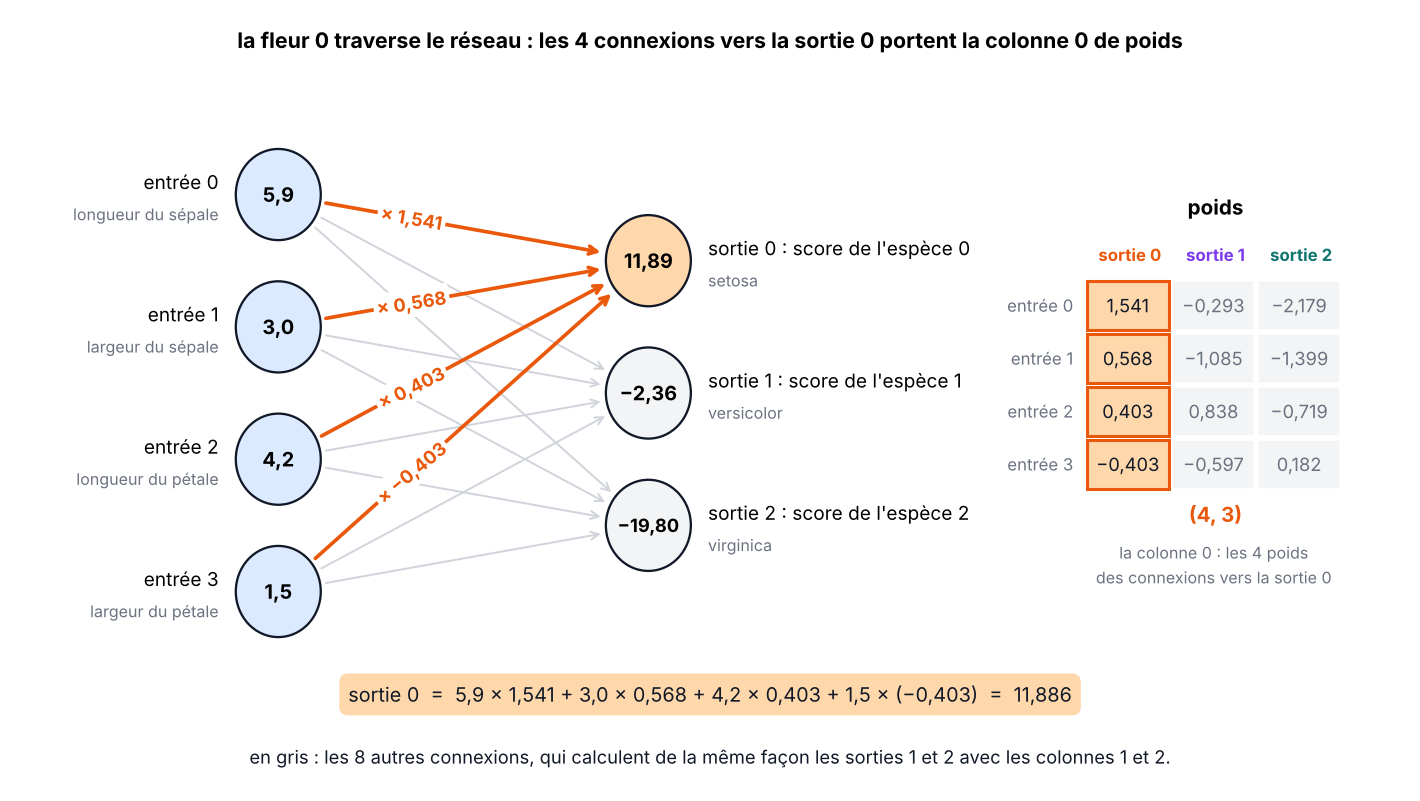

### Le même calcul écrit avec les tenseurs, pour les trois sorties : la ligne 0 des données est multipliée terme à terme par une colonne de poids, puis on additionne.

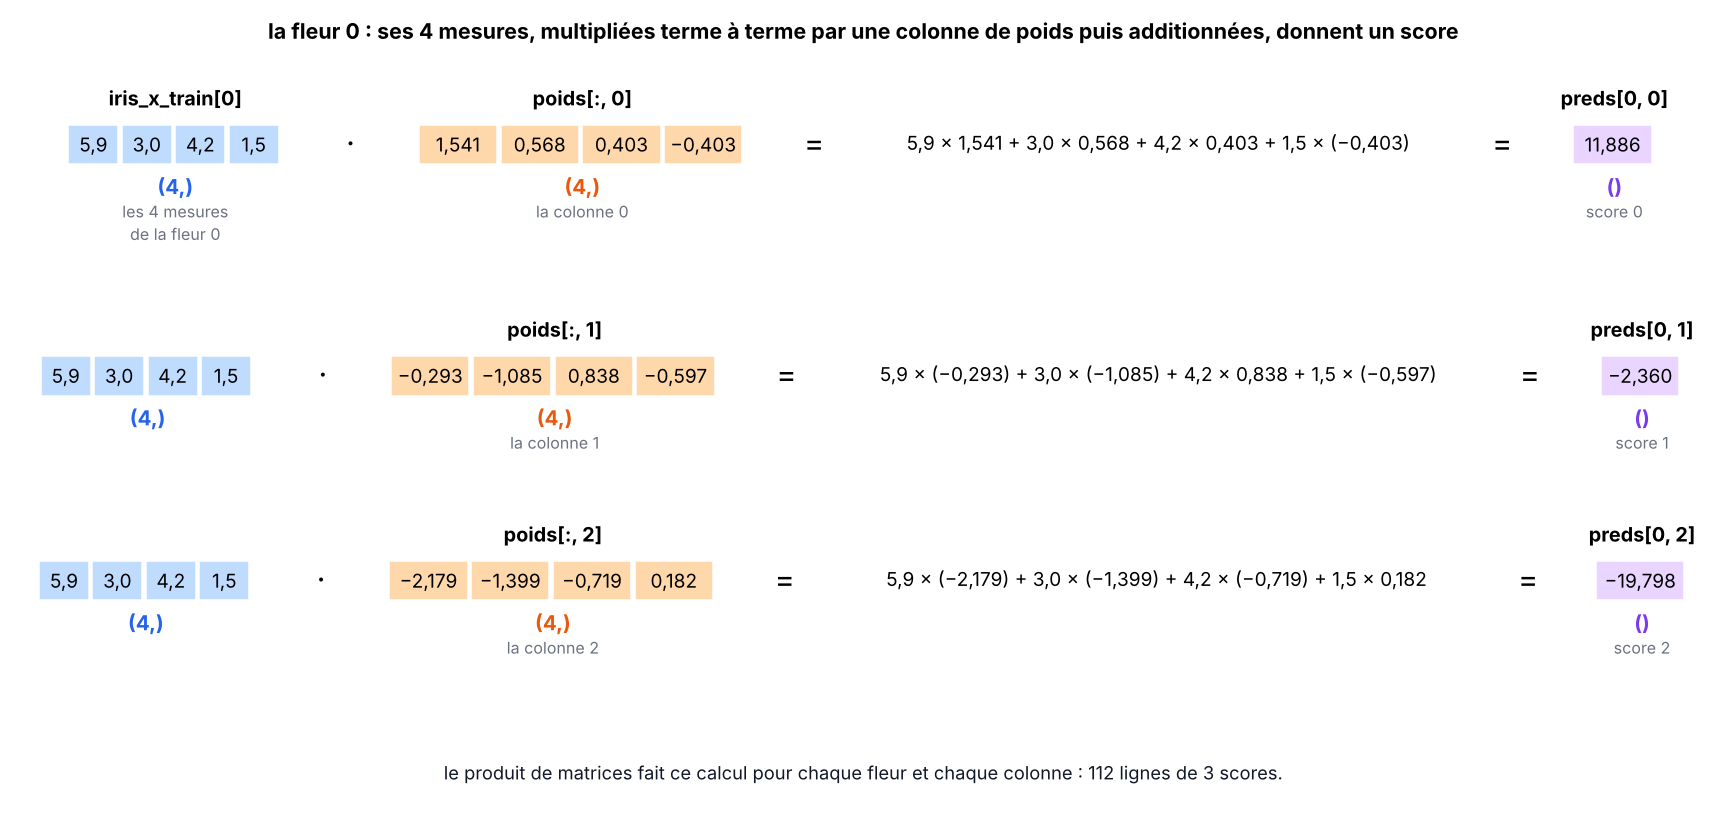

### `iris_x_train[0]` est la ligne 0 : les 4 mesures de la fleur 0. `poids[:, 0]` est la colonne 0 des poids (`:` signifie « toutes les lignes »), affichée avec `.detach()`, sans `grad_fn`.

In [45]:
print('mesures de la fleur 0 :', iris_x_train[0])
print('colonne 0 des poids   :', poids[:, 0].detach())

mesures de la fleur 0 : tensor([5.900, 3.000, 4.200, 1.500])
colonne 0 des poids   : tensor([ 1.541,  0.568,  0.403, -0.403])


### `*` multiplie élément par élément, `.sum()` additionne. `.item()` convertit un tenseur à un seul élément en nombre Python, que `round` arrondit. On retrouve le premier nombre de `preds[0]`, la ligne des 3 scores de cette fleur.

In [46]:
score_0 = (iris_x_train[0] * poids[:, 0]).sum()
print('score 0 à la main, somme des produits :', round(score_0.item(), 3))
print('les 3 scores de la fleur 0 dans preds  :', preds[0].detach())

score 0 à la main, somme des produits : 11.886
les 3 scores de la fleur 0 dans preds  : tensor([ 11.886,  -2.360, -19.798])


### La perte : on soustrait les cibles des scores, on met chaque écart au carré, puis on fait la moyenne des 112 × 3 = 336 cases.

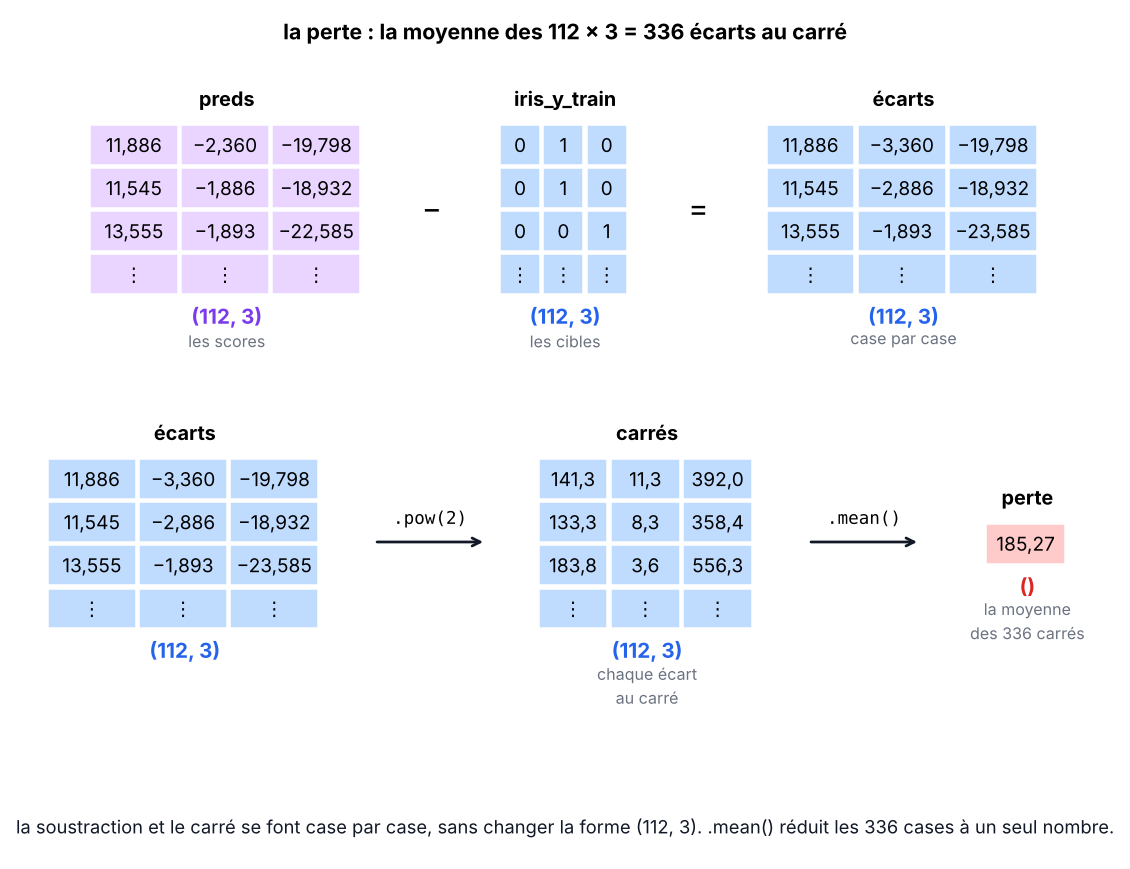

### En code : `-` soustrait case par case, `.pow(2)` met chaque élément au carré, `.mean()` fait la moyenne de tous les éléments.

$$\Large \boxed{\;L = \frac{1}{336} \sum_{i,j} \left(\text{preds}_{i,j} - Y_{i,j}\right)^2\;}$$

In [47]:
perte = (preds - iris_y_train).pow(2).mean()
print('perte de départ :', perte)

perte de départ : tensor(185.268, grad_fn=<MeanBackward0>)


<br>

## Le gradient d'iris : désigner une case avec des indices

### Pour écrire le gradient, il faut désigner une case précise de chaque matrice, avec trois indices : i numérote les fleurs, k les mesures, j les espèces. $X_{i,k}$ est la mesure k de la fleur i, $W_{k,j}$ le poids de la connexion entre l'entrée k et la sortie j, $\text{preds}_{i,j}$ le score j de la fleur i.

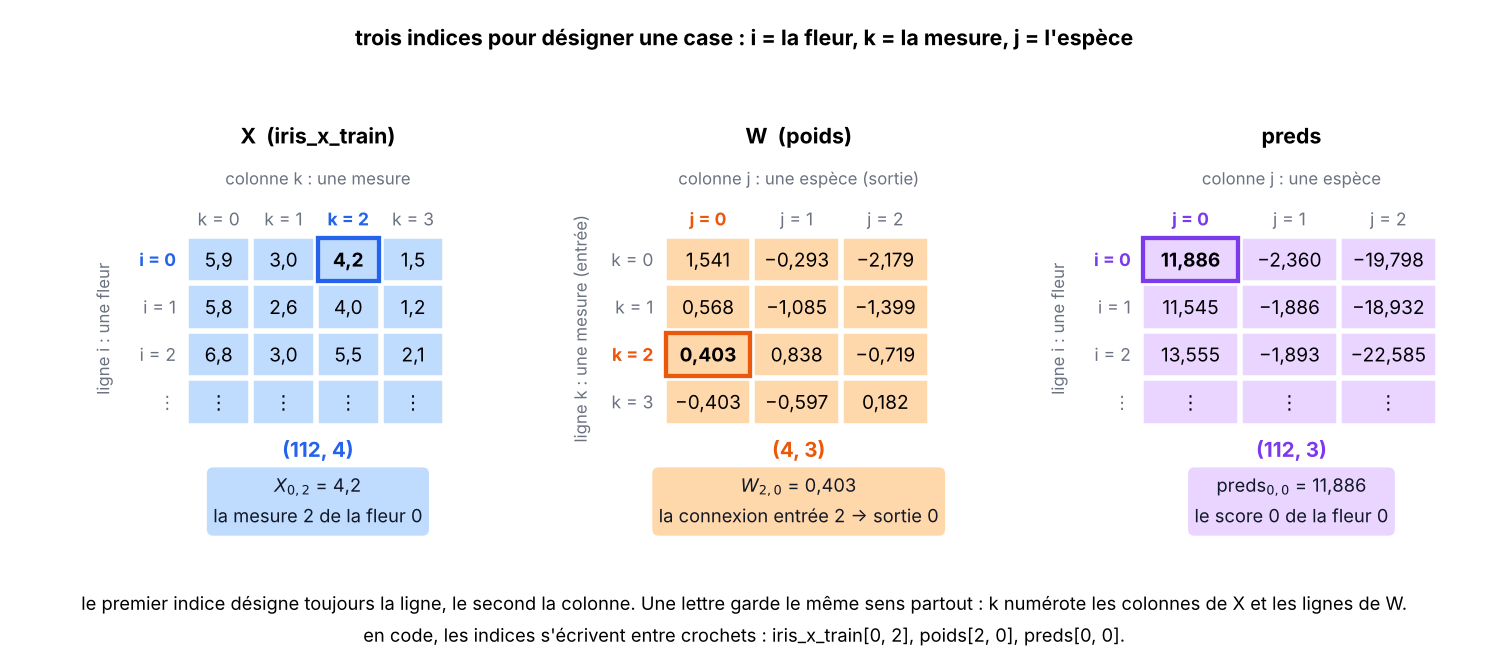

### En code, les deux indices s'écrivent entre crochets, la ligne puis la colonne : `iris_x_train[0, 2]` est $X_{0,2}$, `poids[2, 0]` est $W_{2,0}$, `preds[0, 0]` est $\text{preds}_{0,0}$. `.item()` donne le nombre Python, que `round` arrondit.

In [48]:
print('X[0, 2], la mesure 2 de la fleur 0                       :', round(iris_x_train[0, 2].item(), 1))
print('W[2, 0], le poids de la connexion entrée 2 vers sortie 0 :', round(poids[2, 0].item(), 3))
print('preds[0, 0], le score 0 de la fleur 0                    :', round(preds[0, 0].item(), 3))

X[0, 2], la mesure 2 de la fleur 0                       : 4.2
W[2, 0], le poids de la connexion entrée 2 vers sortie 0 : 0.403
preds[0, 0], le score 0 de la fleur 0                    : 11.886


<br>

## Le gradient à la main, étape 1 : de la perte aux prédictions

### Trois étapes, comme en section 1, en remontant de la perte vers les poids. Étape 1 : de combien change la perte quand une prédiction change ? La figure situe l'étape et rappelle les notations.

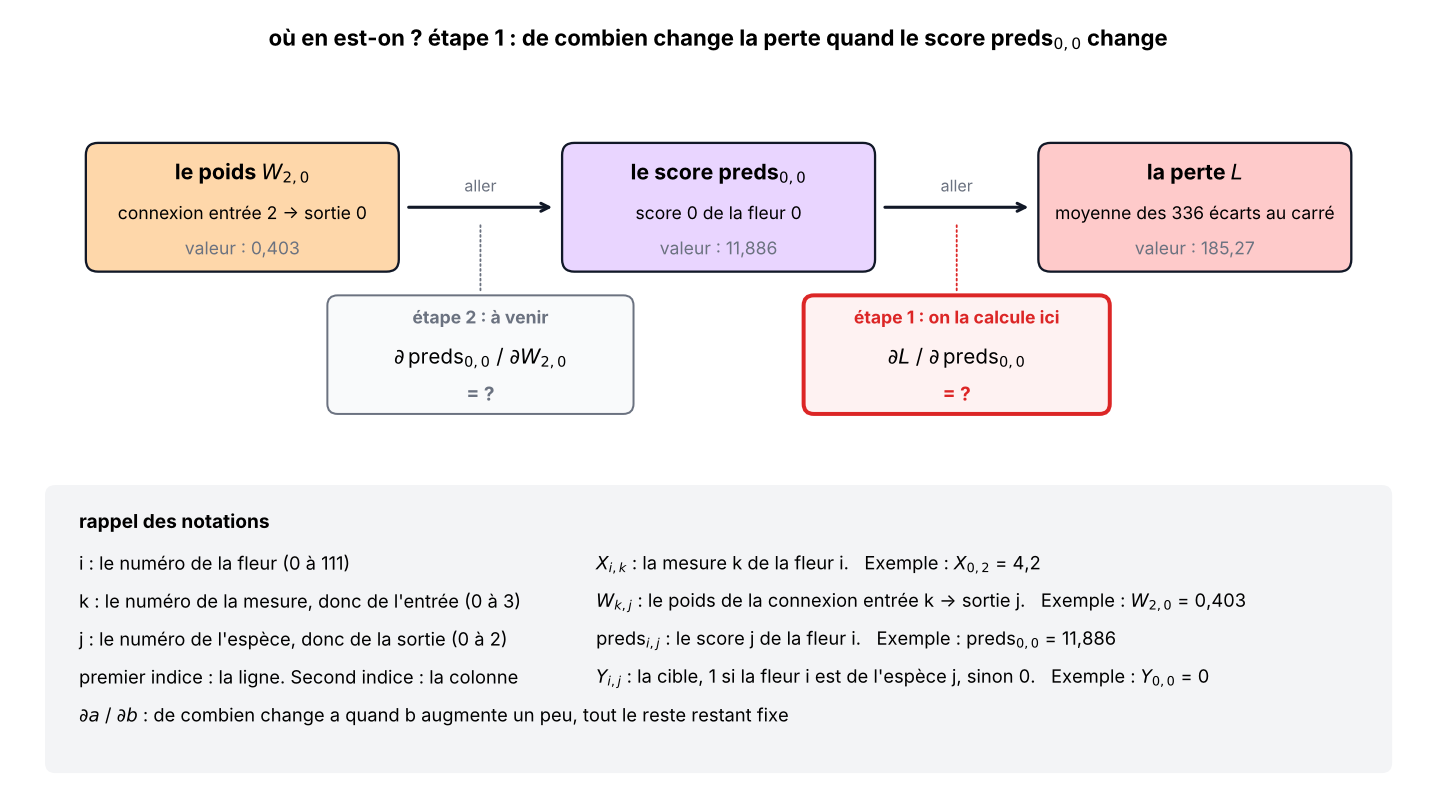

### On fait le calcul pour une seule case, $\text{preds}_{0,0}$, le score 0 de la fleur 0, en écrivant la perte en entier : la moyenne de 336 carrés, dont un seul contient $\text{preds}_{0,0}$.

$$\Large \boxed{\;\begin{aligned}
\rule{0pt}{26pt}L &= \frac{1}{336}\Big[(\text{preds}_{0,0} - Y_{0,0})^2 + (\text{preds}_{0,1} - Y_{0,1})^2 + \dots + (\text{preds}_{111,2} - Y_{111,2})^2\Big] \\[5pt]
 &{\normalsize\text{la perte écrite en entier : 336 carrés, un par case}} \\[22pt]
\frac{\partial L}{\partial\,\text{preds}_{0,0}} &= \frac{1}{336}\Big[\frac{\partial}{\partial\,\text{preds}_{0,0}}(\text{preds}_{0,0} - Y_{0,0})^2 + 0 + \dots + 0\Big] \\[5pt]
 &{\normalsize\text{dérivée d'une somme : terme par terme.}} \\[5pt]
 &{\normalsize\text{Les 335 autres carrés ne contiennent pas cette prédiction : leur dérivée vaut 0}} \\[22pt]
 &= \frac{1}{336} \times 2\,(\text{preds}_{0,0} - Y_{0,0}) \times 1 \\[5pt]
 &{\normalsize\text{règle du carré : la dérivée de u² est 2u fois la dérivée de u.}} \\[5pt]
 &{\normalsize\text{Ici u est l'écart entre la prédiction et la cible, et sa dérivée vaut 1}} \\[22pt]
 &= \frac{2\,(\text{preds}_{0,0} - Y_{0,0})}{336} = \frac{2 \times (11{,}886 - 0)}{336} = 0{,}0708 \\[5pt]
 &{\normalsize\text{avec les nombres de la fleur 0, qui n'est pas de l'espèce 0 : sa cible vaut 0}} \rule[-16pt]{0pt}{0pt}
\end{aligned}\;}$$

### Le même calcul vaut pour chacune des 336 cases : on remplace la fleur 0 par une fleur i, et le score 0 par un score j.

$$\Large \boxed{\;\frac{\partial L}{\partial\,\text{preds}_{i,j}} = \frac{2\,(\text{preds}_{i,j} - Y_{i,j})}{336}\;}$$

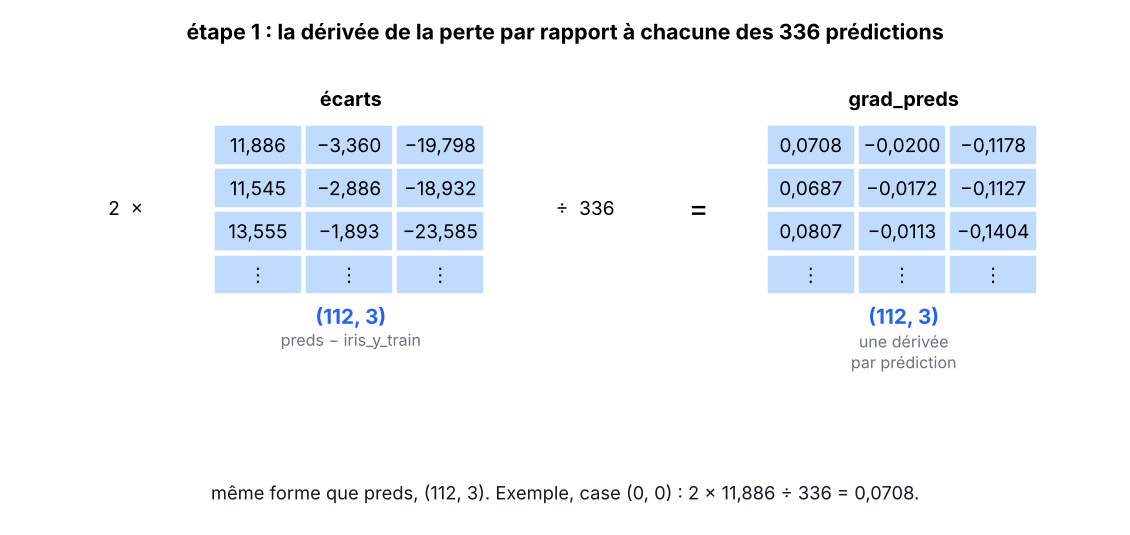

### Le code applique cette formule aux 336 cases à la fois : `2 *` et `/` agissent sur chaque élément.

In [49]:
grad_preds = 2 * (preds - iris_y_train) / (112 * 3)     # étape 1
print('forme de grad_preds :', grad_preds.shape, '(une dérivée par prédiction)')
print(f'les 3 premières lignes de grad_preds :\n{grad_preds[:3].detach()}')

forme de grad_preds : torch.Size([112, 3]) (une dérivée par prédiction)
les 3 premières lignes de grad_preds :
tensor([[ 0.071, -0.020, -0.118],
        [ 0.069, -0.017, -0.113],
        [ 0.081, -0.011, -0.140]])


<br>

## Étape 2 : des prédictions aux poids

### Étape 2 : de combien change un score quand un poids change ? Un exemple : le score 0 de la fleur 0, $\text{preds}_{0,0}$, et le poids $W_{2,0}$, celui de la connexion qui va de l'entrée 2 à la sortie 0.

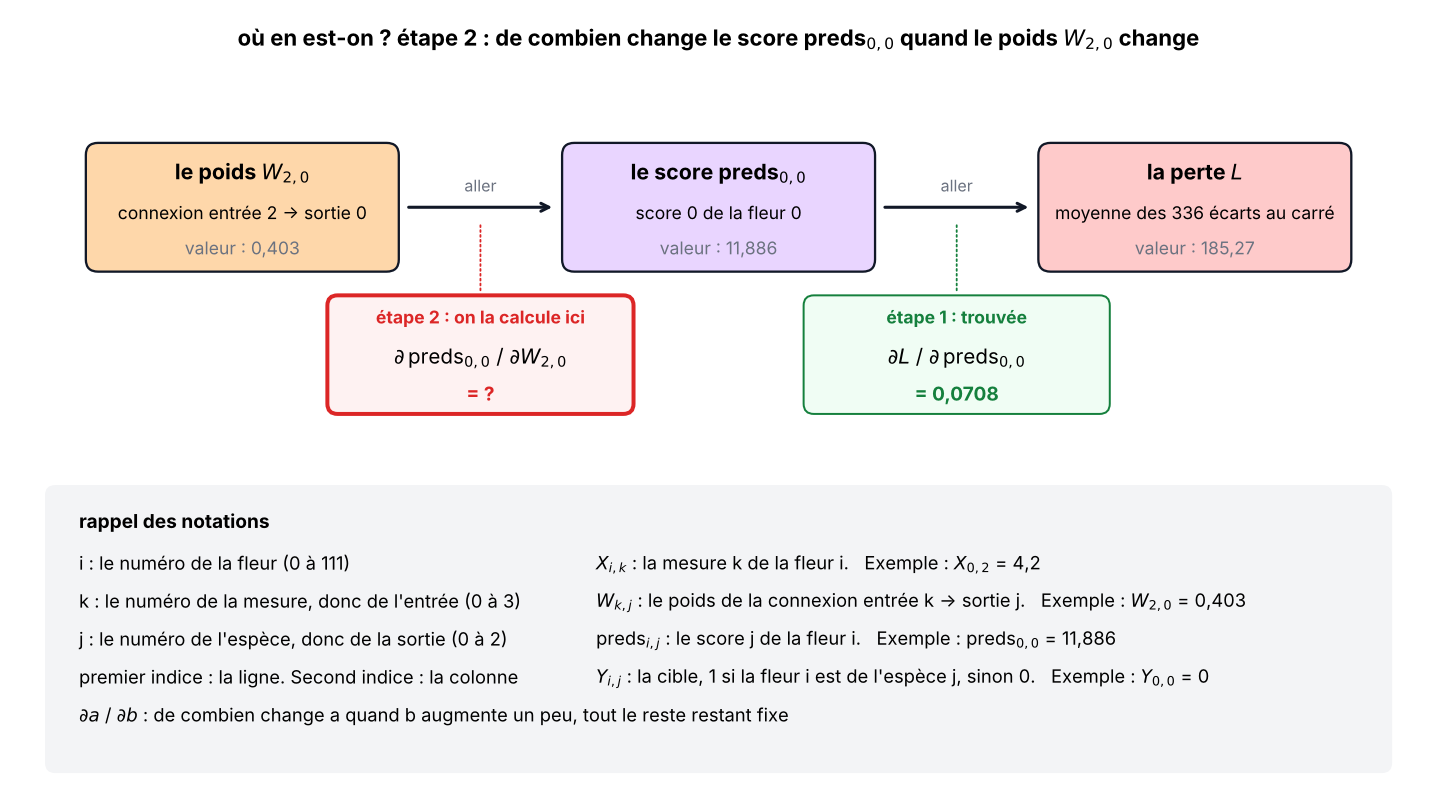

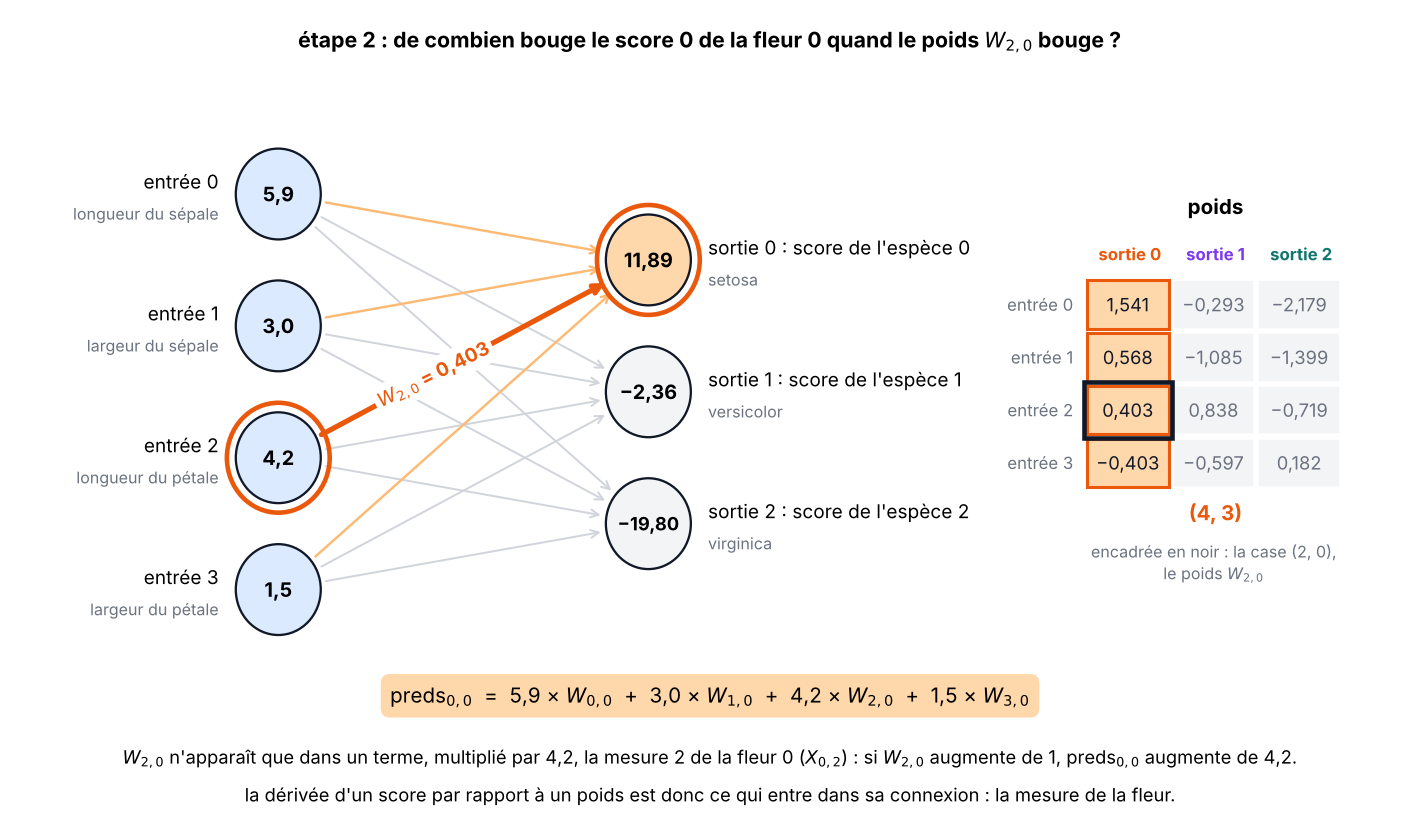

### Le calcul, terme par terme : on écrit le score en entier, puis on dérive chacun de ses 4 termes par rapport à $W_{2,0}$. La cellule vérifie ensuite comme en section 1 : 0,001 ajouté à $W_{2,0}$ dans une copie de la colonne 0 des poids.

$$\Large \boxed{\;\begin{aligned}
\rule{0pt}{26pt}\text{preds}_{0,0} &= X_{0,0}W_{0,0} + X_{0,1}W_{1,0} + X_{0,2}W_{2,0} + X_{0,3}W_{3,0} \\[5pt]
 &{\normalsize\text{le score 0 de la fleur 0, écrit en entier :}} \\[5pt]
 &{\normalsize\text{ses 4 mesures, chacune multipliée par un poids de la colonne 0}} \\[22pt]
\frac{\partial\,\text{preds}_{0,0}}{\partial W_{2,0}} &= \frac{\partial (X_{0,0}W_{0,0})}{\partial W_{2,0}} + \frac{\partial (X_{0,1}W_{1,0})}{\partial W_{2,0}} + \frac{\partial (X_{0,2}W_{2,0})}{\partial W_{2,0}} + \frac{\partial (X_{0,3}W_{3,0})}{\partial W_{2,0}} \\[5pt]
 &{\normalsize\text{dérivée d'une somme : terme par terme}} \\[22pt]
 &= 0 + 0 + X_{0,2} + 0 \\[5pt]
 &{\normalsize\text{trois termes ne contiennent pas ce poids : leur dérivée vaut 0.}} \\[5pt]
 &{\normalsize\text{Dans le troisième, le poids est multiplié par un nombre fixe : la dérivée est ce nombre}} \\[22pt]
 &= X_{0,2} = 4{,}2 \\[5pt]
 &{\normalsize\text{la mesure 2 de la fleur 0}} \rule[-16pt]{0pt}{0pt}
\end{aligned}\;}$$

In [50]:
colonne_essai = poids[:, 0].detach() + torch.tensor([0.0, 0.0, 0.001, 0.0])    # la colonne 0, avec W[2, 0] augmenté de 0.001
score_avant = (iris_x_train[0] * poids[:, 0]).sum().item()                     # preds[0, 0]
score_apres = (iris_x_train[0] * colonne_essai).sum().item()                   # le même calcul, avec la colonne modifiée
print('changement du score 0 de la fleur 0 quand W[2, 0] augmente de 0.001 :', round(score_apres - score_avant, 4))
print('ce changement divisé par 0.001 (attendu : X[0, 2] = 4.2)            :', round((score_apres - score_avant) / 0.001, 1))

changement du score 0 de la fleur 0 quand W[2, 0] augmente de 0.001 : 0.0042
ce changement divisé par 0.001 (attendu : X[0, 2] = 4.2)            : 4.2


### Et les deux autres scores de la fleur 0 ? Chaque score a ses 4 poids à lui : une colonne de la matrice `poids`. $W_{2,0}$ est dans la colonne 0 : c'est la connexion qui arrive à la sortie 0. Les scores 1 et 2 sont calculés sans lui : si $W_{2,0}$ change, ils ne changent pas.

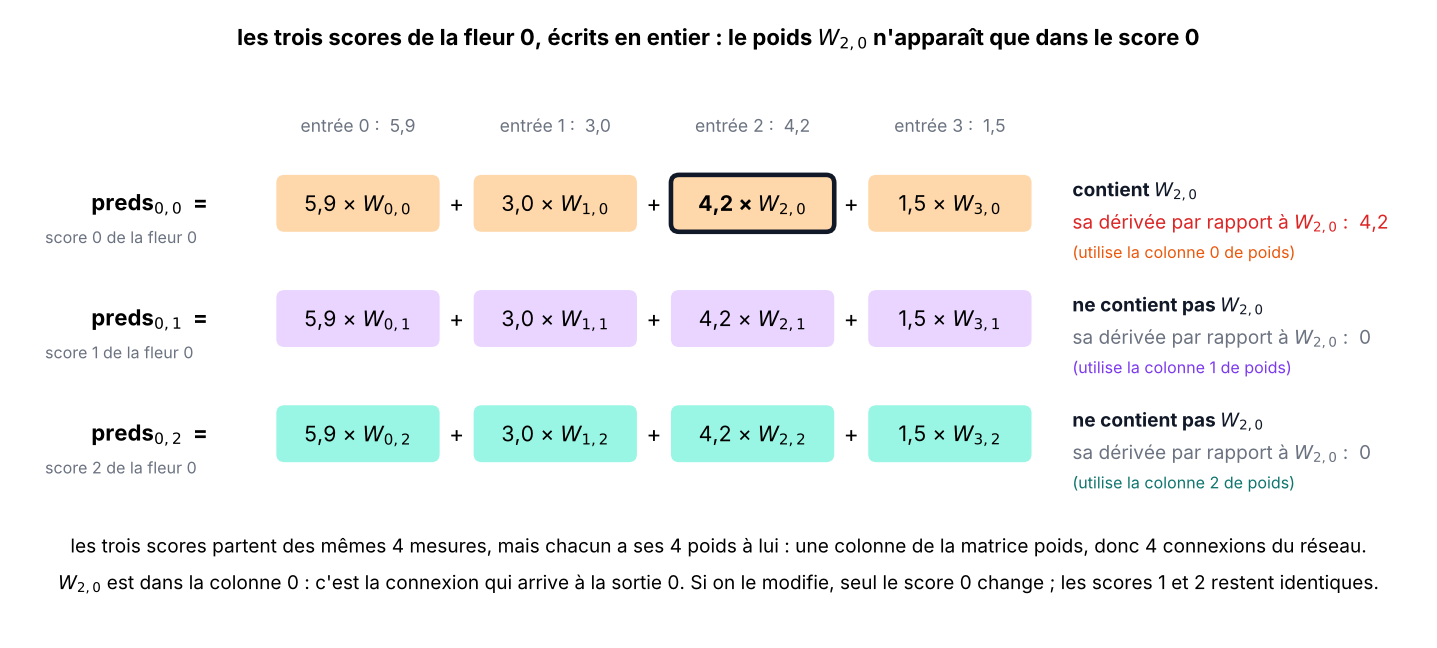

### En équations : on écrit les scores 1 et 2 en entier, et on dérive chaque terme par rapport à $W_{2,0}$. Aucun terme ne le contient.

$$\Large \boxed{\;\begin{aligned}
\rule{0pt}{26pt}\text{preds}_{0,1} &= X_{0,0}W_{0,1} + X_{0,1}W_{1,1} + X_{0,2}W_{2,1} + X_{0,3}W_{3,1} \\[5pt]
 &{\normalsize\text{le score 1 de la fleur 0 : ses 4 mesures, fois les poids de la colonne 1}} \\[22pt]
\frac{\partial\,\text{preds}_{0,1}}{\partial W_{2,0}} &= 0 + 0 + 0 + 0 = 0 \\[5pt]
 &{\normalsize\text{aucun des 4 termes ne contient le poids (2, 0) : chaque dérivée vaut 0}} \\[22pt]
\text{preds}_{0,2} &= X_{0,0}W_{0,2} + X_{0,1}W_{1,2} + X_{0,2}W_{2,2} + X_{0,3}W_{3,2} \\[5pt]
 &{\normalsize\text{le score 2 de la fleur 0 : ses 4 mesures, fois les poids de la colonne 2}} \\[22pt]
\frac{\partial\,\text{preds}_{0,2}}{\partial W_{2,0}} &= 0 + 0 + 0 + 0 = 0 \\[5pt]
 &{\normalsize\text{même raison}} \rule[-16pt]{0pt}{0pt}
\end{aligned}\;}$$

$$\Large \boxed{\;\begin{aligned}
\rule{0pt}{26pt}\frac{\partial\,\text{preds}_{i,j}}{\partial W_{k,j}} &= X_{i,k} \\[5pt]
 &{\normalsize\text{règle générale, même espèce j des deux côtés :}} \\[5pt]
 &{\normalsize\text{la dérivée du score j de la fleur i par rapport au poids (k, j) est la mesure k de cette fleur}} \\[22pt]
\frac{\partial\,\text{preds}_{i,j'}}{\partial W_{k,j}} &= 0 \quad\text{si } j' \neq j \\[5pt]
 &{\normalsize\text{espèces différentes : le poids (k, j) ne sert pas au calcul du score j'}} \rule[-16pt]{0pt}{0pt}
\end{aligned}\;}$$

<br>

## Étape 3 : la règle de la chaîne, pour un poids

### Étape 3 : on assemble les étapes 1 et 2 par la règle de la chaîne, pour obtenir ce qu'on cherche depuis le début : de combien change la perte quand le poids $W_{2,0}$ change.

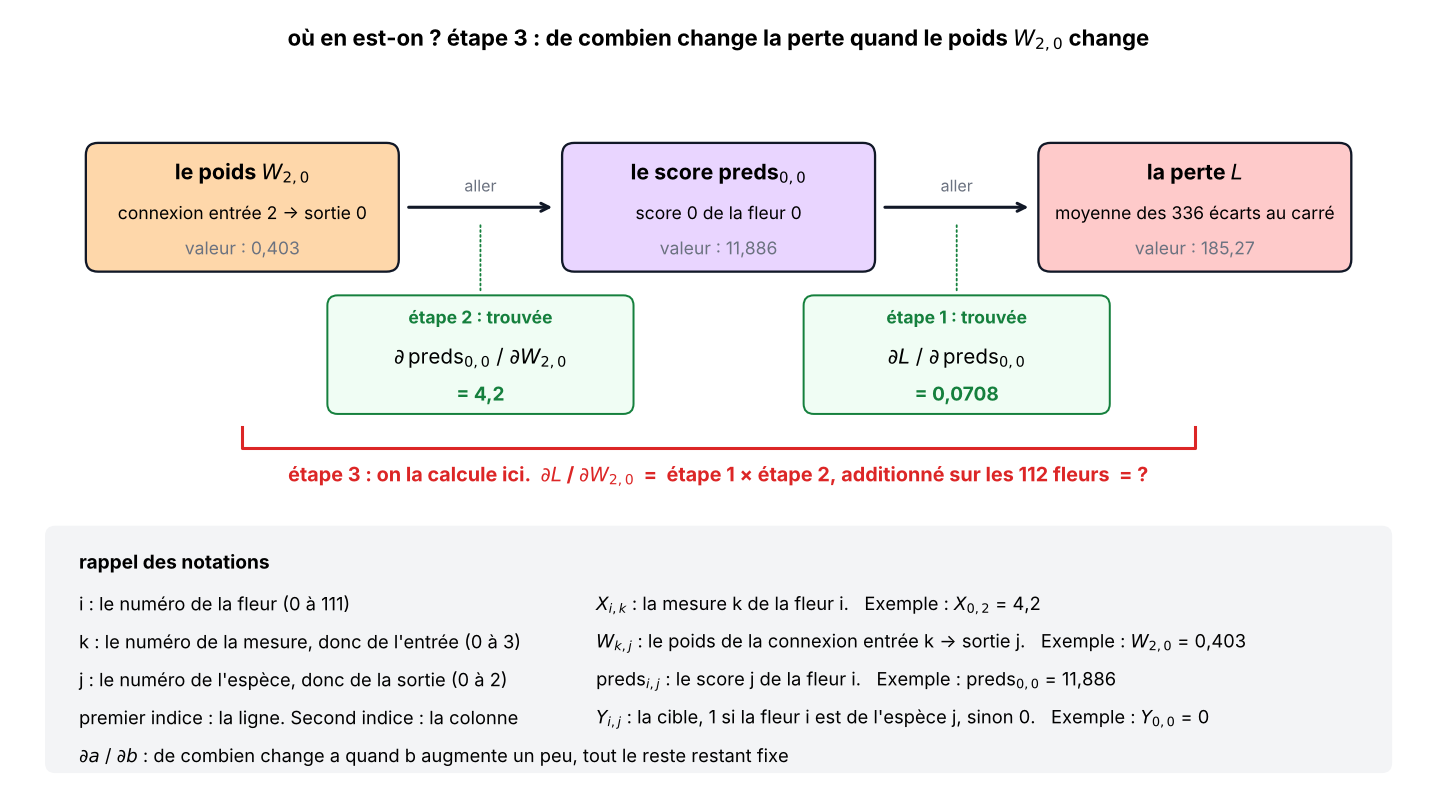

### La perte est une somme de 336 termes, un par prédiction : on note $\ell_{i,j}$ celui de la case (i, j). Sa dérivée est la somme des dérivées de ces termes, et chaque terme se dérive par la règle de la chaîne de la section 1 : étape 1 fois étape 2.

$$\Large \boxed{\;\begin{aligned}
\rule{0pt}{26pt}L &= \sum_{i=0}^{111}\sum_{j=0}^{2} \ell_{i,j} \qquad \ell_{i,j} = \frac{(\text{preds}_{i,j} - Y_{i,j})^2}{336} \\[5pt]
 &{\normalsize\text{la perte : une somme de 336 termes, un par prédiction}} \\[22pt]
\frac{\partial L}{\partial W_{2,0}} &= \sum_{i=0}^{111}\sum_{j=0}^{2} \frac{\partial \ell_{i,j}}{\partial W_{2,0}} \\[5pt]
 &{\normalsize\text{dérivée d'une somme : terme par terme}} \\[22pt]
 &= \sum_{i=0}^{111}\sum_{j=0}^{2} \frac{\partial \ell_{i,j}}{\partial\,\text{preds}_{i,j}} \times \frac{\partial\,\text{preds}_{i,j}}{\partial W_{2,0}} \\[5pt]
 &{\normalsize\text{règle de la chaîne pour chaque terme :}} \\[5pt]
 &{\normalsize\text{le poids change la prédiction, et la prédiction change le terme}} \\[22pt]
 &= \sum_{i=0}^{111}\Big[\frac{\partial L}{\partial\,\text{preds}_{i,0}} \times X_{i,2} \;+\; \frac{\partial L}{\partial\,\text{preds}_{i,1}} \times 0 \;+\; \frac{\partial L}{\partial\,\text{preds}_{i,2}} \times 0\Big] \\[5pt]
 &{\normalsize\text{premier facteur : l'étape 1 (un terme ne dépend que de sa propre prédiction).}} \\[5pt]
 &{\normalsize\text{Second facteur : l'étape 2, non nul seulement pour le score 0}} \\[22pt]
 &= \sum_{i=0}^{111} \frac{2\,(\text{preds}_{i,0} - Y_{i,0})}{336} \times X_{i,2} \\[5pt]
 &{\normalsize\text{il reste un produit par fleur : 112 produits à additionner}} \\[22pt]
 &= \underbrace{0{,}0708 \times 4{,}2}_{\text{fleur 0}} + \underbrace{0{,}0687 \times 4{,}0}_{\text{fleur 1}} + \underbrace{0{,}0807 \times 5{,}5}_{\text{fleur 2}} + \dots = 31{,}47 \\[5pt]
 &{\normalsize\text{avec les nombres : la colonne 0 de grad_preds fois la mesure 2 de chaque fleur}} \rule[-16pt]{0pt}{0pt}
\end{aligned}\;}$$

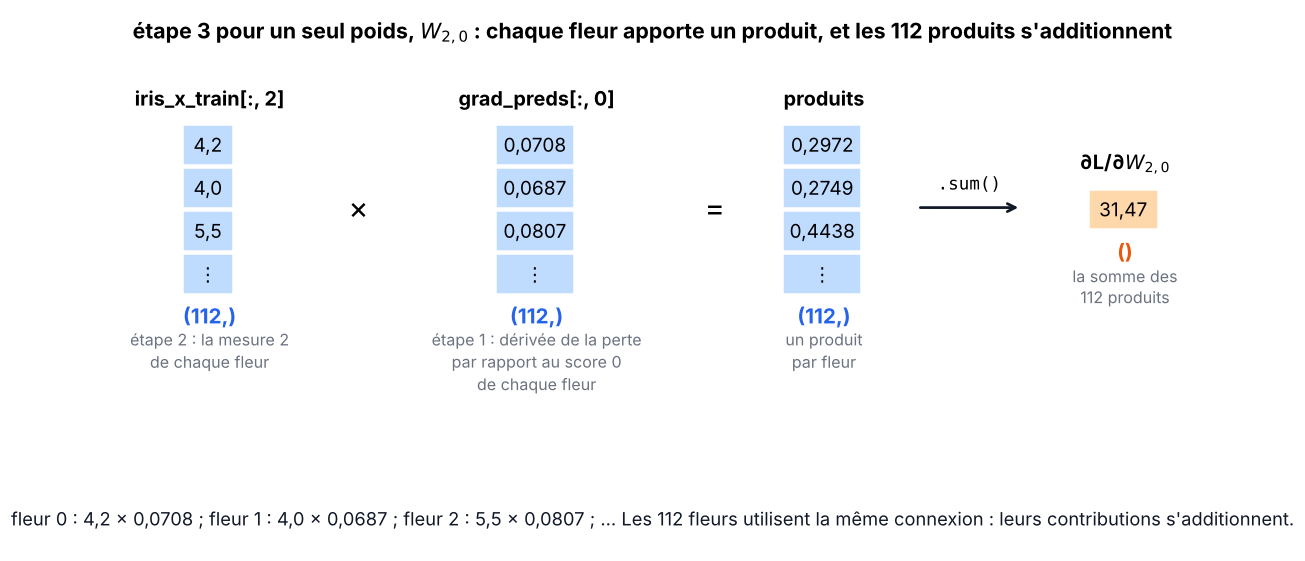

### En code : `iris_x_train[:, 2]` est la colonne 2 des données, la mesure 2 des 112 fleurs ; `grad_preds[:, 0]` est la colonne 0 de `grad_preds`. `*` multiplie élément par élément, `.sum()` additionne les 112 produits.

In [51]:
mesure_2 = iris_x_train[:, 2]                        # étape 2 : la mesure 2 des 112 fleurs
derivee_score_0 = grad_preds[:, 0]                   # étape 1 : une dérivée par fleur, pour le score 0
derivee_W20 = (mesure_2 * derivee_score_0).sum()     # étape 3 : 112 produits, additionnés
print('dérivée de la perte par rapport à W[2, 0], somme sur les 112 fleurs :', round(derivee_W20.item(), 3))

dérivée de la perte par rapport à W[2, 0], somme sur les 112 fleurs : 31.469


<br>

## Étape 3, suite : les 12 poids d'un coup

### Le poids $W_{2,0}$ est fait. Pour les 11 autres, le calcul est le même, avec k et j à la place de 2 et 0.

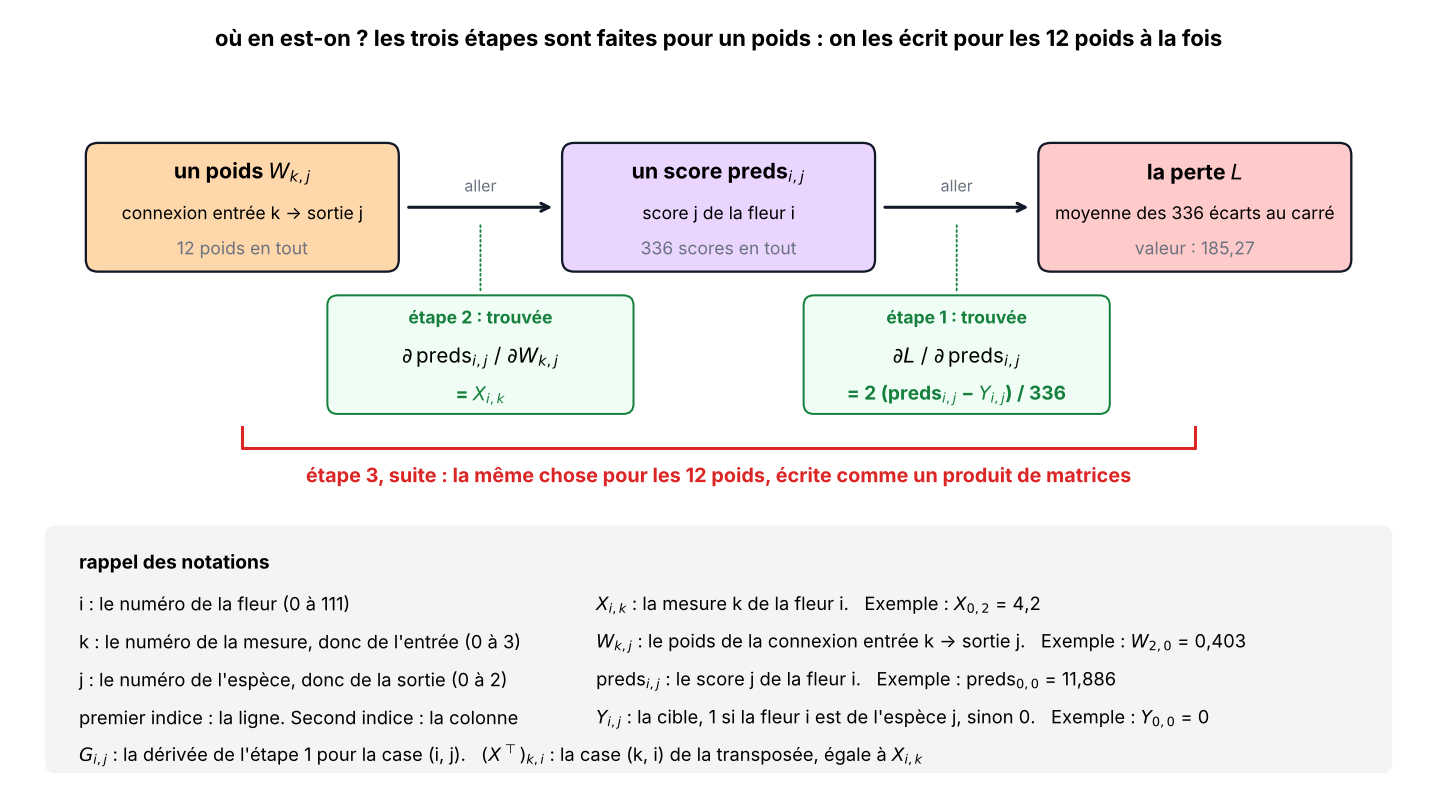

### On note G la matrice de l'étape 1 (`grad_preds` dans le code). La somme sur les fleurs est alors la définition d'un produit de matrices, à condition de transposer X : la transposée échange lignes et colonnes, donc l'ordre des deux indices.

$$\Large \boxed{\;\begin{aligned}
\rule{0pt}{26pt}\frac{\partial L}{\partial W_{k,j}} &= \sum_{i=0}^{111} \frac{\partial L}{\partial\,\text{preds}_{i,j}} \times X_{i,k} \\[5pt]
 &{\normalsize\text{le calcul fait pour le poids (2, 0), écrit pour un poids (k, j) quelconque}} \\[22pt]
 &= \sum_{i=0}^{111} X_{i,k}\,G_{i,j} \qquad G_{i,j} = \frac{2\,(\text{preds}_{i,j} - Y_{i,j})}{336} \\[5pt]
 &{\normalsize\text{on nomme G la matrice de l'étape 1, et on échange les deux facteurs du produit}} \\[22pt]
 &= \sum_{i=0}^{111} (X^\top)_{k,i}\,G_{i,j} \\[5pt]
 &{\normalsize\text{la transposée échange lignes et colonnes :}} \\[5pt]
 &{\normalsize\text{la case (k, i) de la transposée est la case (i, k) de X}} \\[22pt]
 &= (X^\top G)_{k,j} \\[5pt]
 &{\normalsize\text{définition du produit de matrices :}} \\[5pt]
 &{\normalsize\text{la case (k, j) de AB est la somme, sur i, de A(k, i) fois B(i, j)}} \\[22pt]
\nabla_W L &= X^\top G = X^\top\,\frac{2\,(\text{preds} - Y)}{336} \\[5pt]
 &{\normalsize\text{les 12 dérivées, rangées dans une matrice de forme (4, 3)}} \rule[-16pt]{0pt}{0pt}
\end{aligned}\;}$$

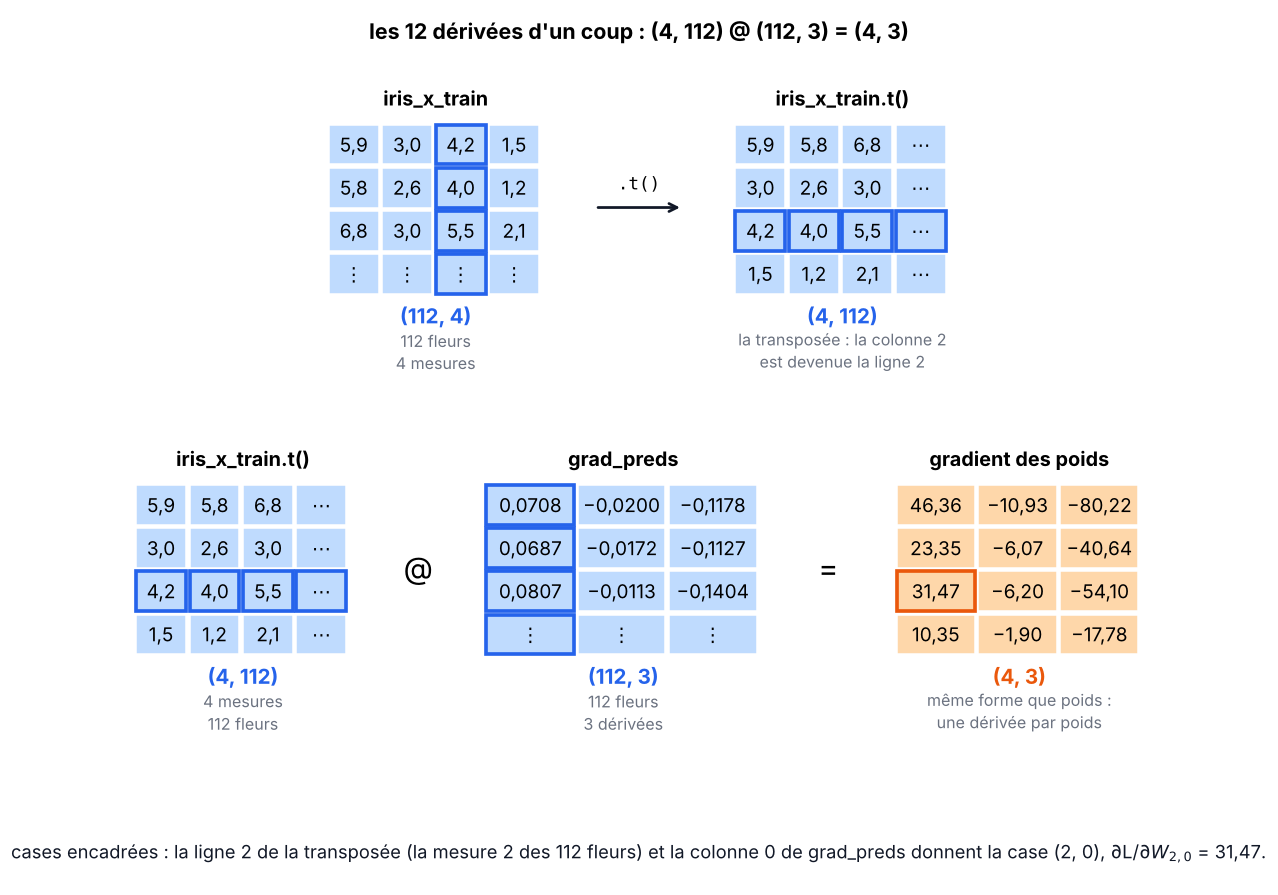

### En code : `.t()` transpose une matrice (lignes et colonnes échangées) : X passe de la forme (112, 4) à (4, 112). `torch.mm` la multiplie par `grad_preds`, de forme (112, 3). Résultat : forme (4, 3), un nombre par poids, donc par connexion du réseau. La case `[2, 0]` doit valoir 31,469.

In [52]:
X_transposee = iris_x_train.t()                         # forme (4, 112)
grad_main = torch.mm(X_transposee, grad_preds)          # les 12 dérivées : (4, 112) fois (112, 3)
print('forme de X transposée :', X_transposee.shape, ' forme de grad_main :', grad_main.shape)
print(f'gradient à la main, un nombre par poids :\n{grad_main.detach()}')
print('sa case [2, 0], calculée plus haut pour W[2, 0] seul :', round(grad_main[2, 0].item(), 3))

forme de X transposée : torch.Size([4, 112])  forme de grad_main : torch.Size([4, 3])
gradient à la main, un nombre par poids :
tensor([[ 46.363, -10.931, -80.218],
        [ 23.353,  -6.065, -40.635],
        [ 31.469,  -6.202, -54.095],
        [ 10.348,  -1.897, -17.783]])
sa case [2, 0], calculée plus haut pour W[2, 0] seul : 31.469


<br>

## Le même gradient, par autograd

### Par autograd : `perte.backward()`, une seule ligne. Le gradient est stocké dans `poids.grad`, de même forme que `poids`.

In [53]:
perte.backward()
print(f'gradient par autograd, un nombre par poids :\n{poids.grad}')
print('forme de poids :', poids.shape, ' forme de poids.grad :', poids.grad.shape)

gradient par autograd, un nombre par poids :
tensor([[ 46.363, -10.931, -80.218],
        [ 23.353,  -6.065, -40.635],
        [ 31.469,  -6.202, -54.095],
        [ 10.348,  -1.897, -17.783]])
forme de poids : torch.Size([4, 3])  forme de poids.grad : torch.Size([4, 3])


### Les deux tableaux sont-ils égaux ? On les soustrait : `.abs()` prend la valeur absolue de chaque écart, `.max()` garde le plus grand.

In [54]:
ecart = (grad_main.detach() - poids.grad).abs().max()
print('plus grand écart entre les deux tableaux :', ecart)

plus grand écart entre les deux tableaux : tensor(0.000)


<br>

## Quand le réseau grossit

### Les deux gradients sont égaux. Pour dessiner un réseau plus gros, on abrège : un bloc représente une couche entière de neurones, une bande toutes les connexions entre deux couches. Voici le réseau d'iris dessiné des deux façons.

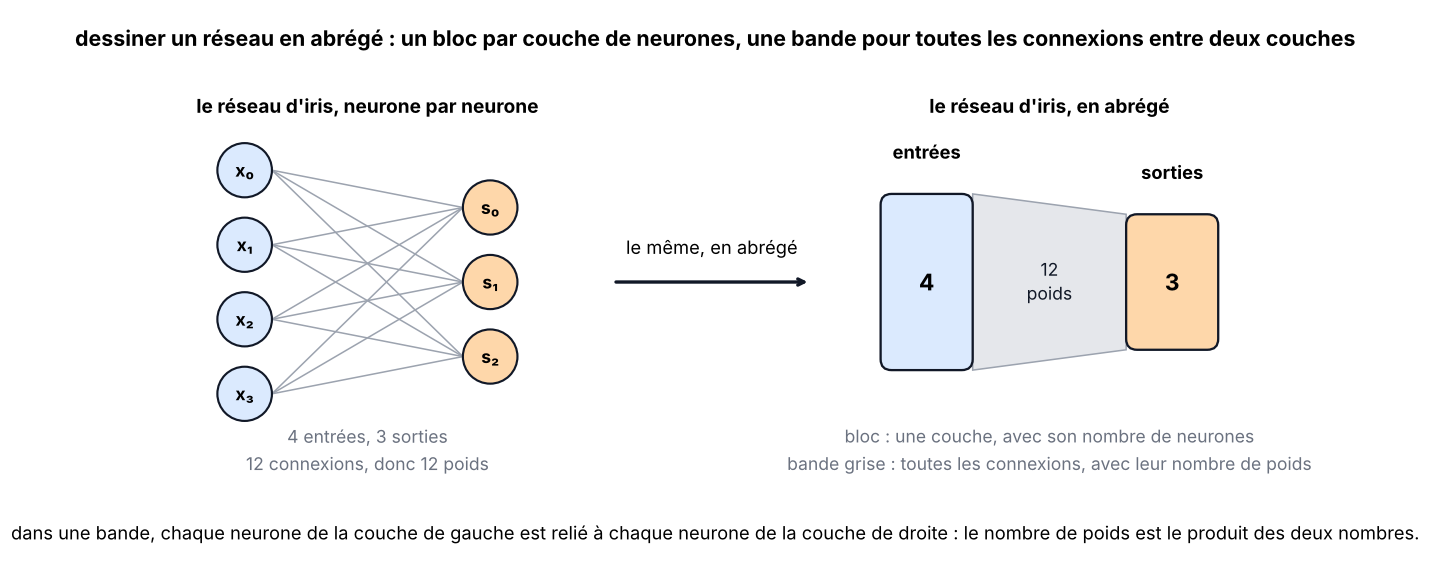

### Avec cette convention, le plus gros réseau de ce labo : 64 entrées, trois couches cachées de 200, 500 et 500 neurones, chacune suivie de ReLU, et 10 sorties. Chaque neurone ajoute aussi un biais à sa somme pondérée : un nombre de plus, appris comme les poids.

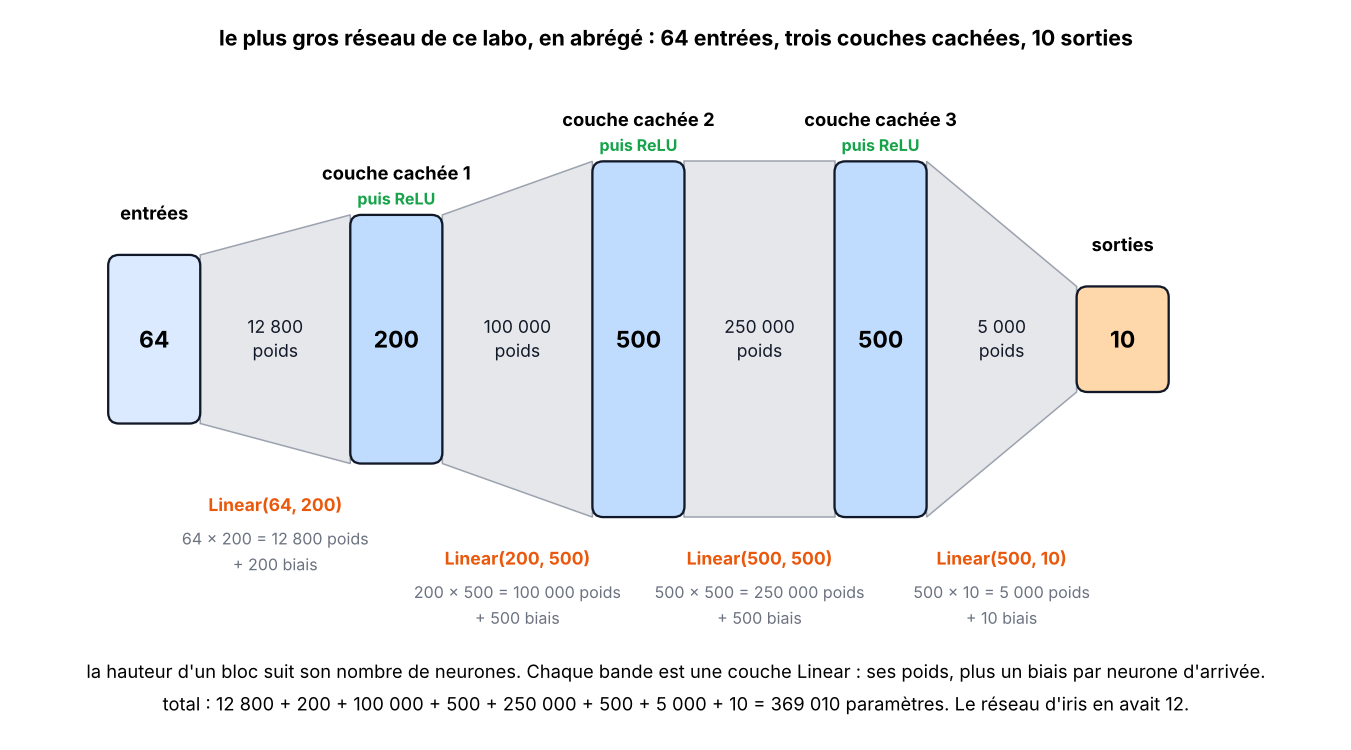

### En code : `torch.nn.Sequential` empile des couches (détails aux sections 6 et 7). `torch.nn.Linear(64, 200)` est une bande du schéma : les poids entre 64 entrées et 200 neurones, plus leurs 200 biais. `torch.nn.ReLU()` est l'activation.

In [55]:
gros = torch.nn.Sequential(
    torch.nn.Linear(64, 200), torch.nn.ReLU(),
    torch.nn.Linear(200, 500), torch.nn.ReLU(),
    torch.nn.Linear(500, 500), torch.nn.ReLU(),
    torch.nn.Linear(500, 10),
)
print(f'le réseau, couche par couche :\n{gros}')

le réseau, couche par couche :
Sequential(
  (0): Linear(in_features=64, out_features=200, bias=True)
  (1): ReLU()
  (2): Linear(in_features=200, out_features=500, bias=True)
  (3): ReLU()
  (4): Linear(in_features=500, out_features=500, bias=True)
  (5): ReLU()
  (6): Linear(in_features=500, out_features=10, bias=True)
)


### `gros.parameters()` donne un à un les tenseurs de paramètres du réseau (poids et biais de chaque couche), et `.numel()` compte les éléments d'un tenseur. Leur somme est le nombre de paramètres : le total de la figure.

In [56]:
nombre = sum(p.numel() for p in gros.parameters())
print('nombre de paramètres du réseau :', nombre)

nombre de paramètres du réseau : 369010


### L'aller : un lot de 100 entrées traverse le réseau. Le nombre de lignes reste 100 ; le nombre de colonnes suit la taille de chaque couche, de 64 jusqu'à 10.

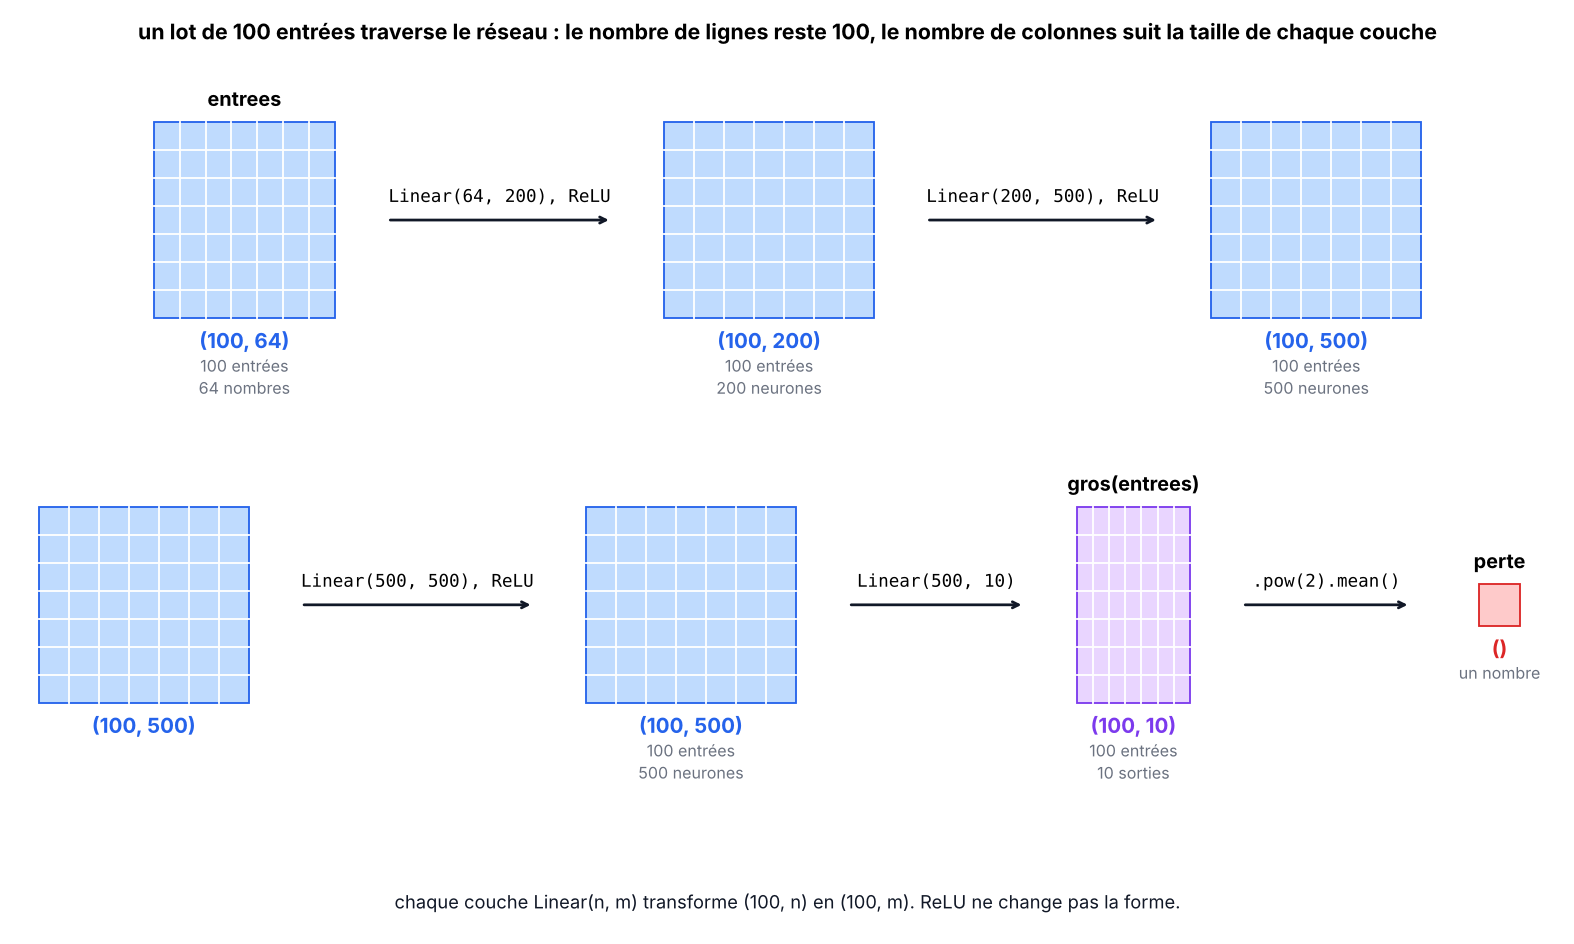

### `torch.randn(100, 64)` crée un lot de 100 entrées aléatoires, et `gros(entrees)` lui applique toutes les couches. La perte, ici la moyenne des carrés des sorties, sert seulement à obtenir un nombre à dériver.

In [57]:
entrees = torch.randn(100, 64)                     # un lot de 100 entrées de 64 nombres
sorties = gros(entrees)                            # l'aller, à travers toutes les couches
perte = sorties.pow(2).mean()
print('forme des entrées :', entrees.shape, ' forme des sorties :', sorties.shape)
print('perte sur ces 100 entrées :', perte)

forme des entrées : torch.Size([100, 64])  forme des sorties : torch.Size([100, 10])
perte sur ces 100 entrées : tensor(0.002, grad_fn=<MeanBackward0>)


### Le retour : `perte.backward()` parcourt le graphe de calcul, de la perte vers les entrées, et calcule un gradient par paramètre, soit 369 010 gradients.

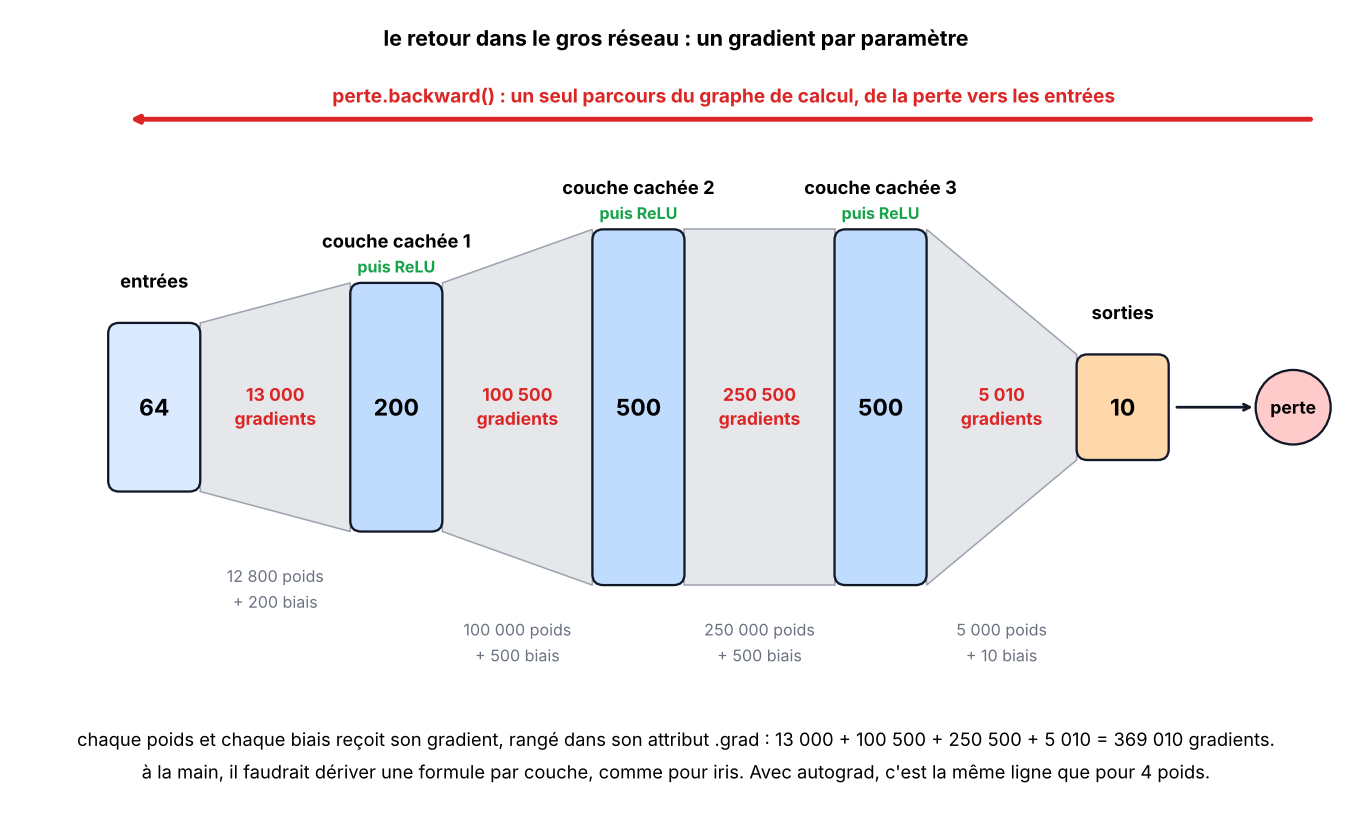

### `time.perf_counter()` lit l'horloge, en secondes : la différence entre deux lectures donne la durée de `perte.backward()`, la même ligne que pour 4 poids.

In [58]:
debut = time.perf_counter()
perte.backward()                                   # 369 010 gradients d'un coup
print('temps pour calculer les 369 010 gradients :', round(time.perf_counter() - debut, 4), 'seconde')

temps pour calculer les 369 010 gradients : 0.0123 seconde


# 5. La descente de gradient, écrite à la main

### `backward()` a pris quelques millièmes de seconde. On revient à iris pour utiliser les gradients : à chaque époque, on soustrait aux poids leur gradient multiplié par le pas (taux d'apprentissage), un hyperparamètre. La cellule recrée les mêmes poids, fixe le pas et prépare une liste vide pour noter les pertes.

$$\Large \boxed{\;W \leftarrow W - \text{pas} \times \nabla_W L\;}$$

In [59]:
torch.manual_seed(0)
poids = torch.randn(4, 3, requires_grad=True)    # les mêmes poids de départ
pas = 2e-4                                       # 2e-4 s'écrit aussi 0.0002
pertes_main = []                                 # pour noter la perte à chaque époque

### La boucle : 500 époques (une époque = un passage sur toutes les données). Chaque tour refait l'aller, note la perte dans la liste (`.append`), appelle `backward()`, met à jour (`poids -= pas * poids.grad`) et remet le gradient à zéro. Le bloc `with torch.no_grad():` désactive l'enregistrement des opérations : la mise à jour ne doit pas entrer dans le graphe de calcul.

In [60]:
for epoque in range(500):
    preds = torch.mm(iris_x_train, poids)              # 1. prédire
    perte = (preds - iris_y_train).pow(2).mean()       # 2. mesurer l'erreur
    pertes_main.append(perte.item())                   #    (on note la perte)
    perte.backward()                                   # 4. calculer les gradients
    with torch.no_grad():                              #    opérations non enregistrées dans le graphe
        poids -= pas * poids.grad                      # 5. mettre à jour les poids
        poids.grad.zero_()                             # 3. remettre le gradient à zéro pour l'itération suivante

### La perte avant d'apprendre, puis après 500 époques : `[0]` est le premier élément de la liste, `[-1]` le dernier.

In [61]:
print("perte avant d'apprendre :", round(pertes_main[0], 2))
print('perte après 500 époques :', round(pertes_main[-1], 2))

perte avant d'apprendre : 185.27
perte après 500 époques : 1.06


### 🔮 De 185 à 1,06 : le modèle apprend. Mais ce pas de 0,0002 est-il bien choisi ? Et que se passera-t-il avec un pas de 0,1 ?

In [62]:
#@title Démo B : la perte au fil des époques, selon le pas (curseur) { display-mode: "form" }
demo_taux()

### Pas trop petit : la perte n'a pas convergé après 500 époques. Pas trop grand : chaque mise à jour dépasse le minimum, la perte diverge.

# 6. `optim` et `nn` : la même boucle, sans rien écrire soi-même

### Un optimiseur (`torch.optim`) applique la règle de mise à jour. Dans `torch.optim.SGD([poids], lr=2e-4)` : `SGD` est la descente de gradient, `[poids]` la liste des paramètres à modifier, `lr` (learning rate) le pas. La liste `pertes_optim` notera les pertes.

In [63]:
torch.manual_seed(0)
poids = torch.randn(4, 3, requires_grad=True)          # les mêmes poids de départ, encore
optimiseur = torch.optim.SGD([poids], lr=2e-4)         # SGD : la descente de gradient ; lr : le pas
pertes_optim = []

### `optimiseur.step()` remplace `poids -= pas * poids.grad`, et `optimiseur.zero_grad()` remplace `poids.grad.zero_()`. Le reste de la boucle est inchangé.

In [64]:
for epoque in range(500):
    preds = torch.mm(iris_x_train, poids)              # 1. prédire
    perte = (preds - iris_y_train).pow(2).mean()       # 2. mesurer l'erreur
    pertes_optim.append(perte.item())
    optimiseur.zero_grad()                             # 3. remettre les gradients à zéro
    perte.backward()                                   # 4. calculer les gradients
    optimiseur.step()                                  # 5. mettre à jour les poids

### Le résultat est-il le même qu'à la main ?

In [65]:
print('perte finale, boucle écrite à la main (section 5) :', round(pertes_main[-1], 4))
print("perte finale, boucle avec l'optimiseur            :", round(pertes_optim[-1], 4))

perte finale, boucle écrite à la main (section 5) : 1.0591
perte finale, boucle avec l'optimiseur            : 1.0591


<br>

## `nn.Linear` : une couche qui possède ses paramètres

### Les deux pertes sont identiques. `torch.nn.Linear(4, 3)` est une couche linéaire : le réseau d'iris, 4 entrées reliées à 3 sorties, avec en plus un biais ajouté à chaque sortie. Elle crée elle-même ses paramètres, déjà en `requires_grad=True`.

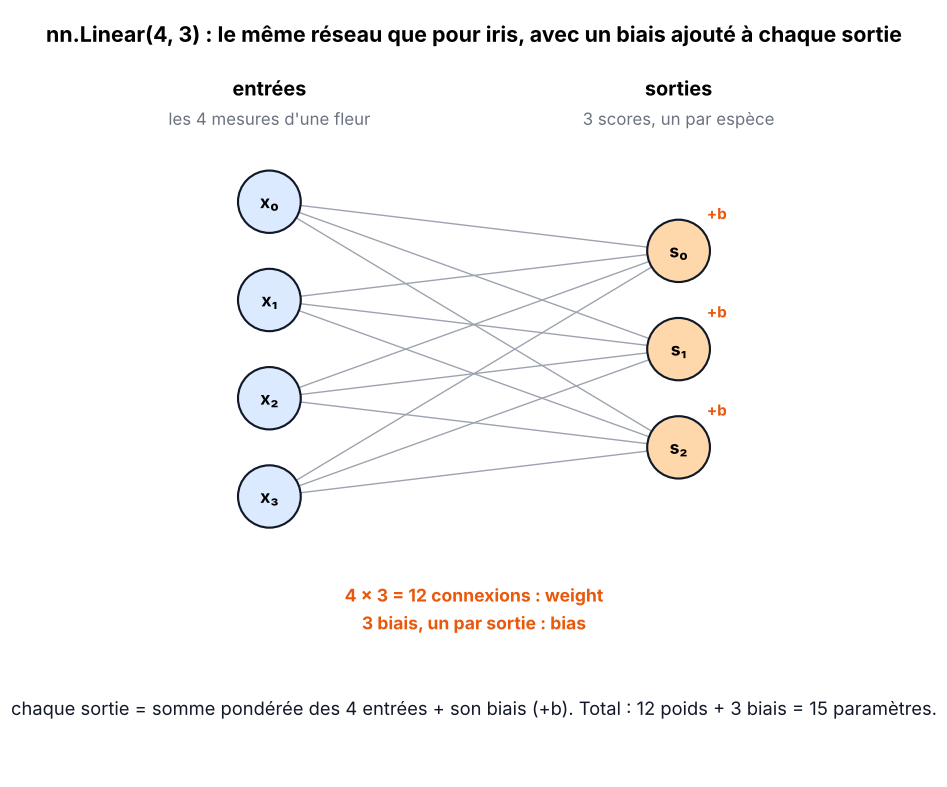

### `modele.named_parameters()` donne le nom et le tenseur de chaque paramètre : `weight`, les 12 poids des connexions, et `bias`, les 3 biais. La couche calcule x·Wᵀ + b.

In [66]:
torch.manual_seed(0)
modele = torch.nn.Linear(4, 3)                   # remplace notre matrice poids
for nom, p in modele.named_parameters():
    print('paramètre', nom, ': forme', p.shape)

paramètre weight : forme torch.Size([3, 4])
paramètre bias : forme torch.Size([3])


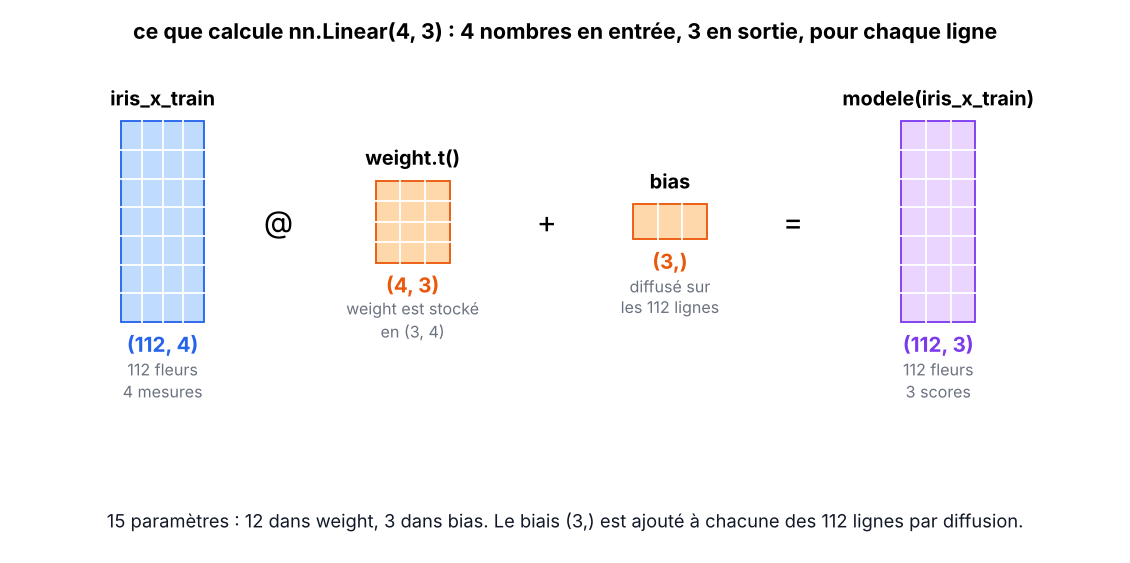

### `modele(iris_x_train)` applique la couche aux 112 fleurs. Vérification à la main : `modele.weight`, de forme (3, 4), est transposé par `.t()` et multiplié par les données avec `@` ; puis on ajoute `modele.bias`, de forme (3,) : par diffusion, il est ajouté à chacune des 112 lignes. On affiche le plus grand écart.

In [67]:
sortie = modele(iris_x_train)
produit = iris_x_train @ modele.weight.t()       # forme (112, 3)
a_la_main = produit + modele.bias                # (112, 3) + (3,) : le biais est diffusé sur les 112 lignes
print('forme du produit :', produit.shape, ' forme du biais :', modele.bias.shape, ' forme de la somme :', a_la_main.shape)
print('plus grand écart entre modele(x) et le calcul à la main :', (sortie - a_la_main).abs().max().item())

forme du produit : torch.Size([112, 3])  forme du biais : torch.Size([3])  forme de la somme : torch.Size([112, 3])
plus grand écart entre modele(x) et le calcul à la main : 0.0


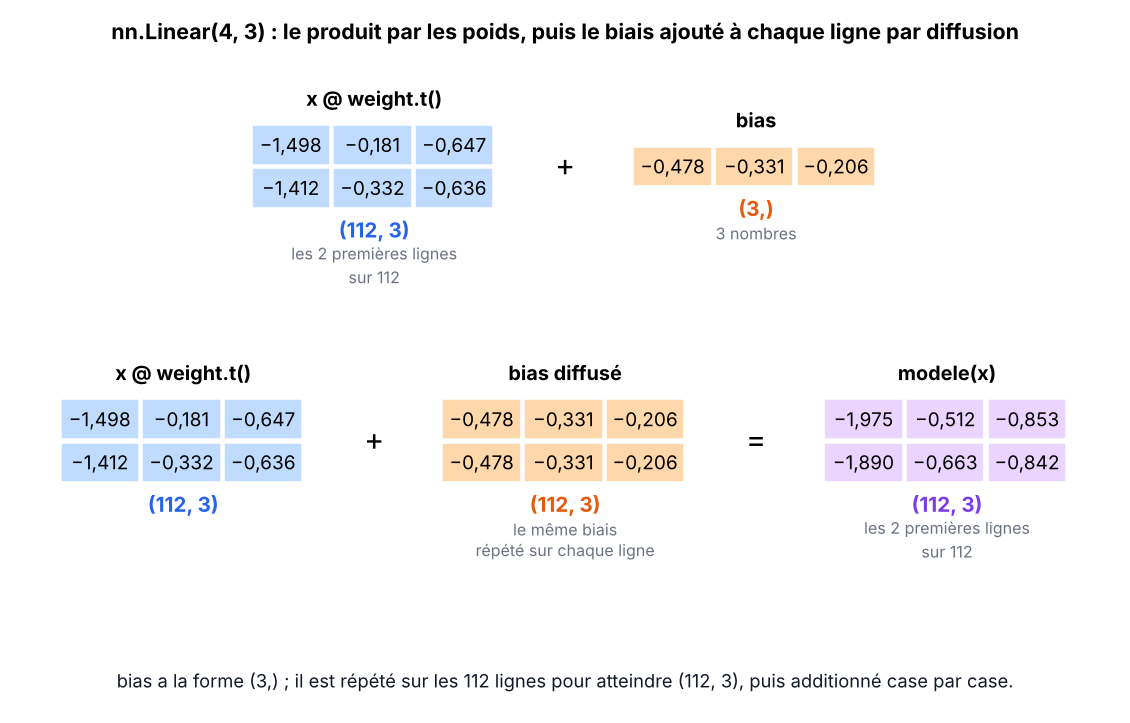

### 12 poids et 3 biais : 15 paramètres. `torch.nn.MSELoss()` crée une fonction de perte, la moyenne des écarts au carré : elle remplace notre calcul. `modele.parameters()` donne tous les paramètres à l'optimiseur. La liste `pertes` notera les pertes.

In [68]:
perte_fn = torch.nn.MSELoss()                                    # remplace (preds - y).pow(2).mean()
optimiseur = torch.optim.SGD(modele.parameters(), lr=2e-4)       # remplace la liste [poids]
pertes = []

### La boucle définitive, les cinq lignes de la figure du début : `modele(iris_x_train)` calcule les prédictions, `perte_fn(preds, iris_y_train)` la perte.

In [69]:
for epoque in range(500):
    preds = modele(iris_x_train)                 # 1. prédire
    perte = perte_fn(preds, iris_y_train)        # 2. mesurer l'erreur
    pertes.append(perte.item())
    optimiseur.zero_grad()                       # 3. remettre les gradients à zéro
    perte.backward()                             # 4. calculer les gradients
    optimiseur.step()                            # 5. mettre à jour les paramètres

### La perte au fil des époques : `plt.plot` (matplotlib) trace la liste, `plt.xlabel` et `plt.ylabel` nomment les axes, `plt.show()` affiche la figure.

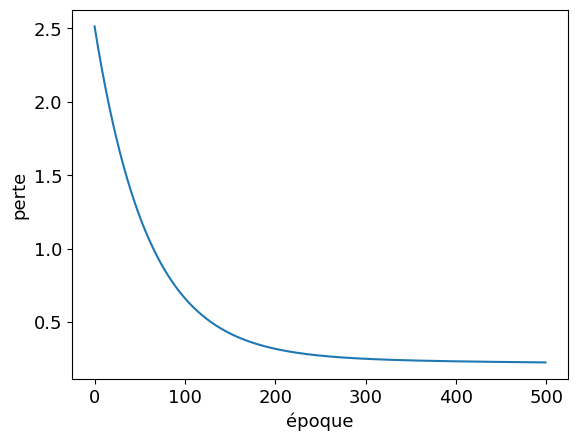

perte au départ : 2.512  perte à la fin : 0.225


In [70]:
plt.plot(pertes)
plt.xlabel('époque')
plt.ylabel('perte')
plt.show()
print('perte au départ :', round(pertes[0], 3), ' perte à la fin :', round(pertes[-1], 3))

# 7. Empiler des couches, et pourquoi il faut une non-linéarité

### Un réseau, ce sont des couches à la suite, avec une fonction d'activation entre elles. Ici ReLU, déjà utilisée dans le rappel : elle remplace les valeurs négatives par 0, élément par élément, avec `torch.relu`.

$$\Large \boxed{\;\text{ReLU}(z) = \max(0,\, z)\;}$$

In [71]:
z = torch.tensor([-2.0, -1.0, 0.0, 1.0, 2.0])
print('avant ReLU :', z)
print('après ReLU :', torch.relu(z))

avant ReLU : tensor([-2., -1.,  0.,  1.,  2.])
après ReLU : tensor([0., 0., 0., 1., 2.])


### Le réseau pour le XOR : 2 entrées, une couche cachée de 8 neurones suivis de ReLU, 1 sortie. Chaque neurone d'une couche est relié à tous ceux de la suivante et possède un biais.

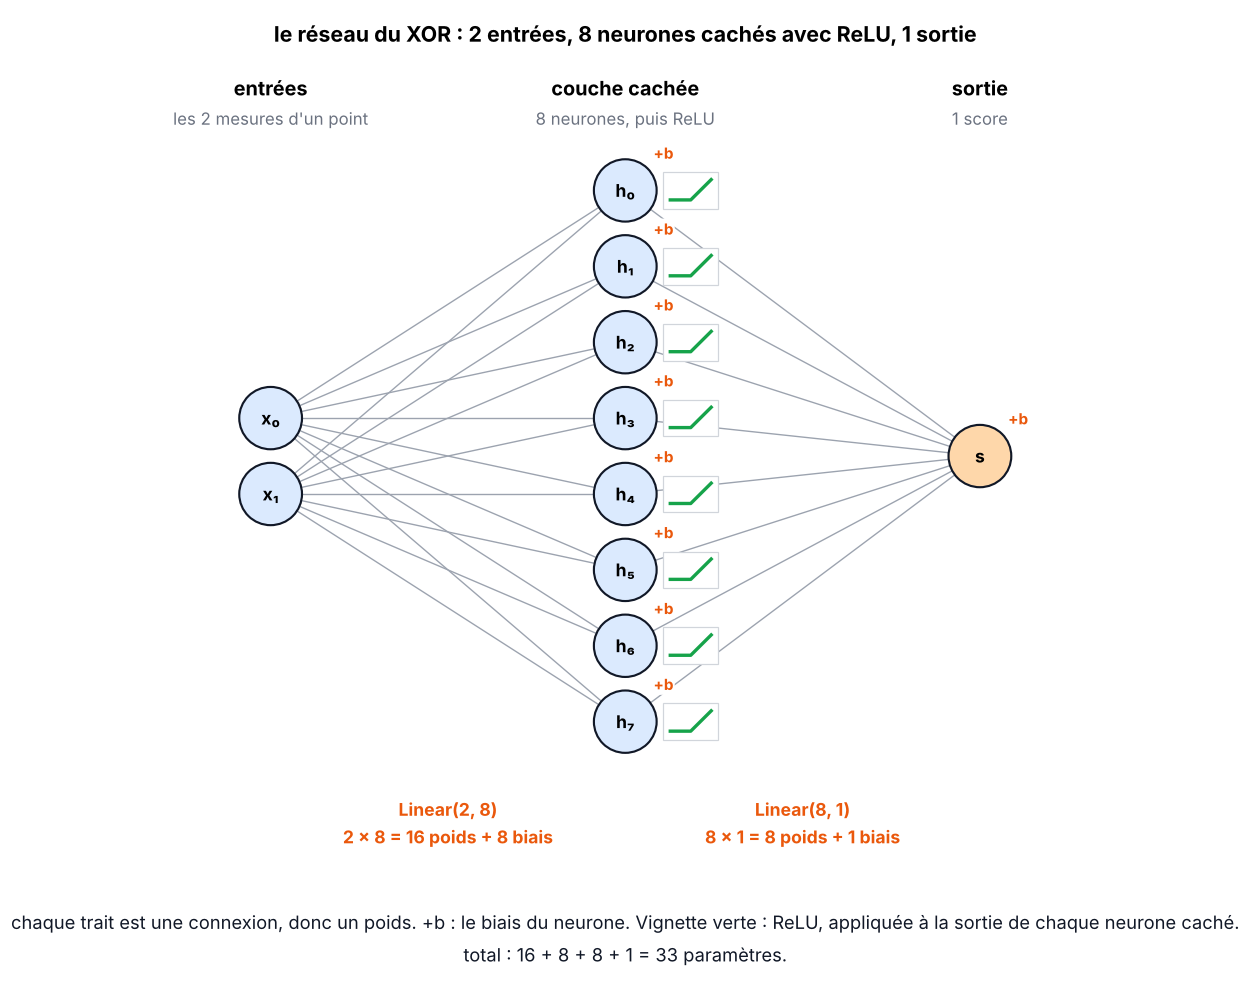

### `torch.nn.Sequential` empile les couches dans l'ordre : `Linear(2, 8)`, 2 mesures en entrée et 8 neurones cachés ; `torch.nn.ReLU()`, la fonction `torch.relu` sous forme de couche ; `Linear(8, 1)`, 1 score en sortie.

In [72]:
torch.manual_seed(0)
modele = torch.nn.Sequential(
    torch.nn.Linear(2, 8),       # couche cachée : 2 mesures en entrée, 8 neurones
    torch.nn.ReLU(),             # la non-linéarité, appliquée à chacun des 8 neurones
    torch.nn.Linear(8, 1),       # couche de sortie : 8 neurones en entrée, 1 score
)
print(f'le réseau, couche par couche :\n{modele}')

le réseau, couche par couche :
Sequential(
  (0): Linear(in_features=2, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=1, bias=True)
)


<br>

## Un réseau à deux couches sur le XOR

### Le XOR du cours : 240 points, 2 mesures, classe 0 ou 1, renvoyés par `charger_xor()` (boîte à outils). `plt.scatter` place un point par ligne : colonne 0 en abscisse, colonne 1 en ordonnée, couleur selon la classe (`.flatten()` met `y_xor` à plat, de (240, 1) à (240,) ; `cmap` choisit la palette). Aucune droite ne sépare les deux couleurs.

forme de x_xor : torch.Size([240, 2])  forme de y_xor : torch.Size([240, 1])


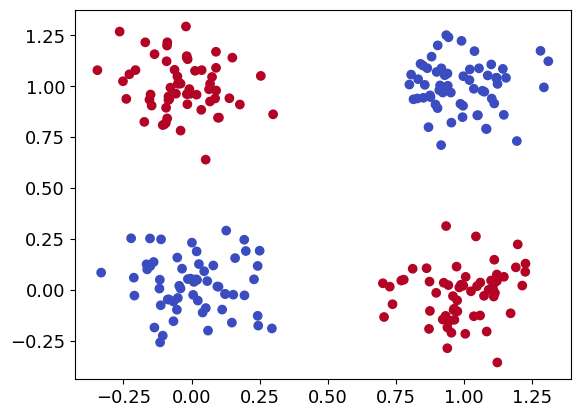

In [73]:
x_xor, y_xor = charger_xor()
print('forme de x_xor :', x_xor.shape, ' forme de y_xor :', y_xor.shape)
plt.scatter(x_xor[:, 0], x_xor[:, 1], c=y_xor.flatten(), cmap='coolwarm')
plt.show()

### Pour voir les données traverser le réseau : `for couche in modele` parcourt les couches du `Sequential`, `couche(etape)` applique chacune au résultat de la précédente, et on affiche la forme obtenue.

In [74]:
etape = x_xor
print('entrée :', etape.shape)
for couche in modele:
    etape = couche(etape)                        # on applique une couche au résultat de la précédente
    print('après', couche, ':', etape.shape)

entrée : torch.Size([240, 2])
après Linear(in_features=2, out_features=8, bias=True) : torch.Size([240, 8])
après ReLU() : torch.Size([240, 8])
après Linear(in_features=8, out_features=1, bias=True) : torch.Size([240, 1])


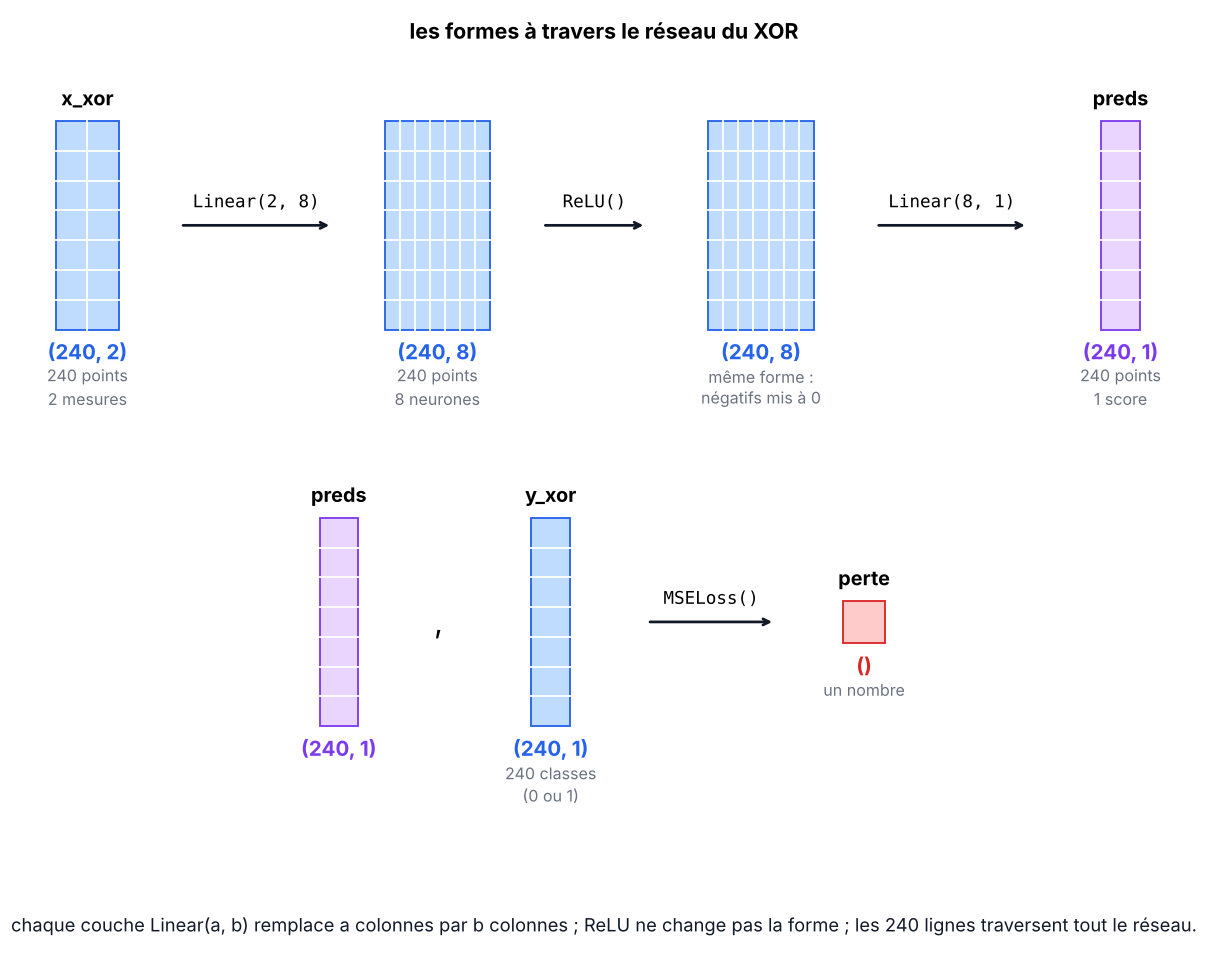

### La perte : `MSELoss`, comme pour iris. L'optimiseur : `torch.optim.Adam` au lieu de `SGD`, une variante de la descente de gradient qui adapte le pas de chaque paramètre à l'historique de ses gradients. Changer d'optimiseur, c'est changer une ligne ; ici le pas `lr` vaut 0,02.

In [75]:
perte_fn = torch.nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.02)

### Toujours la même boucle de cinq lignes. À la fin, `perte.item()` donne la dernière perte en nombre Python.

In [76]:
for epoque in range(300):
    preds = modele(x_xor)                        # 1. prédire
    perte = perte_fn(preds, y_xor)               # 2. mesurer l'erreur
    optimiseur.zero_grad()                       # 3. remettre les gradients à zéro
    perte.backward()                             # 4. calculer les gradients
    optimiseur.step()                            # 5. mettre à jour les paramètres
print('perte après 300 époques :', round(perte.item(), 3))

perte après 300 époques : 0.025


### `> 0.5` compare chaque score à 0,5 et `.float()` convertit Vrai ou Faux en 1.0 ou 0.0 : la classe prédite. `classes == y_xor` vaut Vrai pour chaque bonne réponse ; la moyenne de ces 1 et 0 est la proportion de bonnes réponses. `torch.no_grad()` : inutile d'enregistrer le graphe pour mesurer.

In [77]:
with torch.no_grad():                            # pas besoin de gradients pour mesurer
    classes = (modele(x_xor) > 0.5).float()      # score > 0,5 : classe 1, sinon classe 0
print('proportion de bonnes réponses :', round((classes == y_xor).float().mean().item(), 3))

proportion de bonnes réponses : 0.992


### ✏️ Mettez un `#` devant la ligne `torch.nn.ReLU(),` plus haut, puis réexécutez les cellules jusqu'ici : que devient la proportion ? Retirez ensuite le `#`.

<br>

## Pourquoi l'activation est indispensable

### Sans activation, deux couches linéaires n'en font qu'une : le produit de deux matrices est une matrice.

$$\Large \boxed{\;W_2\,(W_1\,x) = (W_2 W_1)\,x\;}$$

### 🔮 Dans la démo, sans activation : quelle forme aura la frontière, même avec 3 couches de 32 neurones ?

In [78]:
#@title Démo C : un réseau, sa frontière, et le rôle de l'activation (menus et curseurs) { display-mode: "form" }
demo_frontiere()

### Sans activation, la frontière de décision reste une droite, quel que soit le nombre de paramètres. Avec ReLU, elle devient linéaire par morceaux : chaque neurone caché peut y ajouter un changement de direction.

# 8. Reconnaître des chiffres manuscrits

### 1797 images de 8 × 8 pixels, donc 64 nombres par image ; 10 classes, les chiffres 0 à 9. 1347 images pour apprendre, 450 pour tester.

In [79]:
print('entraînement :', digits_x_train.shape, ' test :', digits_x_test.shape, " (nombre d'images, pixels par image)")

entraînement : torch.Size([1347, 64])  test : torch.Size([450, 64])  (nombre d'images, pixels par image)


### `digits_x_train[0]` est la première image, 64 nombres en ligne : `.view(8, 8)` la remet en carré et `plt.imshow` l'affiche, en niveaux de gris (`cmap='Greys'`). `digits_c_train[0]` est son étiquette.

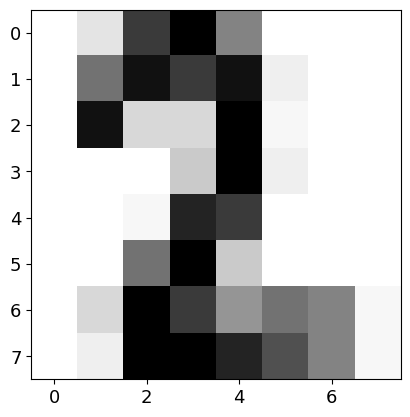

étiquette de cette image : 2


In [80]:
image = digits_x_train[0].view(8, 8)             # la première image, remise en carré 8 x 8
plt.imshow(image, cmap='Greys')
plt.show()
print('étiquette de cette image :', digits_c_train[0].item())

<br>

## L'entropie croisée

### Le réseau donnera 10 scores par image. Nouvelle perte, l'entropie croisée, en deux temps. D'abord softmax : les scores deviennent des probabilités, de somme 1. `torch.softmax(scores, dim=1)` l'applique le long de la dimension 1, celle des classes ; `scores` a la forme (1, 3).

$$\Large \boxed{\;p_j = \frac{e^{\,s_j}}{\sum_k e^{\,s_k}}\;}$$

In [81]:
scores = torch.tensor([[1.0, 1.0, 0.0]])         # 1 image, 3 scores
probas = torch.softmax(scores, dim=1)
print('probabilités des 3 classes (somme 1) :', probas)

probabilités des 3 classes (somme 1) : tensor([[0.422, 0.422, 0.155]])


### Ensuite : moins le logarithme de la probabilité attribuée à la bonne classe (ici la première). La perte vaut 0 si cette probabilité vaut 1, et croît sans limite quand elle tend vers 0. `probas[0, 0]` : ligne 0, colonne 0 ; `torch.log` : le logarithme.

$$\Large \boxed{\;L = -\log\, p_{\text{bonne classe}}\;}$$

In [82]:
print('perte à la main, -log(probabilité de la bonne classe) :', -torch.log(probas[0, 0]))

perte à la main, -log(probabilité de la bonne classe) : tensor(0.862)


### `torch.nn.CrossEntropyLoss()` crée une fonction de perte qui fait les deux temps d'un coup : on lui donne les scores bruts et un tenseur contenant le numéro de la bonne classe.

In [83]:
bonne = torch.tensor([0])                        # le numéro de la bonne classe
perte_fn = torch.nn.CrossEntropyLoss()
print('perte par nn.CrossEntropyLoss, le même nombre         :', perte_fn(scores, bonne))

perte par nn.CrossEntropyLoss, le même nombre         : tensor(0.862)


### 🔮 Le même nombre, 0,862. Avec le curseur : si le score de la bonne classe monte à 6, que devient la perte ?

In [84]:
#@title Démo D : des scores aux probabilités, puis à la perte (curseur) { display-mode: "form" }
demo_softmax()

<br>

## Entraîner un réseau sur les chiffres

### Un réseau pour les chiffres, de même structure que celui du XOR : 64 entrées (les pixels d'une image), 32 neurones cachés avec ReLU, 10 sorties (un score par chiffre).

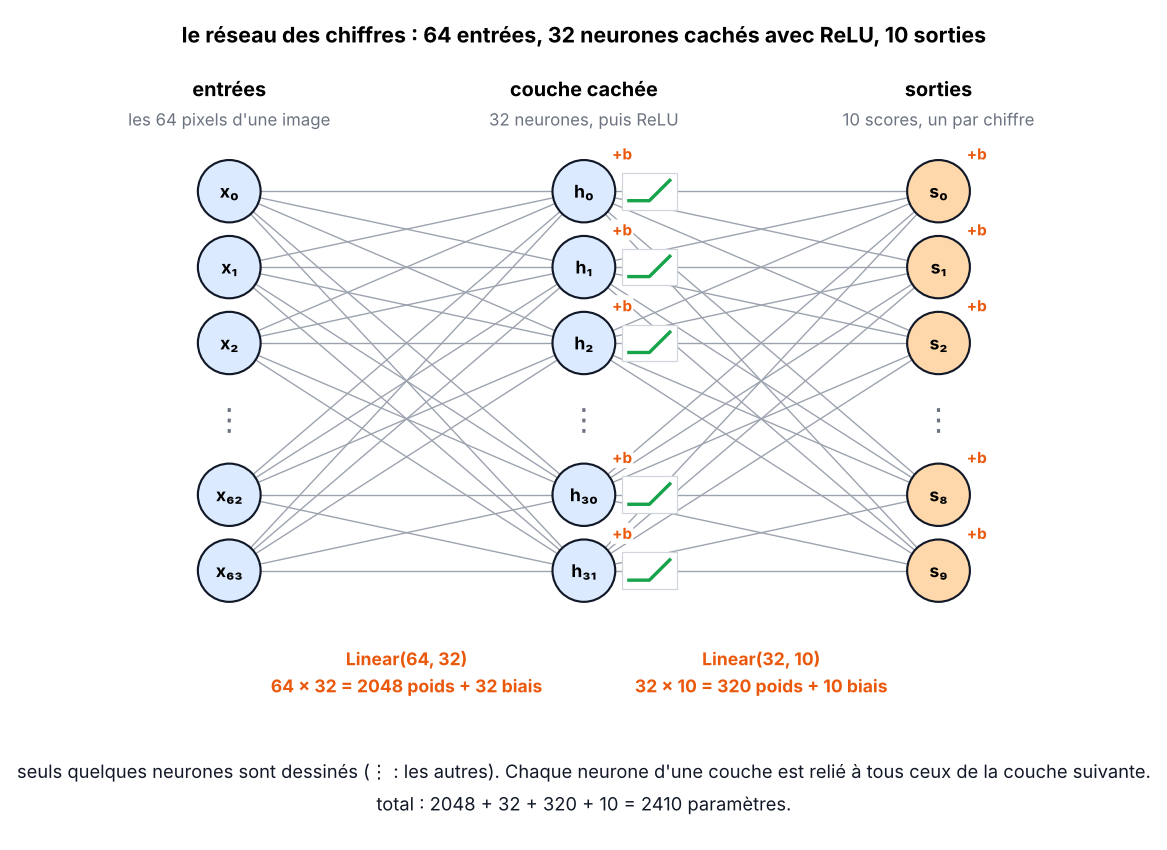

### En code : `Sequential`, `Linear` et `ReLU`, comme pour le XOR.

In [85]:
torch.manual_seed(0)
reseau = torch.nn.Sequential(
    torch.nn.Linear(64, 32),     # 64 pixels en entrée, 32 neurones cachés
    torch.nn.ReLU(),
    torch.nn.Linear(32, 10),     # 10 scores en sortie, un par chiffre
)

### Les formes, couche par couche, pour les 1347 images d'entraînement : la même boucle `for couche in reseau` que pour le XOR.

In [86]:
etape = digits_x_train
print('entrée :', etape.shape)
for couche in reseau:
    etape = couche(etape)
    print('après', couche, ':', etape.shape)

entrée : torch.Size([1347, 64])
après Linear(in_features=64, out_features=32, bias=True) : torch.Size([1347, 32])
après ReLU() : torch.Size([1347, 32])
après Linear(in_features=32, out_features=10, bias=True) : torch.Size([1347, 10])


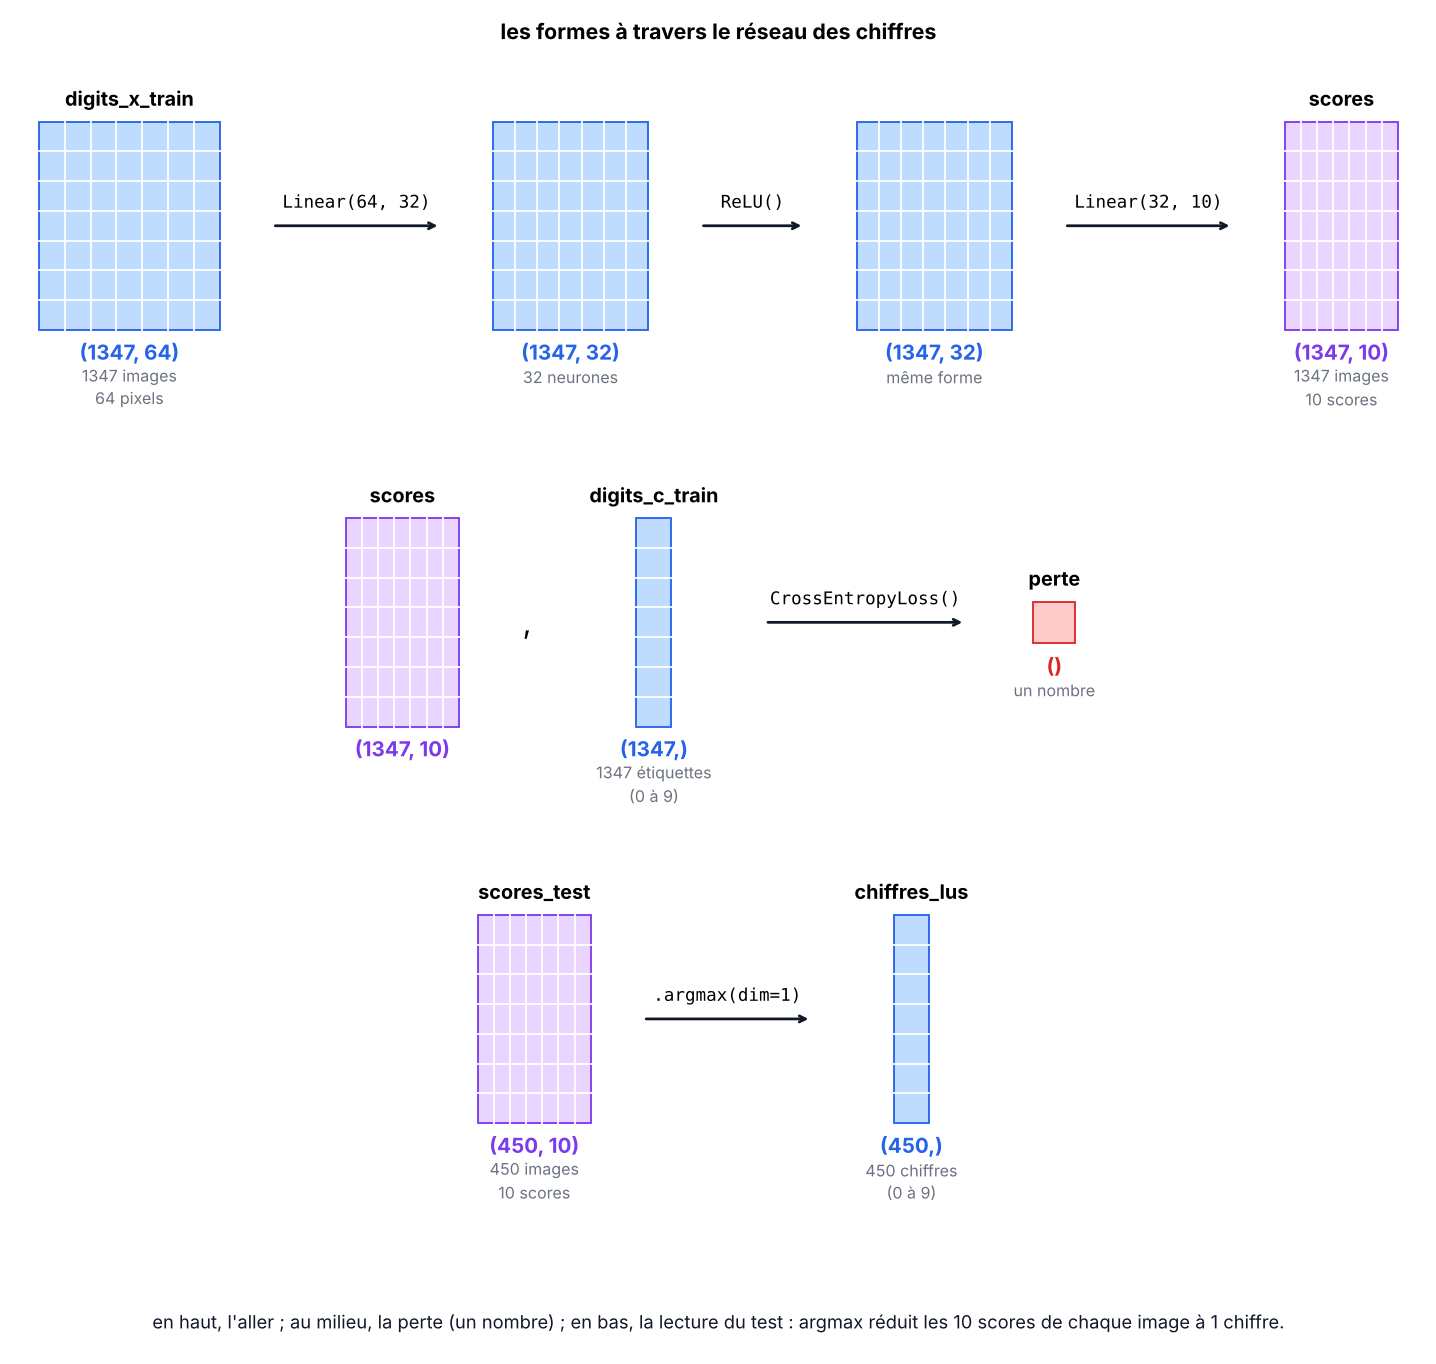

### La perte : `CrossEntropyLoss`. L'optimiseur : `SGD` sur `reseau.parameters()`, avec un pas `lr` de 0,01.

In [87]:
perte_fn = torch.nn.CrossEntropyLoss()
optimiseur = torch.optim.SGD(reseau.parameters(), lr=0.01)

### La boucle, 300 époques : les mêmes cinq lignes.

In [88]:
for epoque in range(300):
    scores = reseau(digits_x_train)              # 1. prédire : 1347 images, 10 scores chacune
    perte = perte_fn(scores, digits_c_train)     # 2. mesurer l'erreur
    optimiseur.zero_grad()                       # 3. remettre les gradients à zéro
    perte.backward()                             # 4. calculer les gradients
    optimiseur.step()                            # 5. mettre à jour les paramètres
print('perte après 300 époques :', round(perte.item(), 3))

perte après 300 époques : 0.146


### Sur les 450 images de test, sans enregistrer le graphe (`torch.no_grad()`). `.argmax(dim=1)` donne, pour chaque ligne, le numéro de la colonne du plus grand score : c'est le chiffre lu. `[:10]` sélectionne les 10 premiers.

In [89]:
with torch.no_grad():                            # pas besoin de gradients pour mesurer
    scores_test = reseau(digits_x_test)          # 450 images, 10 scores chacune
chiffres_lus = scores_test.argmax(dim=1)         # le numéro du plus grand score
print('10 premiers chiffres lus   :', chiffres_lus[:10])
print('10 premiers vrais chiffres :', digits_c_test[:10])

10 premiers chiffres lus   : tensor([2, 8, 2, 6, 6, 7, 1, 9, 8, 5])
10 premiers vrais chiffres : tensor([2, 8, 2, 6, 6, 7, 1, 9, 8, 5])


### La proportion de bonnes réponses sur le test, comme pour le XOR : `==` compare, `.float()` convertit en 1 ou 0, `.mean()` fait la moyenne.

In [90]:
print('proportion de bonnes réponses sur le test :', round((chiffres_lus == digits_c_test).float().mean().item(), 3))

proportion de bonnes réponses sur le test : 0.958


### ✏️ Changez `32` pour `2` aux deux endroits du réseau et réexécutez : que devient la proportion ? Remettez `32`.

<br>

## Le réseau de la démo officielle

### Ci-dessous, le réseau de la démo officielle : 150 fois plus de paramètres.

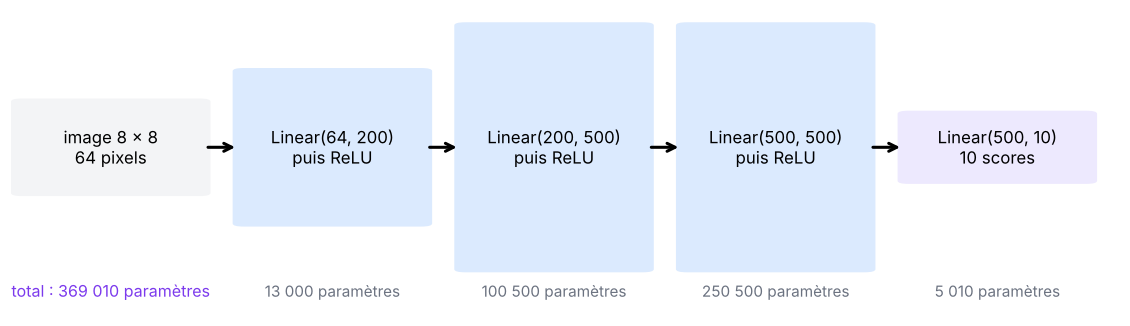

### Son entraînement : 10 000 époques, deux minutes sur un processeur. L'entraînement atteint 100 %, le test plafonne à 96,9 % : c'est le sur-apprentissage du labo 6.

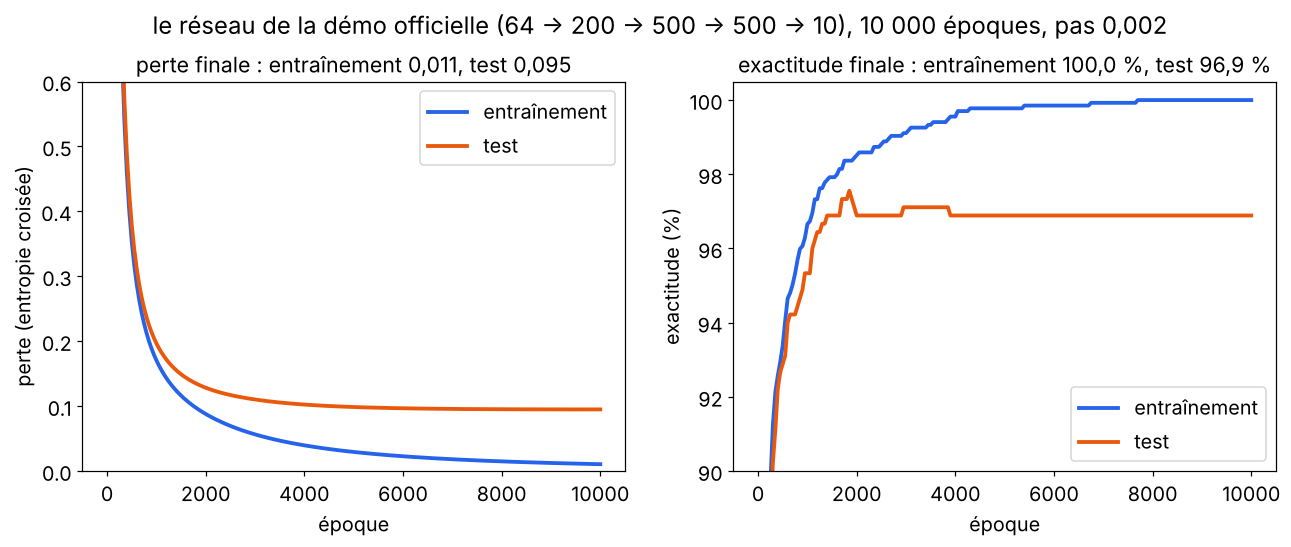

### 🔮 À vous de choisir l'architecture et le pas. Une seule couche de 32 neurones fera-t-elle beaucoup moins bien que le gros réseau ? Et avec un pas de 1 ?

In [91]:
#@title Démo E : reconnaître des chiffres, architecture et pas au choix (menus et curseurs) { display-mode: "form" }
demo_digits()

### Un petit réseau fait presque aussi bien que le gros. Facultatif, avec un GPU : le réseau officiel ; le modèle et les données sont copiés sur le GPU avec `.to(appareil)`, la boucle ne change pas. `GPU_DISPONIBLE` et `exactitude` (le pourcentage de bonnes réponses) viennent de la boîte à outils.

In [92]:
if not GPU_DISPONIBLE:
    print('Pas de GPU allumé : cellule facultative (2 minutes sur un processeur). Le résultat est dans la figure plus haut.')
else:
    appareil = torch.device('cuda')
    torch.manual_seed(0)
    gros = torch.nn.Sequential(torch.nn.Linear(64, 200), torch.nn.ReLU(), torch.nn.Linear(200, 500), torch.nn.ReLU(),
                               torch.nn.Linear(500, 500), torch.nn.ReLU(), torch.nn.Linear(500, 10)).to(appareil)
    xa, ca = digits_x_train.to(appareil), digits_c_train.to(appareil)      # les données sont copiées sur le GPU aussi
    xt, ct = digits_x_test.to(appareil), digits_c_test.to(appareil)
    perte_fn = torch.nn.CrossEntropyLoss()
    optimiseur = torch.optim.SGD(gros.parameters(), lr=2e-3)
    for epoque in range(10000):
        perte = perte_fn(gros(xa), ca)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
    with torch.no_grad():
        print('entraînement :', exactitude(gros(xa), ca), '%   test :', exactitude(gros(xt), ct), '%')

entraînement : 100.0 %   test : 96.88889384269714 %


# 9. Ce qu'il faut retenir

### À chaque étape du labo, PyTorch a pris en charge une opération de plus de la boucle d'entraînement.

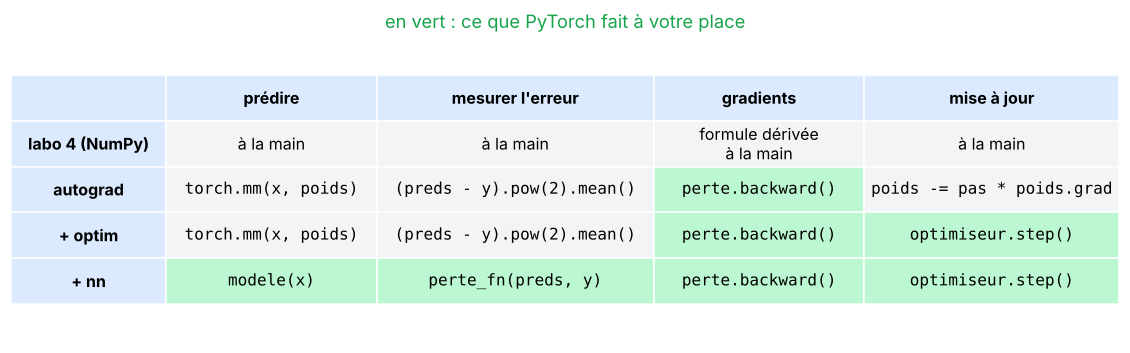

### Trois questions pour finir. 1. La perte fait n'importe quoi, sans message d'erreur : quelles deux vérifications faire d'abord ? 2. Dix couches `Linear` sans activation n'apportent rien : pourquoi ? 3. La perte d'entraînement baisse, celle de test remonte : que se passe-t-il ?

**Sources.** Démo officielle du cours, *Lab 8 : Introduction à Pytorch*. Documentation PyTorch : [tenseurs](https://pytorch.org/docs/stable/tensors.html), [diffusion](https://pytorch.org/docs/stable/notes/broadcasting.html), [autograd](https://pytorch.org/docs/stable/notes/autograd.html), [`torch.optim`](https://pytorch.org/docs/stable/optim.html), [`torch.nn`](https://pytorch.org/docs/stable/nn.html). Paszke et al. (2019), *PyTorch*, NeurIPS 32. Rumelhart, Hinton et Williams (1986), *Nature* 323. Kingma et Ba (2015), *Adam*, ICLR. Brown et al. (2020), *Language Models are Few-Shot Learners* (GPT-3, 175 milliards de paramètres), NeurIPS 33.